# Formula 1 podium prediction — Milestone 1
## 1. Data, prediction task and study design

This project predicts whether a driver will finish on the podium using information available after qualifying and before the race starts. Each row represents one driver entering one race, and the target is `positionOrder <= 3`.

The analysis covers the 14 tables in the Formula 1 World Championship dataset. It begins with missing values, data types, duplicate entries and table relationships, then answers the three data-engineering questions. The resulting pre-race features feed logistic regression, random forest and a shallow neural network. Preprocessing experiments, feature-group ablations and model explanations provide evidence for the choices made along the way.

**Historical coverage.** The main modeling table contains all 26,668 retained driver–race entries from 1950–2024. Training uses 1950–2019, validation uses 2020–2021, and the later-period assessment uses 2022–2024. A separate experiment restricts training to 2003–2019 while keeping the same validation and test races, feature definitions and tuning budget. The full-history version meets the required historical scope; the narrower version measures how much the training range affects the results.

**Input and execution.** The Kaggle input is [Formula 1 World Championship](https://www.kaggle.com/datasets/rohanrao/formula-1-world-championship-1950-2020). The setup cell checks the required packages before importing the analysis libraries and installs missing or incompatible packages when necessary. It locates the 14 CSV files in the attached input and checks their hashes against the snapshot used for this study. Local execution uses the `F1 Data` directory or `F1_DATA_DIR`. Generated tables and plots are saved under `artifacts/full_history` and `artifacts/history_comparison`; raw CSV files remain unchanged.

**Evaluation limitation.** The 2022–2024 test results were previously inspected during the modern-only analysis. The full-history comparison was introduced to satisfy the historical-scope requirement. Its model variants and thresholds are selected using validation data only, and the later-period results are reported as a repeated assessment rather than a newly untouched test. They do not determine the training range or model settings.


In [1]:
# Check dependencies before importing numerical libraries into this kernel.
import sys
import subprocess
from importlib.metadata import version, PackageNotFoundError
from packaging.requirements import Requirement

RUNTIME_REQUIREMENTS = [
    "numpy>=1.26,<3", "pandas>=2.2,<4", "matplotlib>=3.8,<4",
    "scikit-learn>=1.5,<2", "shap>=0.51,<0.54", "lime==0.2.0.1",
    "threadpoolctl>=3,<4",
]
missing_or_incompatible = []
for specification in RUNTIME_REQUIREMENTS:
    requirement = Requirement(specification)
    try:
        installed = version(requirement.name)
    except PackageNotFoundError:
        missing_or_incompatible.append(specification)
    else:
        if installed not in requirement.specifier:
            missing_or_incompatible.append(specification)
if missing_or_incompatible:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "--disable-pip-version-check", *missing_or_incompatible,
    ])
RUNTIME_VERSIONS = {
    Requirement(specification).name: version(Requirement(specification).name)
    for specification in RUNTIME_REQUIREMENTS
}
print("Runtime package versions:", RUNTIME_VERSIONS)

from pathlib import Path
import os, json, hashlib, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings',
          'drivers', 'driver_standings', 'races', 'results', 'qualifying',
          'lap_times', 'pit_stops', 'sprint_results', 'seasons', 'status']
if os.getenv('F1_DATA_DIR'):
    candidates = [Path(os.environ['F1_DATA_DIR'])]
else:
    candidates = [Path.cwd() / 'F1 Data', Path.cwd().parent / 'F1 Data']
    if Path('/kaggle/input').exists():
        candidates += [p.parent for p in Path('/kaggle/input').rglob('results.csv')]
candidates = list(dict.fromkeys(p.resolve() for p in candidates
    if all((p / f'{t}.csv').is_file() for t in TABLES)))
if len(candidates) != 1:
    raise RuntimeError(f'Expected one complete dataset; found {candidates}. The F1_DATA_DIR setting identifies a local input directory.')
DATA_DIR = candidates[0]
ROOT = Path('/kaggle/working') if Path('/kaggle/working').exists() else DATA_DIR.parent
RUN_ROOT = ROOT / 'artifacts' / 'full_history'
OUT = RUN_ROOT / 'audit'
(OUT / 'figures').mkdir(parents=True, exist_ok=True)
(OUT / 'cleaned').mkdir(exist_ok=True)
def sha256(p):
    h = hashlib.sha256()
    with p.open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()
hashes_before = {t: sha256(DATA_DIR / f'{t}.csv') for t in TABLES}
EXPECTED_INPUT_HASHES = {'circuits': '8a2ac67a0946ac238ddeaa4a212a1f3969f0108527b0213e7a38b3a5c3cba6eb', 'constructors': 'ae423f6f2d6cd74d5cd594eac0bdec7e1e9be2cda3097eb69f870294a225618c', 'constructor_results': '8f1ebc0ce822bc02326b9bf13616f22a81514a6d35e5b744fd6f627b9ef99634', 'constructor_standings': '9f07b1b9f235625165f62c6fcd6b1938cd7daa6f7e4a580f9937c6268056de9b', 'drivers': '6a894569cb031dd65fb5f113f57b235100966653eaedd9310503dc2e94afae6b', 'driver_standings': '58397ed38d29f71316ba272a2ffd5bd00b6174774d919ce079ae4d3cfb27befb', 'races': '4839d035abc603fa88fa08fa976a86d76cff35f3e94cb767d25f735a5a3376ef', 'results': 'a2392658044286800a0a946138067d9823f39e59147eeef0cbdda858ff172441', 'qualifying': '49c4ff9ae0be93d5f850f56c553d5e264914c7ba0c4d583462f3de06aebed3cc', 'lap_times': '70a772924f67682701acf1a6f26e8225ffd1b9f50844b2f9fb42ce311333cc33', 'pit_stops': '70cff48b96416d46b8f6f162e778fcee45582b8fa85e9ec4a5e2c7b60bead75c', 'sprint_results': '4a20b577098bafd2683c4f4ac1bb1cf4b2e8cc6a13c91c16878c7b2b21a24647', 'seasons': '9562d2374cced42e24988fb2325cca5c82455815a5f5d40f6a6f5262a36106dc', 'status': 'c36b1287f2421a288c38b0ce875d6ed04ff26bbda3e06db3d99e12197ea894aa'}
mismatched_inputs = [t for t in TABLES if hashes_before[t] != EXPECTED_INPUT_HASHES[t]]
assert not mismatched_inputs, f"Input snapshot differs from the study data: {mismatched_inputs}"
(OUT / 'runtime_versions.json').write_text(json.dumps(RUNTIME_VERSIONS, indent=2))

# Keep raw strings, including sentinels, so we can measure rather than hide them.
raw = {t: pd.read_csv(DATA_DIR / f'{t}.csv', dtype='string', keep_default_na=False)
       for t in TABLES}
def save_table(df, name):
    df.to_csv(OUT / f'{name}.csv', index=False)
    return df
def show_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / 'figures' / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()
print('Input:', DATA_DIR, '\nOutput:', OUT)


Runtime package versions: {'numpy': '2.5.3', 'pandas': '3.0.6', 'matplotlib': '3.11.2', 'scikit-learn': '1.9.1', 'shap': '0.53.0', 'lime': '0.2.0.1', 'threadpoolctl': '3.7.0'}


Input: /home/soryal/Youssif/College/Sem 9/ACL/ACL Project/F1 Data 
Output: /home/soryal/Youssif/College/Sem 9/ACL/ACL Project/artifacts/full_history/audit


## 2. Raw inventory and missingness
A literal `\N` or empty cell is treated as missing. Other strings are preserved. Missing Q2/Q3 times may mean a driver did not reach that session; they are not automatically errors or average lap times. Structural absence and unknown values are treated separately in the analysis.


,table,rows,columns,sentinel_cells,empty_cells,exact_duplicate_rows
0,circuits,77,9,0,0,0
1,constructors,212,5,0,0,0
2,constructor_results,12625,5,12608,0,0
3,constructor_standings,13391,7,0,0,0
4,drivers,861,9,1559,0,0
5,driver_standings,34863,7,0,0,0
6,races,1125,18,11349,0,0
7,results,26759,18,122887,0,0
8,qualifying,10494,9,11600,68,0
9,lap_times,589081,6,0,0,0


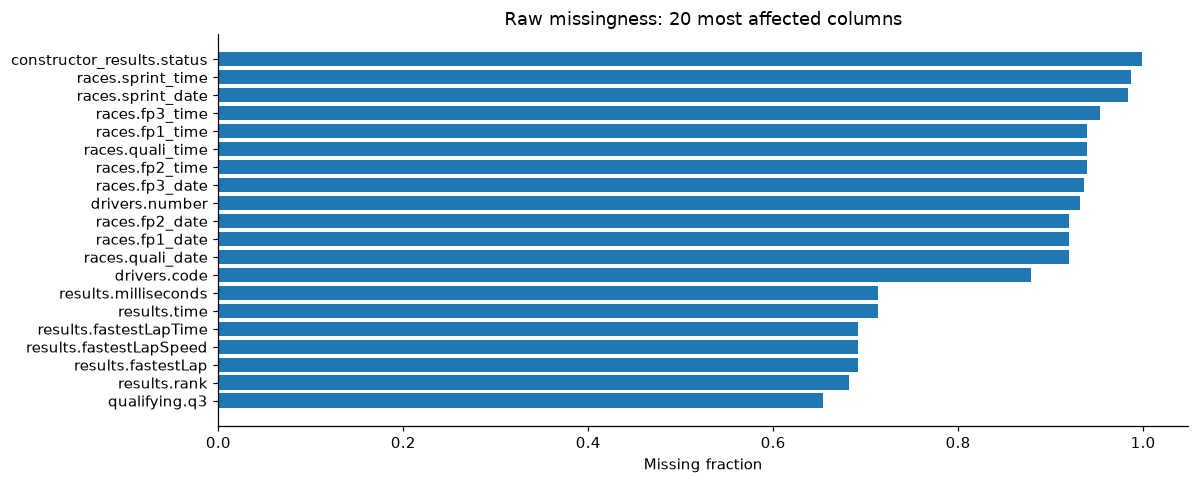

In [2]:
inventory = pd.DataFrame([{'table': t, 'rows': len(d), 'columns': len(d.columns),
    'sentinel_cells': int(d.eq(r'\N').sum().sum()),
    'empty_cells': int(d.eq('').sum().sum()),
    'exact_duplicate_rows': int(d.duplicated().sum())} for t, d in raw.items()])
display(save_table(inventory, 'raw_inventory'))
missing_rows = []
for t, d in raw.items():
    for col in d:
        n = int((d[col].eq(r'\N') | d[col].eq('')).sum())
        missing_rows.append({'table': t, 'column': col, 'missing': n,
                             'fraction': n / len(d) if len(d) else 0})
missing_before = pd.DataFrame(missing_rows)
save_table(missing_before, 'missingness_before')
top = missing_before.nlargest(20, 'fraction').sort_values('fraction')
plt.barh(top['table'] + '.' + top['column'], top['fraction'])
plt.xlabel('Missing fraction'); plt.title('Raw missingness: 20 most affected columns')
show_plot('01_raw_missingness')


## 3. Semantic typing on copies
Identifiers and whole-number quantities become nullable integers; numerical measurements become floats. Dates become timestamps. Clock times become durations since midnight, while lap and elapsed durations become seconds. We retain original duration text alongside the numeric derivative for traceability. Race result time strings beginning with `+` are gaps to the winner, not full race durations; these are exported separately from elapsed times. Every nonmissing value lost during conversion is logged and blocks progress until reviewed.


In [3]:
clean = {t: d.replace({r'\N': pd.NA, '': pd.NA}).copy(deep=True) for t, d in raw.items()}
conversion_rows = []
integer_names = {'year', 'round', 'number', 'grid', 'position', 'positionOrder',
                 'laps', 'lap', 'stop', 'rank', 'wins', 'fastestLap', 'milliseconds'}
float_names = {'lat', 'lng', 'alt', 'points', 'fastestLapSpeed'}
def record_conversion(t, col, old, new, kind):
    invalid = old.notna() & new.isna()
    conversion_rows.append({'table': t, 'column': col, 'conversion': kind,
        'invalid_nonmissing': int(invalid.sum()),
        'examples': '; '.join(old[invalid].astype(str).head(5))})
for t, d in clean.items():
    for col in list(d.columns):
        old = d[col].copy()
        if col.endswith('Id') or col in integer_names:
            new = pd.to_numeric(old, errors='coerce').astype('Int64')
            record_conversion(t, col, old, new, 'nullable integer'); d[col] = new
        elif col in float_names:
            new = pd.to_numeric(old, errors='coerce').astype('Float64')
            record_conversion(t, col, old, new, 'nullable float'); d[col] = new
        elif col == 'date' or col == 'dob' or col.endswith('_date'):
            new = pd.to_datetime(old, errors='coerce', format='%Y-%m-%d')
            record_conversion(t, col, old, new, 'date'); d[col] = new
        elif (t == 'races' and (col == 'time' or col.endswith('_time'))) or (t == 'pit_stops' and col == 'time'):
            new = pd.to_timedelta(old.astype(object).where(old.notna(), None), errors='coerce')
            record_conversion(t, col, old, new, 'clock time'); d[col] = new

def duration_seconds(value):
    if pd.isna(value): return np.nan
    text = str(value).strip().removeprefix('+')
    if not re.fullmatch(r'\d+(?::\d+){0,2}(?:\.\d+)?', text): return np.nan
    total = 0.0
    for part in text.split(':'): total = total * 60 + float(part)
    return total
for t, cols in {'qualifying': ['q1', 'q2', 'q3'], 'lap_times': ['time'],
                'pit_stops': ['duration'], 'results': ['time', 'fastestLapTime'],
                'sprint_results': ['time', 'fastestLapTime']}.items():
    for col in cols:
        old = clean[t][col]
        new = old.map(duration_seconds).astype(float)
        record_conversion(t, col, old, new, 'duration seconds')
        if col == 'time' and t in {'results', 'sprint_results'}:
            is_gap = old.str.startswith('+').fillna(False)
            clean[t]['time_gap_seconds'] = new.where(is_gap)
            clean[t]['time_elapsed_seconds'] = new.where(~is_gap)
        else:
            clean[t][col + '_seconds'] = new
conversion_audit = pd.DataFrame(conversion_rows)
display(save_table(conversion_audit, 'conversion_audit'))
assert conversion_audit['invalid_nonmissing'].sum() == 0, 'Review failed conversions.'


,table,column,conversion,invalid_nonmissing,examples
0,circuits,circuitId,nullable integer,0,
1,circuits,lat,nullable float,0,
2,circuits,lng,nullable float,0,
3,circuits,alt,nullable float,0,
4,constructors,constructorId,nullable integer,0,
...,...,...,...,...,...
91,pit_stops,duration,duration seconds,0,
92,results,time,duration seconds,0,
93,results,fastestLapTime,duration seconds,0,
94,sprint_results,time,duration seconds,0,


## 4. Relational integrity
The audit checks declared primary keys, including composite lap/stop keys. Every referenced driver, constructor, race, circuit, season and status must exist. Missing optional references are reported separately from orphan values. Later joins specify their expected cardinality to prevent accidental row multiplication.


In [4]:
PK = {'circuits': ['circuitId'], 'constructors': ['constructorId'],
      'constructor_results': ['constructorResultsId'], 'constructor_standings': ['constructorStandingsId'],
      'drivers': ['driverId'], 'driver_standings': ['driverStandingsId'], 'races': ['raceId'],
      'results': ['resultId'], 'qualifying': ['qualifyId'], 'lap_times': ['raceId','driverId','lap'],
      'pit_stops': ['raceId','driverId','stop'], 'sprint_results': ['resultId'],
      'seasons': ['year'], 'status': ['statusId']}
pk_audit = pd.DataFrame([{'table': t, 'key': ','.join(keys),
    'null_key_rows': int(clean[t][keys].isna().any(axis=1).sum()),
    'duplicate_key_rows': int(clean[t].duplicated(keys, keep=False).sum())}
    for t, keys in PK.items()])
display(save_table(pk_audit, 'primary_keys'))
parents = {'driverId': 'drivers', 'constructorId': 'constructors', 'raceId': 'races',
           'circuitId': 'circuits', 'statusId': 'status', 'year': 'seasons'}
fk_rows = []
for t, d in clean.items():
    for col, parent in parents.items():
        if col in d and t != parent:
            orphan = d[col].notna() & ~d[col].isin(clean[parent][col])
            fk_rows.append({'table': t, 'column': col, 'parent': parent,
                'null_rows': int(d[col].isna().sum()), 'orphan_rows': int(orphan.sum())})
fk_audit = pd.DataFrame(fk_rows)
display(save_table(fk_audit, 'foreign_keys'))
assert pk_audit[['null_key_rows','duplicate_key_rows']].to_numpy().sum() == 0
assert fk_audit['orphan_rows'].sum() == 0
# These business grains are needed for safe joins, beyond the declared surrogate PKs.
business_rows = []
for t, keys in {'qualifying':['raceId','driverId'],
                'driver_standings':['raceId','driverId'],
                'constructor_standings':['raceId','constructorId'],
                'constructor_results':['raceId','constructorId']}.items():
    business_rows.append({'table':t, 'key':','.join(keys),
                         'duplicate_rows': int(clean[t].duplicated(keys, keep=False).sum())})
business_audit = pd.DataFrame(business_rows)
display(save_table(business_audit, 'join_grains'))
assert business_audit['duplicate_rows'].sum() == 0


,table,key,null_key_rows,duplicate_key_rows
0,circuits,circuitId,0,0
1,constructors,constructorId,0,0
2,constructor_results,constructorResultsId,0,0
3,constructor_standings,constructorStandingsId,0,0
4,drivers,driverId,0,0
5,driver_standings,driverStandingsId,0,0
6,races,raceId,0,0
7,results,resultId,0,0
8,qualifying,qualifyId,0,0
9,lap_times,"raceId,driverId,lap",0,0


,table,column,parent,null_rows,orphan_rows
0,constructor_results,constructorId,constructors,0,0
1,constructor_results,raceId,races,0,0
2,constructor_standings,constructorId,constructors,0,0
3,constructor_standings,raceId,races,0,0
4,driver_standings,driverId,drivers,0,0
5,driver_standings,raceId,races,0,0
6,races,circuitId,circuits,0,0
7,races,year,seasons,0,0
8,results,driverId,drivers,0,0
9,results,constructorId,constructors,0,0


,table,key,duplicate_rows
0,qualifying,"raceId,driverId",0
1,driver_standings,"raceId,driverId",0
2,constructor_standings,"raceId,constructorId",0
3,constructor_results,"raceId,constructorId",0


## 5. Driver–race duplicates and the retained grain
**Policy:** prefer a row with a recorded positive grid; break ties by the smallest `resultId`. If every row has a zero/missing grid, use the smallest `resultId`. This avoids choosing the feature row using finishing position. A positive grid is evidence of a recorded grid assignment, not proof of an actual start.

The retained row supplies both the label and its associated constructor/grid. We do not combine a best outcome from one car with the starting features of another. This deliberately changes the interpretation of historical shared drives to the retained entry; it can miss a podium earned in another car. The comparison below quantifies that sensitivity. These historical entries remain part of the full-history training set.

All discarded rows and the selected result ID are exported. Duplicates are not automatically labeled errors or shared drives without historical evidence.


Duplicate groups: 85 
Extra rows removed: 91 
Retained entries: 26668 
Labels different from any-car podium policy: 16


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,...,rank,fastestLapTime,fastestLapSpeed,statusId,time_gap_seconds,time_elapsed_seconds,fastestLapTime_seconds,year,selected_resultId,kept
0,13189,540,229,54,10,0,<NA>,F,26,0.0,...,<NA>,<NA>,<NA>,81,NaN,NaN,NaN,1978,13189,True
1,13192,540,229,57,23,0,<NA>,F,29,0.0,...,<NA>,<NA>,<NA>,97,NaN,NaN,NaN,1978,13189,False
2,17363,717,373,172,1,1,7,7,7,0.0,...,<NA>,<NA>,<NA>,60,NaN,NaN,NaN,1964,17363,True
3,17741,733,465,172,48,0,<NA>,W,22,0.0,...,<NA>,<NA>,<NA>,54,NaN,NaN,NaN,1962,17741,True
4,17744,733,465,97,50,0,<NA>,W,25,0.0,...,<NA>,<NA>,<NA>,54,NaN,NaN,NaN,1962,17741,False
5,17962,742,475,102,26,20,<NA>,D,19,0.0,...,<NA>,<NA>,<NA>,2,NaN,NaN,NaN,1961,17962,True
6,17964,742,475,172,28,5,<NA>,R,21,0.0,...,<NA>,<NA>,<NA>,23,NaN,NaN,NaN,1961,17962,False
7,18063,745,418,172,22,11,<NA>,R,17,0.0,...,<NA>,<NA>,<NA>,6,NaN,NaN,NaN,1961,18063,True
8,18083,746,475,170,36,1,<NA>,R,17,0.0,...,<NA>,<NA>,<NA>,22,NaN,NaN,NaN,1960,18083,True
9,18510,766,541,87,22,0,<NA>,F,17,0.0,...,<NA>,<NA>,<NA>,81,NaN,NaN,NaN,1958,18510,True


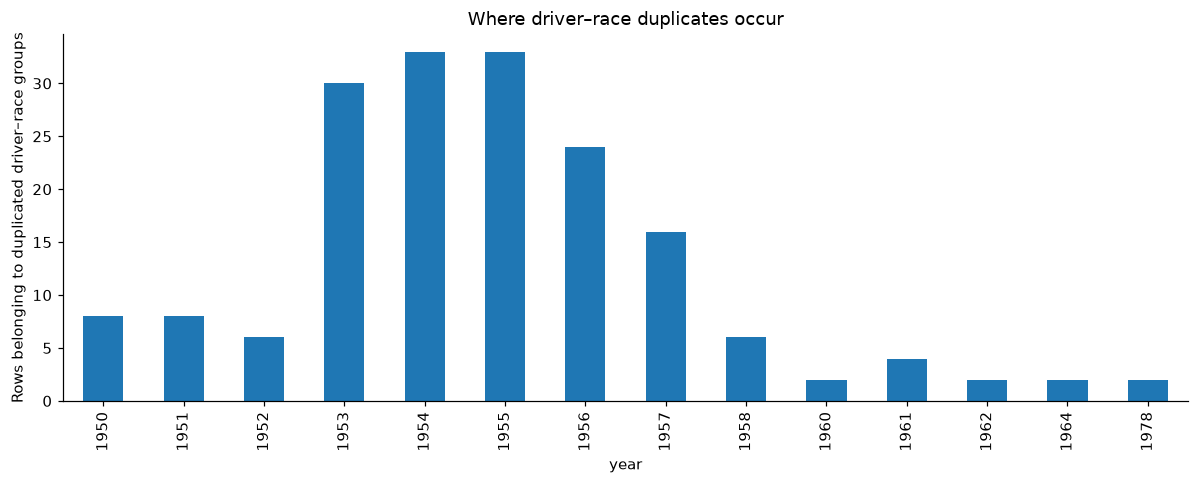

Duplicate year range: 1950 – 1978


In [5]:
results = clean['results'].copy()
keys = ['raceId', 'driverId']
dup_mask = results.duplicated(keys, keep=False)
duplicates = results.loc[dup_mask].merge(clean['races'][['raceId','year']], on='raceId', validate='many_to_one')
# Stable sorting gives a reproducible outcome independent of CSV row order.
ranked = results.assign(_positive_grid=results['grid'].gt(0).fillna(False)).sort_values(
    keys + ['_positive_grid','resultId'], ascending=[True, True, False, True], kind='stable')
entries = ranked.drop_duplicates(keys).drop(columns='_positive_grid').copy()
entries['podium'] = entries['positionOrder'].le(3).astype('int8')
assert not entries.duplicated(keys).any()
selected = entries[keys + ['resultId']].rename(columns={'resultId':'selected_resultId'})
duplicate_log = duplicates.merge(selected, on=keys, validate='many_to_one')
duplicate_log['kept'] = duplicate_log['resultId'].eq(duplicate_log['selected_resultId'])
save_table(duplicate_log, 'duplicate_decisions')
best = results.assign(any_entry_podium=results['positionOrder'].le(3)).groupby(keys)['any_entry_podium'].max()
sensitivity = entries.set_index(keys)[['podium']].join(best)
label_disagreements = int(sensitivity['podium'].ne(sensitivity['any_entry_podium']).sum())
print('Duplicate groups:', duplicates.groupby(keys).ngroups,
      '\nExtra rows removed:', len(results)-len(entries),
      '\nRetained entries:', len(entries),
      '\nLabels different from any-car podium policy:', label_disagreements)
display(duplicate_log.head(15))
if len(duplicates):
    duplicates.groupby('year').size().plot.bar()
    plt.ylabel('Rows belonging to duplicated driver–race groups')
    plt.title('Where driver–race duplicates occur'); show_plot('02_duplicate_years')
    print('Duplicate year range:', duplicates['year'].min(), '–', duplicates['year'].max())


## 6. Outcome semantics and unusual grid values
`D` (disqualified) and `N` (not classified) do not necessarily mean “did not start,” so these outcomes remain in the data. A zero grid does not establish a non-start: pit-lane starters and other cases can share that value. Zero laps is also insufficient evidence: a driver can retire before completing a lap.

All outcomes remain in this entry-level audit. The mechanical-retirement analysis uses a separately justified **actual-start denominator**. Outcome/status fields below are audit data and eventual labels, never current-race prediction features.


,positionText,status,entries,zero_grid,positive_laps
608,R,Engine,1856,0,1822
0,1,Finished,1125,0,1125
332,2,Finished,1100,0,1100
565,F,Did not qualify,1024,1012,1
400,3,Finished,993,0,993
583,R,Accident,955,2,733
415,4,Finished,862,0,862
593,R,Collision,801,0,452
623,R,Gearbox,765,0,739
656,R,Spun off,750,0,713


,status,entries
0,Did not qualify,1012
1,Did not prequalify,330
2,Withdrew,163
3,+1 Lap,27
4,Finished,22
5,Accident,20
6,Injury,8
7,+2 Laps,7
8,Excluded,6
9,Engine,6


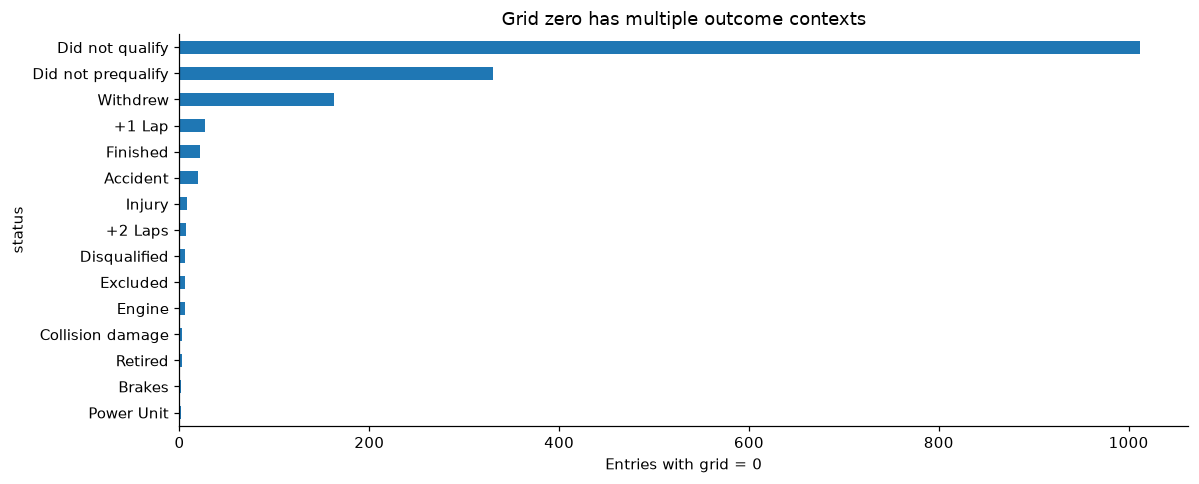

,check,count
0,positionOrder missing or below 1,0
1,grid missing,0
2,negative grid,0
3,negative laps,0
4,qualifying position missing or below 1,0


In [6]:
entry_audit = entries.merge(clean['races'][['raceId','year','round','date','circuitId','name']],
                           on='raceId', validate='many_to_one').merge(
                           clean['status'], on='statusId', validate='many_to_one')
assert len(entry_audit) == len(entries)
status_summary = entry_audit.groupby(['positionText','status'], dropna=False).agg(
    entries=('resultId','size'), zero_grid=('grid', lambda x: int(x.eq(0).sum())),
    positive_laps=('laps', lambda x: int(x.gt(0).sum()))).reset_index()
display(save_table(status_summary, 'outcome_status_summary').sort_values('entries', ascending=False).head(25))
zero_grid = entry_audit.loc[entry_audit['grid'].eq(0)].groupby('status').size().sort_values(ascending=False)
display(save_table(zero_grid.rename('entries').reset_index(), 'zero_grid_statuses').head(20))
zero_grid.head(15).sort_values().plot.barh()
plt.xlabel('Entries with grid = 0'); plt.title('Grid zero has multiple outcome contexts')
show_plot('03_zero_grid_context')
range_checks = pd.DataFrame([
 {'check':'positionOrder missing or below 1', 'count':int((results['positionOrder'].isna() | results['positionOrder'].lt(1)).sum())},
 {'check':'grid missing', 'count':int(results['grid'].isna().sum())},
 {'check':'negative grid', 'count':int(results['grid'].lt(0).sum())},
 {'check':'negative laps', 'count':int(results['laps'].lt(0).sum())},
 {'check':'qualifying position missing or below 1', 'count':int((clean['qualifying']['position'].isna() | clean['qualifying']['position'].lt(1)).sum())}
])
display(save_table(range_checks, 'range_checks'))
assert range_checks['count'].sum() == 0, 'Unexpected range values require review.'


## 7. Qualifying coverage — race level and driver level
A race having at least one qualifying record does not mean every entry has one. The join uses `(raceId, driverId)` and separately measures matched records, available qualifying position, and recorded Q1/Q2/Q3 durations. Later-session missingness is expected for eliminated drivers.

The denominator is retained result entries. Missing records may include non-qualifiers or withdrawals, so missingness alone does not establish a recording error. The 2003 marker describes the preserved narrower benchmark; it is not a row exclusion in the full-history model.


,year,entries,record_coverage,position_coverage,q1_coverage,q2_coverage,q3_coverage,race_coverage
50,2000,373,0.235925,0.235925,0.235925,0.000000,0.000000,0.235294
51,2001,374,0.058824,0.058824,0.058824,0.000000,0.000000,0.058824
52,2002,362,0.116022,0.116022,0.116022,0.000000,0.000000,0.117647
53,2003,320,1.000000,1.000000,0.965625,0.000000,0.000000,1.0
54,2004,360,1.000000,1.000000,0.941667,0.000000,0.000000,1.0
55,2005,376,1.000000,1.000000,0.954787,0.284574,0.000000,1.0
56,2006,396,1.000000,1.000000,0.979798,0.717172,0.444444,1.0
57,2007,374,1.000000,1.000000,0.994652,0.711230,0.451872,1.0
58,2008,368,1.000000,1.000000,0.994565,0.733696,0.478261,1.0
59,2009,340,1.000000,1.000000,0.997059,0.738235,0.491176,1.0


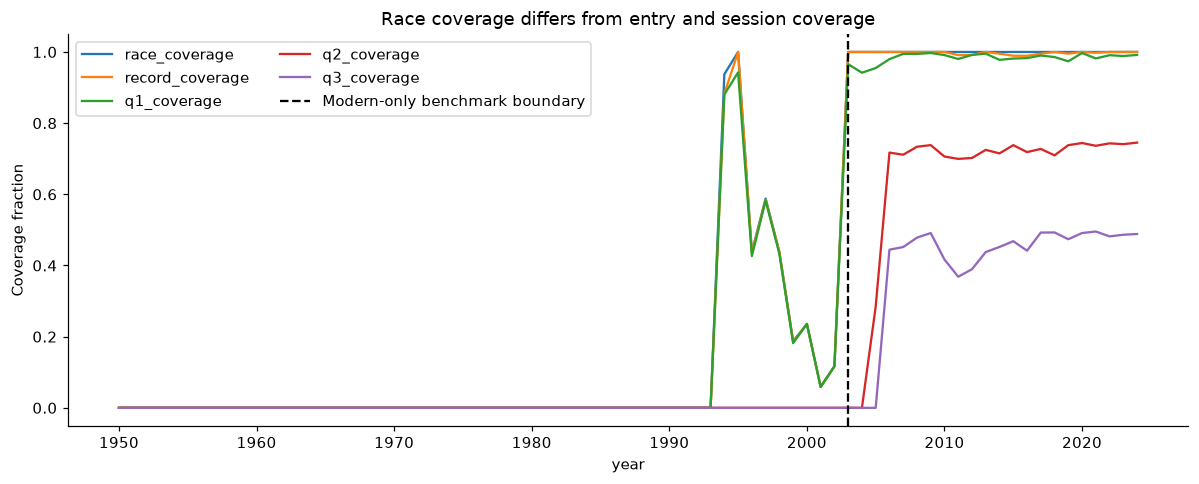

Races with partial entry coverage: 41


,raceId,year,entries,matched,partial
873,875,2012,24,23,True
915,918,2014,20,18,True
917,927,2015,20,19,True
919,929,2015,20,19,True
922,932,2015,20,19,True
930,941,2015,20,19,True
941,954,2016,22,21,True
944,957,2016,22,21,True
947,960,2016,22,21,True
948,961,2016,22,21,True


Constructor mismatches between results and qualifying: 10


In [7]:
q = clean['qualifying'].rename(columns={'position':'qualifying_position', 'constructorId':'qualifying_constructorId'})
coverage = entry_audit.merge(q[keys + ['qualifyId','qualifying_position','qualifying_constructorId',
                                   'q1_seconds','q2_seconds','q3_seconds']],
                            on=keys, how='left', validate='one_to_one')
assert len(coverage) == len(entries)
coverage['has_qualifying_record'] = coverage['qualifyId'].notna()
coverage['has_qualifying_position'] = coverage['qualifying_position'].notna()
for col in ['q1','q2','q3']:
    coverage['has_' + col] = coverage[col+'_seconds'].notna()
season_coverage = coverage.groupby('year').agg(entries=('resultId','size'),
    record_coverage=('has_qualifying_record','mean'), position_coverage=('has_qualifying_position','mean'),
    q1_coverage=('has_q1','mean'), q2_coverage=('has_q2','mean'), q3_coverage=('has_q3','mean')).reset_index()
race_coverage = coverage.groupby(['raceId','year']).agg(entries=('resultId','size'),
    matched=('has_qualifying_record','sum')).reset_index()
race_coverage['partial'] = race_coverage['matched'].gt(0) & race_coverage['matched'].lt(race_coverage['entries'])
race_fraction = clean['races'].assign(has_q=clean['races']['raceId'].isin(q['raceId'])).groupby('year')['has_q'].mean()
season_coverage = season_coverage.merge(race_fraction.rename('race_coverage'), on='year', validate='one_to_one')
save_table(season_coverage, 'qualifying_coverage_by_year')
save_table(race_coverage, 'qualifying_coverage_by_race')
save_table(coverage.loc[~coverage['has_qualifying_record'], keys+['year','name','positionText','status']], 'missing_qualifying_entries')
display(season_coverage.tail(25))
season_coverage.set_index('year')[['race_coverage','record_coverage','q1_coverage','q2_coverage','q3_coverage']].plot()
plt.axvline(2003, color='black', linestyle='--', label='Modern-only benchmark boundary')
plt.ylabel('Coverage fraction'); plt.title('Race coverage differs from entry and session coverage')
plt.legend(ncol=2); show_plot('04_qualifying_coverage')
print('Races with partial entry coverage:', int(race_coverage['partial'].sum()))
display(race_coverage.loc[race_coverage['partial']].tail(15))
constructor_mismatch = coverage['qualifying_constructorId'].notna() & coverage['constructorId'].ne(coverage['qualifying_constructorId'])
save_table(coverage.loc[constructor_mismatch, keys+['year','constructorId','qualifying_constructorId']], 'qualifying_constructor_mismatches')
print('Constructor mismatches between results and qualifying:', int(constructor_mismatch.sum()))


## 8. Before/after EDA and training-period feature evidence
The comparison covers raw result rows and the retained entry table. All rates and labels are computed, not hard-coded. An era-level base rate does not prove that historical car performance or driver relationships generalize to modern F1.

Evidence for the grid-feature hypothesis uses training years 1950–2019 only and reports both the observed podium rate and sample count. Association is not causation and does not establish which feature will be most useful in a fitted model.


,stage,rows,duplicate_extra_rows,podium_count,podium_rate
0,Raw result rows,26759,91,3397,0.126948
1,Retained driver–race entries,26668,0,3379,0.126706


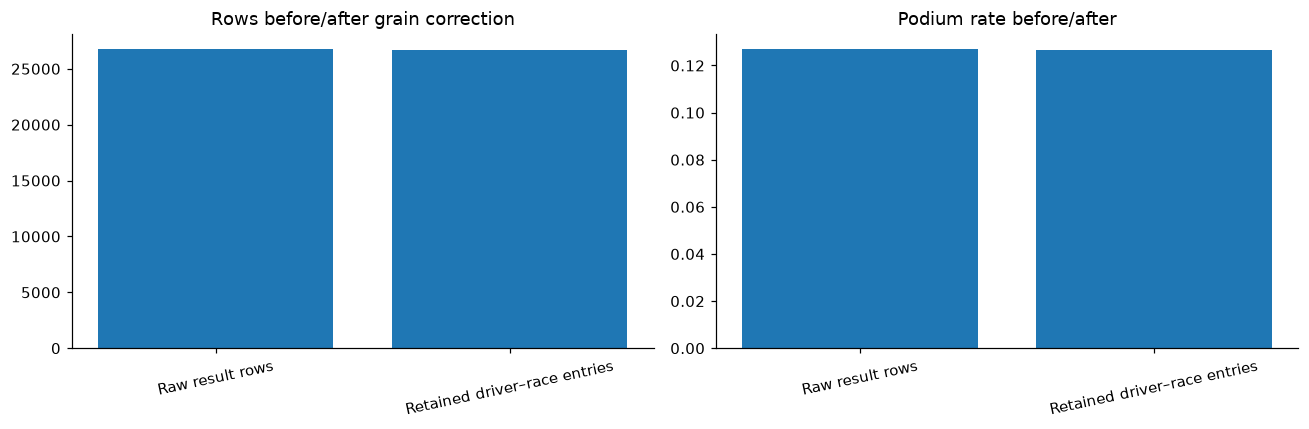

Sentinels were converted to nulls, not imputed; original-column missing counts are unchanged.


,year,size,sum,mean
0,1950–1979,7836,988,0.126085
1,1980–2000,9126,1005,0.110125
2,2001–2013,5080,702,0.138189
3,2014–2024,4626,684,0.147860


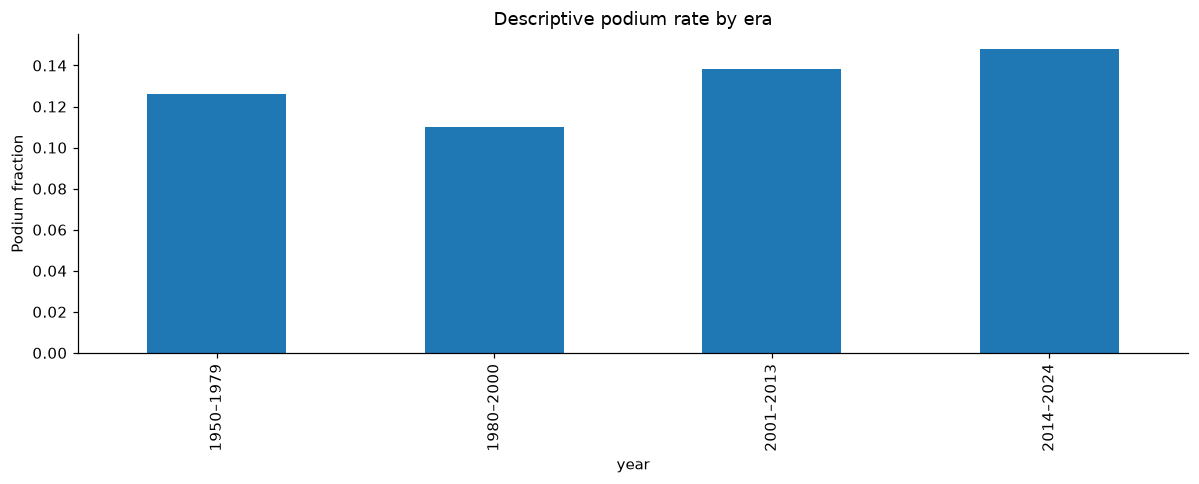

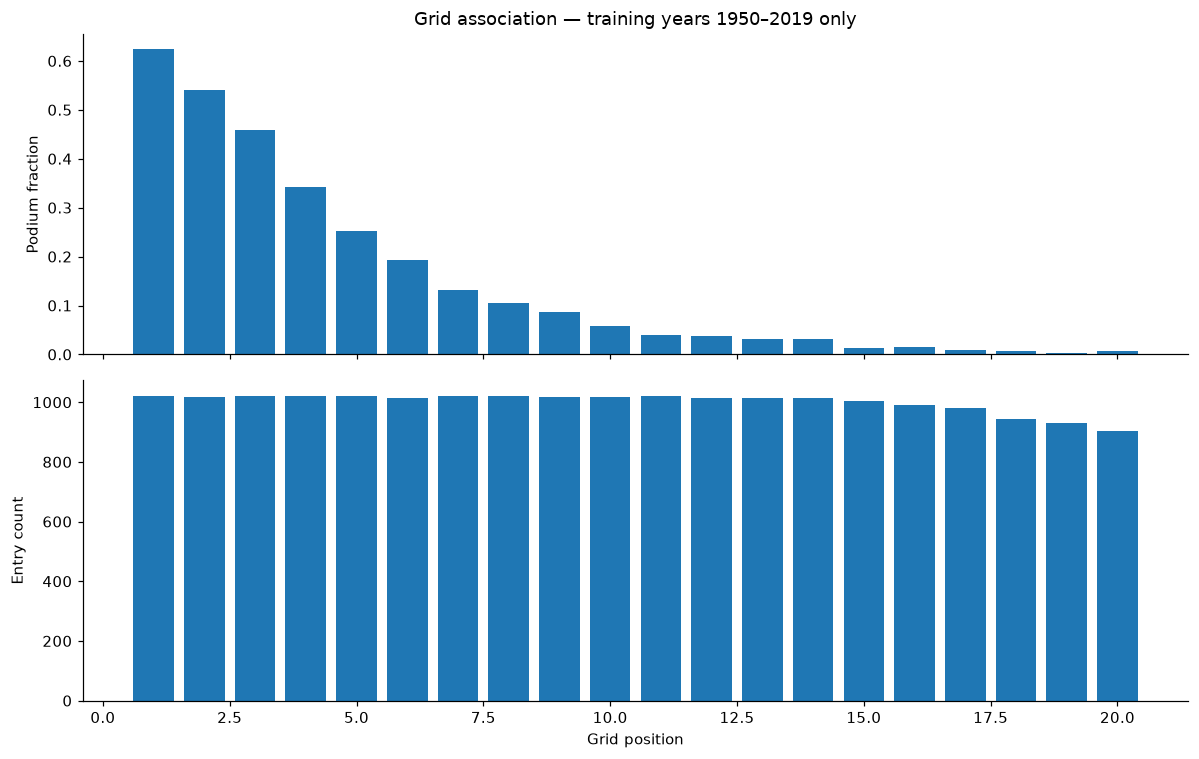

In [8]:
comparison = pd.DataFrame([
 {'stage':'Raw result rows', 'rows':len(results), 'duplicate_extra_rows':int(results.duplicated(keys).sum()),
  'podium_count':int(results['positionOrder'].le(3).sum()), 'podium_rate':float(results['positionOrder'].le(3).mean())},
 {'stage':'Retained driver–race entries', 'rows':len(entries), 'duplicate_extra_rows':int(entries.duplicated(keys).sum()),
  'podium_count':int(entries['podium'].sum()), 'podium_rate':float(entries['podium'].mean())}
])
display(save_table(comparison, 'before_after_grain'))
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].bar(comparison['stage'], comparison['rows']); axes[0].set_title('Rows before/after grain correction')
axes[1].bar(comparison['stage'], comparison['podium_rate']); axes[1].set_title('Podium rate before/after')
for ax in axes: ax.tick_params(axis='x', rotation=12)
show_plot('05_before_after')
missing_after = pd.DataFrame([{'table':t, 'column':col, 'missing':int(d[col].isna().sum()),
    'fraction':float(d[col].isna().mean())} for t,d in clean.items() for col in raw[t].columns])
save_table(missing_after, 'missingness_after')
missing_compare = missing_before.merge(missing_after, on=['table','column'], suffixes=('_before','_after'))
assert missing_compare['missing_before'].eq(missing_compare['missing_after']).all()
print('Sentinels were converted to nulls, not imputed; original-column missing counts are unchanged.')
era = pd.cut(entry_audit['year'], bins=[1949,1979,2000,2013,2024],
             labels=['1950–1979','1980–2000','2001–2013','2014–2024'])
era_summary = entry_audit.groupby(era, observed=True)['podium'].agg(['size','sum','mean']).reset_index()
display(save_table(era_summary, 'podium_by_era'))
era_summary.plot.bar(x='year', y='mean', legend=False)
plt.ylabel('Podium fraction'); plt.title('Descriptive podium rate by era'); show_plot('06_podium_by_era')
train_eda = coverage.loc[coverage['year'].between(1950,2019)]
grid_summary = train_eda.loc[train_eda['grid'].between(1,20)].groupby('grid')['podium'].agg(['size','sum','mean']).reset_index()
save_table(grid_summary, 'training_grid_evidence')
fig, axes = plt.subplots(2,1, figsize=(11,7), sharex=True)
axes[0].bar(grid_summary['grid'],grid_summary['mean']); axes[0].set_ylabel('Podium fraction')
axes[0].set_title('Grid association — training years 1950–2019 only')
axes[1].bar(grid_summary['grid'],grid_summary['size']); axes[1].set_ylabel('Entry count'); axes[1].set_xlabel('Grid position')
show_plot('07_training_grid_evidence')


## 9. Leakage boundary and chronological split
This audit exports an **entry audit table**, not a feature-ready modeling table: it deliberately contains current-race outcomes for inspection. Modeling uses an explicit pre-race feature allowlist to exclude these outcomes.

| Field/group | Later modeling treatment |
|---|---|
| Current qualifying position and recorded sessions | Allowed before main race; distinguish session absence and sprint-weekend format |
| Current grid | Allowed by the brief; zero needs explicit encoding; actual pre-race availability is assumed from retrospective data |
| Driver/constructor form | Past completed races only; aggregate constructor cars by race **before** shifting |
| Championship standings | Prior race in the same season; define season-opening and newcomer defaults |
| Current positionOrder | Target only |
| Current points, position, positionText, laps, status, race times, fastest laps, pit stops | Forbidden current-race features |
| IDs | Join keys; any categorical identity feature needs separate justification |
| Sprint results | Defer until timing/format and availability are explicitly verified |

Full-history split: train 1950–2019, validation 2020–2021, test 2022–2024, grouped by whole race. All entry outcomes are retained; future failures and disqualifications do not determine eligibility. The revised model, feature and threshold comparisons exclude the previously exposed test period. Full-history descriptive questions may use outcomes but are not feature-selection experiments.

Sections 11–17 implement the three relational questions and past-only features. Sections 18–26 compare logistic regression, random forest, and a shallow neural network; report validation and held-out test scores; run preprocessing and ablation experiments; and explain and demonstrate inference.


In [9]:
split = np.select([coverage['year'].between(1950,2019).to_numpy(dtype=bool),
                   coverage['year'].between(2020,2021).to_numpy(dtype=bool),
                   coverage['year'].between(2022,2024).to_numpy(dtype=bool)],
                  ['train','validation','test'], default='outside supplied range')
coverage['proposed_split'] = split
split_summary = coverage.groupby('proposed_split').agg(entries=('resultId','size'),
    races=('raceId','nunique'), first_year=('year','min'), last_year=('year','max'),
    qualifying_coverage=('has_qualifying_record','mean')).reset_index()
display(save_table(split_summary, 'proposed_split'))
assert coverage.groupby('raceId')['proposed_split'].nunique().max() == 1
modern_duplicates = int(duplicates['year'].ge(2003).sum())
print('Duplicate source rows from 2003 onward:', modern_duplicates)
assert modern_duplicates == 0, 'Reconsider modern duplicate assumptions.'

assert not coverage['proposed_split'].eq('outside supplied range').any()
assert len(coverage) == 26668


,proposed_split,entries,races,first_year,last_year,qualifying_coverage
0,test,1359,68,2022,2024,1.000000
1,train,24529,1018,1950,2019,0.340658
2,validation,780,39,2020,2021,0.998718


Duplicate source rows from 2003 onward: 0


## 10. Export and reproducibility check
Cleaned source tables preserve their original grains; `entries_unique.csv` separately applies the documented driver–race rule. The audit table includes forbidden modeling columns and is labeled accordingly. The JSON summary and CSV audit logs provide machine-readable evidence. No input file is overwritten.


In [10]:
for t, d in clean.items():
    d.to_csv(OUT / 'cleaned' / f'{t}.csv', index=False)
entries.to_csv(OUT / 'cleaned' / 'entries_unique.csv', index=False)
coverage.to_csv(OUT / 'entry_audit_NOT_model_features.csv', index=False)
hashes_after = {t: sha256(DATA_DIR / f'{t}.csv') for t in TABLES}
assert hashes_before == hashes_after, 'Input CSVs changed during execution.'
summary = {'input_hashes_sha256': hashes_before,
    'table_count': len(raw), 'raw_result_rows': len(results), 'unique_entry_rows': len(entries),
    'duplicate_groups': int(duplicates.groupby(keys).ngroups),
    'removed_duplicate_rows': len(results)-len(entries),
    'duplicate_label_policy_disagreements': label_disagreements,
    'primary_key_violations': int(pk_audit[['null_key_rows','duplicate_key_rows']].to_numpy().sum()),
    'foreign_key_orphan_rows': int(fk_audit['orphan_rows'].sum()),
    'conversion_failures': int(conversion_audit['invalid_nonmissing'].sum()),
    'races_with_partial_qualifying_coverage': int(race_coverage['partial'].sum()),
    'qualifying_constructor_mismatches': int(constructor_mismatch.sum()),
    'raw_inputs_unchanged': hashes_before == hashes_after}
(OUT / 'audit_summary.json').write_text(json.dumps(summary, indent=2))
display(Markdown(f"**Audit completed:** {len(raw)} tables; {len(results):,} raw result rows → "
    f"{len(entries):,} unique entries. {summary['duplicate_groups']} duplicate groups; "
    f"{summary['removed_duplicate_rows']} extra rows removed. "
    f"{summary['races_with_partial_qualifying_coverage']} races have partial qualifying-record coverage. "
    "Raw input hashes are unchanged. See exported logs for limitations and policy effects."))


**Audit completed:** 14 tables; 26,759 raw result rows → 26,668 unique entries. 85 duplicate groups; 91 extra rows removed. 41 races have partial qualifying-record coverage. Raw input hashes are unchanged. See exported logs for limitations and policy effects.

# 11. Relational analysis: shared definitions
The three questions use the unique driver–race entries from the audit, joined to race, circuit, driver, constructor and status dimensions with explicit join cardinality. Outcomes are allowed for these retrospective questions; they are not automatically allowed as prediction features.

Indianapolis **500 events** (1950–1960) are excluded from Questions 1 and 2 as a different racing context. Later United States Grands Prix at the same circuit remain included. Historical duplicate policy and retrospective classification remain limitations. Rates are descriptive associations, not causal estimates.

Small-sample rankings are unstable. Question 1 requires at least 20 front-row entries per circuit/era for a displayed ranking. Tables retain every circuit, including those below the threshold. Wilson intervals describe binomial uncertainty only; paired drivers within a race and temporal dependence can make those intervals optimistic.


In [11]:
ANALYSIS = RUN_ROOT / 'analysis'
FEATURES = RUN_ROOT / 'features'
for folder in [ANALYSIS, FEATURES]:
    (folder / 'figures').mkdir(parents=True, exist_ok=True)
def analysis_table(df, name):
    df.to_csv(ANALYSIS / f'{name}.csv', index=False)
    return df
def analysis_plot(name):
    plt.tight_layout(); plt.savefig(ANALYSIS / 'figures' / f'{name}.png', bbox_inches='tight')
    plt.show(); plt.close()
def wilson(k, n):
    n = np.asarray(n, dtype=float); k = np.asarray(k, dtype=float)
    rate = np.divide(k, n, out=np.zeros_like(k), where=n>0)
    z = 1.95996398454
    den = 1 + z*z / np.maximum(n, 1)
    mid = (rate + z*z/(2*np.maximum(n, 1))) / den
    half = z * np.sqrt(rate*(1-rate)/np.maximum(n,1)+z*z/(4*np.maximum(n,1)**2))/den
    return np.where(n>0, mid-half, np.nan), np.where(n>0, mid+half, np.nan)
analysis = coverage.merge(clean['circuits'][['circuitId','name','country','circuitRef']].rename(
    columns={'name':'circuit_name','country':'circuit_country'}), on='circuitId', validate='many_to_one')
analysis = analysis.merge(clean['drivers'][['driverId','forename','surname','nationality','dob']],
                          on='driverId', validate='many_to_one')
analysis = analysis.merge(clean['constructors'][['constructorId','name']].rename(
    columns={'name':'constructor_name'}), on='constructorId', validate='many_to_one')
assert len(analysis) == len(entries)
analysis['era2014'] = np.where(analysis['year'].lt(2014), '1950–2013', '2014–2024')
analysis['is_indy500'] = analysis['name'].eq('Indianapolis 500')
print('Excluded Indy 500 entries for Q1/Q2:', int(analysis['is_indy500'].sum()))


Excluded Indy 500 entries for Q1/Q2: 381


## 12. Question 1 — which circuits convert a front row into a podium?
**Grain/denominator:** retained driver–race entries with recorded grid 1 or 2, grouped by circuit and era. Qualifying-front-row conversion is a separate measure with its own denominator (qualifying position 1 or 2). Qualifying results are not substituted for grid.

The historical grid comparison uses all available years. Because qualifying coverage changes sharply, a second 2003–2024 comparison uses only rows with both positions recorded. Rankings before/after 2014 are also compared on circuits eligible in **both** eras, so circuit turnover is not mistaken for a rank change. Sprint formats and penalties can both cause a grid/qualifying difference; the difference is not labeled a penalty.


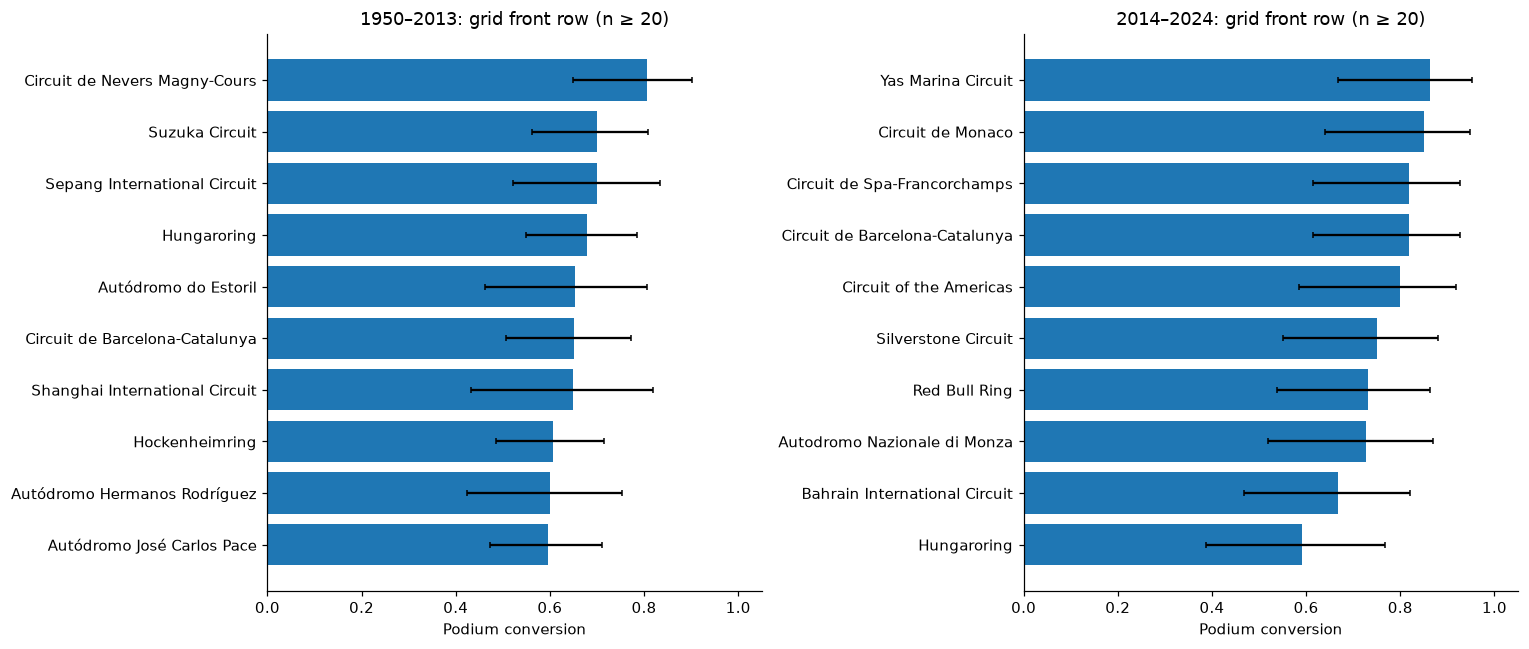

,circuitId,circuit_name,rate_1950–2013,rate_2014–2024,common_rank_1950–2013,common_rank_2014–2024,entries_1950–2013,entries_2014–2024,rate_change,rank_improvement
1,6,Circuit de Monaco,0.491667,0.85,6.0,1.0,120,20,0.358333,5.0
4,13,Circuit de Spa-Francorchamps,0.538462,0.818182,4.0,2.0,91,22,0.27972,2.0
5,14,Autodromo Nazionale di Monza,0.46875,0.727273,7.0,6.0,128,22,0.258523,1.0
6,70,Red Bull Ring,0.52,0.730769,5.0,5.0,50,26,0.210769,0.0
2,9,Silverstone Circuit,0.56383,0.75,3.0,4.0,94,24,0.18617,-1.0
0,4,Circuit de Barcelona-Catalunya,0.652174,0.818182,2.0,2.0,46,22,0.166008,0.0
3,11,Hungaroring,0.678571,0.590909,1.0,7.0,56,22,-0.087662,-6.0


,era,definition,entries,podium_rate
0,1950–2013,grid,400,0.680000
1,1950–2013,qualifying,400,0.672500
2,2014–2024,grid,454,0.759912
3,2014–2024,qualifying,454,0.740088


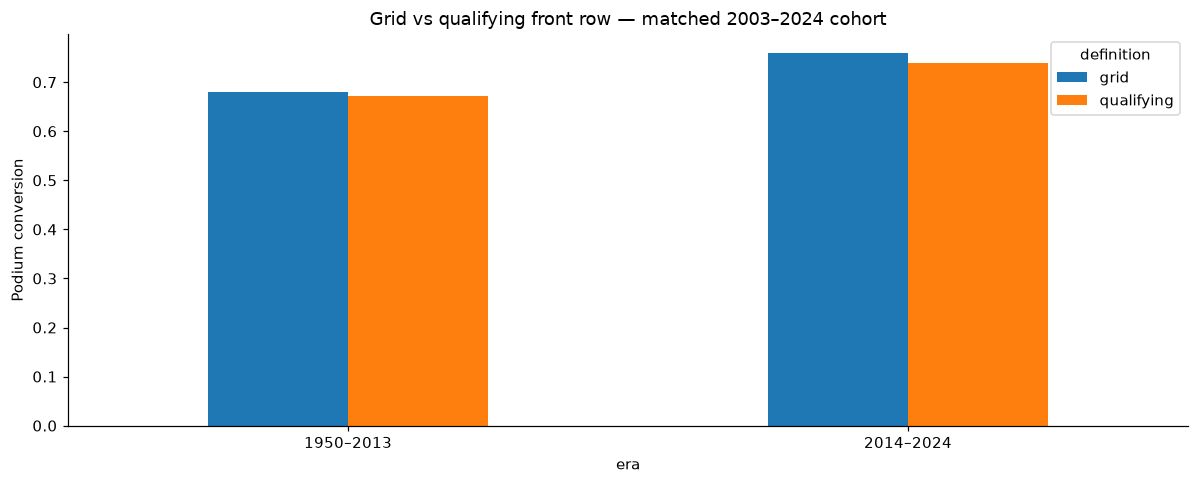

**Answer:** 1950–2013: Circuit de Nevers Magny-Cours 80.6% (29/36); Sepang International Circuit 70.0% (21/30); Suzuka Circuit 70.0% (35/50); 2014–2024: Yas Marina Circuit 86.4% (19/22); Circuit de Monaco 85.0% (17/20); Circuit de Barcelona-Catalunya 81.8% (18/22). Among 7 circuits eligible in both eras, at least one rank changes: **True**. See the common-circuit table for rank and rate changes. These are observed rankings with small and dependent samples, not evidence of a causal 2014 effect.

In [12]:
def front_row_summary(frame, position_col, label):
    selected = frame.loc[frame[position_col].isin([1,2])]
    out = selected.groupby(['circuitId','circuit_name','era2014'], observed=True).agg(
        entries=('resultId','size'), podiums=('podium','sum')).reset_index()
    out['rate'] = out['podiums']/out['entries']
    out['lower95'],out['upper95'] = wilson(out['podiums'],out['entries'])
    out['definition'] = label
    out['eligible_20'] = out['entries'].ge(20)
    out['rank_within_eligible'] = out.loc[out['eligible_20']].groupby('era2014')['rate'].rank(method='min',ascending=False)
    return out
q1_base = analysis.loc[~analysis['is_indy500']].copy()
q1_grid = front_row_summary(q1_base, 'grid', 'recorded grid 1–2')
q1_qualifying = front_row_summary(q1_base, 'qualifying_position', 'qualifying position 1–2')
analysis_table(q1_grid,'q1_grid_all_circuits'); analysis_table(q1_qualifying,'q1_qualifying_all_circuits')
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax, era in zip(axes,['1950–2013','2014–2024']):
    part=q1_grid.loc[q1_grid['era2014'].eq(era)&q1_grid['eligible_20']].nlargest(10,'rate').sort_values('rate')
    ax.barh(part['circuit_name'],part['rate'])
    ax.errorbar(part['rate'],np.arange(len(part)),xerr=[part['rate']-part['lower95'],part['upper95']-part['rate']],fmt='none',color='black',capsize=2)
    ax.set_title(f'{era}: grid front row (n ≥ 20)'); ax.set_xlim(0,1.05);ax.set_xlabel('Podium conversion')
analysis_plot('q1_front_row_circuit_rankings')
eligible=q1_grid.loc[q1_grid['eligible_20']]
common=eligible.groupby('circuitId')['era2014'].nunique(); common=common[common.eq(2)].index
common_rows=eligible.loc[eligible['circuitId'].isin(common)].copy()
common_rows['common_rank']=common_rows.groupby('era2014')['rate'].rank(method='min',ascending=False)
q1_change=common_rows.pivot(index=['circuitId','circuit_name'],columns='era2014',values=['rate','common_rank','entries'])
q1_change.columns=['_'.join(col) for col in q1_change.columns]
q1_change=q1_change.reset_index()
q1_change['rate_change']=q1_change['rate_2014–2024']-q1_change['rate_1950–2013']
q1_change['rank_improvement']=q1_change['common_rank_1950–2013']-q1_change['common_rank_2014–2024']
display(analysis_table(q1_change.sort_values('rate_change',ascending=False),'q1_common_circuit_changes'))
matched=q1_base.loc[q1_base['year'].ge(2003)&q1_base['qualifying_position'].notna()&q1_base['grid'].gt(0)]
q1_matched=pd.concat([front_row_summary(matched,'grid','grid'),front_row_summary(matched,'qualifying_position','qualifying')],ignore_index=True)
analysis_table(q1_matched,'q1_matched_2003_onward')
matched_aggregate=[]
for era,d in matched.groupby('era2014'):
    for pos,label in [('grid','grid'),('qualifying_position','qualifying')]:
        front=d.loc[d[pos].isin([1,2])]
        matched_aggregate.append({'era':era,'definition':label,'entries':len(front),'podium_rate':front['podium'].mean()})
matched_aggregate=pd.DataFrame(matched_aggregate)
display(analysis_table(matched_aggregate,'q1_matched_aggregate'))
matched_aggregate.pivot(index='era',columns='definition',values='podium_rate').plot.bar(rot=0)
plt.ylabel('Podium conversion');plt.title('Grid vs qualifying front row — matched 2003–2024 cohort')
analysis_plot('q1_grid_vs_qualifying')
leaders=[]
for era,d in eligible.groupby('era2014'):
    best=d.nlargest(3,'rate')
    leaders.append(era+': '+ '; '.join(f"{r.circuit_name} {r.rate:.1%} ({r.podiums}/{r.entries})" for r in best.itertuples()))
q1_answer='; '.join(leaders)
rank_changed=bool(q1_change['rank_improvement'].ne(0).any())
display(Markdown('**Answer:** '+q1_answer+'. '+
    f'Among {len(common)} circuits eligible in both eras, at least one rank changes: **{rank_changed}**. '
    'See the common-circuit table for rank and rate changes. These are observed rankings with small and dependent samples, not evidence of a causal 2014 effect.'))


**Answer.** With at least 20 recorded front-row entries per circuit and era, the highest 1950–2013 conversion is Magny-Cours (29/36, 80.6%). In 2014–2024, Yas Marina leads (19/22, 86.4%), followed by Monaco (17/20, 85.0%). Among seven circuits eligible in both eras, Monaco moves from sixth to first and Hungaroring from first to seventh. The separate matched 2003–2024 comparison shows grid and qualifying front-row rates differ, so they cannot be treated as interchangeable. These are descriptive rates with small modern-era denominators.

## 13. Question 2 — home-country association after adjusting for the grid
Nationality is not directly a country name. The explicit mapping below uses sporting nationality; dual nationalities count either country, East German maps geographically to Germany, and Rhodesian to Zimbabwe. Country aliases are normalized. These are declared conventions, not inferred residences.

**Primary population:** non-Indy entries with a positive recorded grid and a mapped nationality. Adjust within **exact grid position × era** strata (1950–1979, 1980–2002, 2003–2013, 2014–2021, 2022–2024). Retain strata with at least five home and five away entries; use their combined entry proportions as common weights. Report excluded counts and both raw and standardized rates on the same retained cohort.

A race-cluster bootstrap resamples races, holding the original standardization weights fixed, for an approximate interval on the home-minus-away difference. It captures same-race dependence, not every temporal/driver correlation. A secondary calculation restricts to drivers observed both at home and away. Neither adjustment controls all driver ability, constructor strength, or era effects; the result is an association.


,stage,entries
0,non-Indy entries,26287
1,mapped nationality and positive grid,24652
2,common-support strata,21616


,group,unadjusted_same_cohort,grid_era_standardized
0,Away,0.136435,0.135204
1,Home,0.114332,0.125421


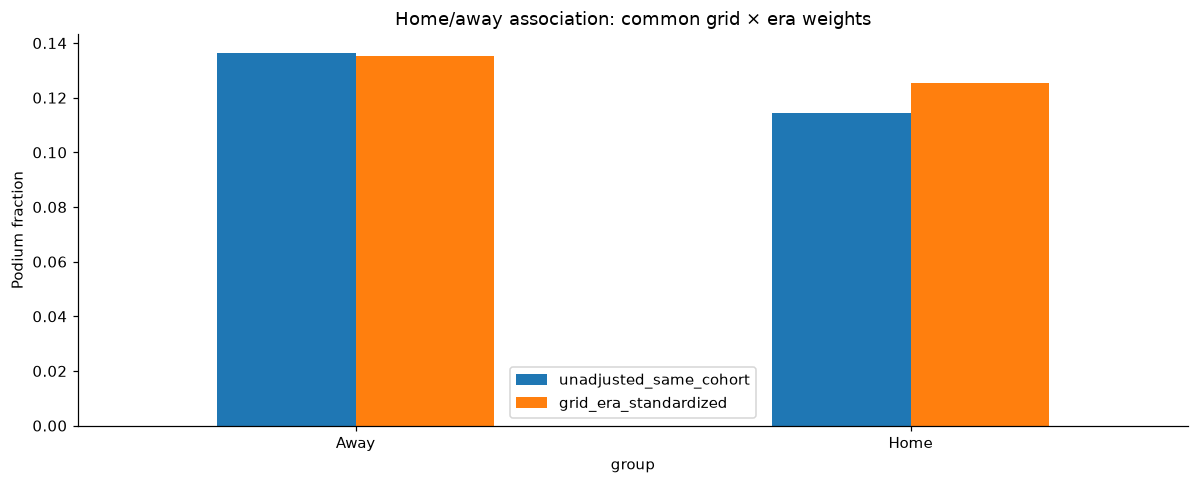

,population,entries,difference
0,all eligible drivers,21616,-0.009784
1,drivers observed at home and away,18033,-0.009815


**Answer:** After grid/era standardization, home podium rate is 12.54% versus 13.52% away: difference -0.98 percentage points (approximate 95% race-bootstrap interval -2.23 to +0.32; 476 valid replicates). This is an adjusted association, not proof of a home advantage. The common-support restriction and remaining driver/team confounding limit generalization.

In [13]:
NATIONALITY_COUNTRIES = {
'American':('USA',),'American-Italian':('USA','Italy'),'Argentine':('Argentina',),
'Argentine-Italian':('Argentina','Italy'),'Argentinian':('Argentina',),'Australian':('Australia',),
'Austrian':('Austria',),'Belgian':('Belgium',),'Brazilian':('Brazil',),'British':('UK',),
'Canadian':('Canada',),'Chilean':('Chile',),'Chinese':('China',),'Colombian':('Colombia',),
'Czech':('Czechia',),'Danish':('Denmark',),'Dutch':('Netherlands',),'East German':('Germany',),
'Finnish':('Finland',),'French':('France',),'German':('Germany',),'Hungarian':('Hungary',),
'Indian':('India',),'Indonesian':('Indonesia',),'Irish':('Ireland',),'Italian':('Italy',),
'Japanese':('Japan',),'Liechtensteiner':('Liechtenstein',),'Malaysian':('Malaysia',),
'Mexican':('Mexico',),'Monegasque':('Monaco',),'New Zealander':('New Zealand',),
'Polish':('Poland',),'Portuguese':('Portugal',),'Rhodesian':('Zimbabwe',),'Russian':('Russia',),
'South African':('South Africa',),'Spanish':('Spain',),'Swedish':('Sweden',),'Swiss':('Switzerland',),
'Thai':('Thailand',),'Uruguayan':('Uruguay',),'Venezuelan':('Venezuela',)}
analysis['nationality_clean']=analysis['nationality'].str.strip()
analysis['country_clean']=analysis['circuit_country'].replace({'United States':'USA'})
analysis['nationality_mapped']=analysis['nationality_clean'].isin(NATIONALITY_COUNTRIES)
analysis['home_race']=[country in NATIONALITY_COUNTRIES.get(nat,()) if mapped else pd.NA
    for nat,country,mapped in zip(analysis['nationality_clean'],analysis['country_clean'],analysis['nationality_mapped'])]
analysis['home_race']=analysis['home_race'].astype('boolean')
analysis_table(pd.DataFrame([{'nationality':n,'home_countries':'|'.join(v)} for n,v in NATIONALITY_COUNTRIES.items()]),'nationality_country_mapping')
assert analysis['nationality_mapped'].all(), 'Review unmapped nationalities instead of assigning away.'
q2=analysis.loc[~analysis['is_indy500']&analysis['grid'].gt(0)&analysis['nationality_mapped']].copy()
q2['home_race']=q2['home_race'].astype(bool)
q2['era']=pd.cut(q2['year'],[1949,1979,2002,2013,2021,2024],labels=['1950–1979','1980–2002','2003–2013','2014–2021','2022–2024'])
q2['stratum']=q2['era'].astype(str)+' / grid '+q2['grid'].astype(str)
def standardize_home(frame, min_group=5):
    counts=frame.groupby(['stratum','home_race'],observed=True)['podium'].agg(['size','sum'])
    n=counts['size'].unstack('home_race',fill_value=0).reindex(columns=[False,True],fill_value=0)
    keep=n.index[n.min(axis=1).ge(min_group)]
    subset=frame.loc[frame['stratum'].isin(keep)].copy()
    table=subset.groupby(['stratum','home_race'],observed=True)['podium'].agg(['size','sum','mean']).reset_index()
    weights=subset.groupby('stratum').size()/len(subset)
    rates=table.pivot(index='stratum',columns='home_race',values='mean').reindex(weights.index)
    adjusted=(rates.mul(weights,axis=0)).sum()
    return subset,table,weights,adjusted
q2_supported,q2_strata,q2_weights,q2_adjusted=standardize_home(q2)
assert len(q2_supported)>0
q2_strata['standard_weight']=q2_strata['stratum'].map(q2_weights)
analysis_table(q2_strata,'q2_grid_era_strata')
q2_counts=pd.DataFrame([{'stage':'non-Indy entries','entries':int((~analysis['is_indy500']).sum())},
    {'stage':'mapped nationality and positive grid','entries':len(q2)},
    {'stage':'common-support strata','entries':len(q2_supported)}])
display(analysis_table(q2_counts,'q2_population_counts'))
raw_home=q2_supported.groupby('home_race')['podium'].mean()
q2_rates=pd.DataFrame({'group':['Away','Home'],
    'unadjusted_same_cohort':[raw_home[False],raw_home[True]],
    'grid_era_standardized':[q2_adjusted[False],q2_adjusted[True]]})
display(analysis_table(q2_rates,'q2_home_away_rates'))
q2_rates.set_index('group').plot.bar(rot=0);plt.ylabel('Podium fraction')
plt.title('Home/away association: common grid × era weights');analysis_plot('q2_home_away_adjustment')
# Pre-aggregate race contributions so a bootstrap need not repeatedly copy all rows.
strata_order=list(q2_weights.index); groups=[(s,h) for s in strata_order for h in [False,True]]
race_ids=np.sort(q2_supported['raceId'].unique()); race_lookup={int(v):i for i,v in enumerate(race_ids)}
group_lookup={g:i for i,g in enumerate(groups)}
count_matrix=np.zeros((len(race_ids),len(groups)));success_matrix=np.zeros_like(count_matrix)
for row in q2_supported.groupby(['raceId','stratum','home_race'],observed=True)['podium'].agg(['size','sum']).reset_index().itertuples():
    i=race_lookup[int(row.raceId)];j=group_lookup[(row.stratum,bool(row.home_race))]
    count_matrix[i,j]=row.size;success_matrix[i,j]=row.sum
rng=np.random.default_rng(903);boot=[]
for _ in range(500):
    multiplicity=rng.multinomial(len(race_ids),np.full(len(race_ids),1/len(race_ids)))
    n=multiplicity@count_matrix;k=multiplicity@success_matrix
    if (n==0).any(): continue
    rates=(k/n).reshape(-1,2)
    boot.append(float(np.sum(q2_weights.to_numpy()*(rates[:,1]-rates[:,0]))))
assert len(boot)>=400, 'Bootstrap common support is too sparse.'
ci=np.quantile(boot,[.025,.975]);gap=float(q2_adjusted[True]-q2_adjusted[False])
analysis_table(pd.DataFrame({'home_minus_away':boot}),'q2_race_bootstrap')
both_ids=q2.groupby('driverId')['home_race'].nunique();both_ids=both_ids[both_ids.eq(2)].index
q2_both,_,_,adjusted_both=standardize_home(q2.loc[q2['driverId'].isin(both_ids)])
q2_sensitivity=pd.DataFrame([{'population':'all eligible drivers','entries':len(q2_supported),'difference':gap},
    {'population':'drivers observed at home and away','entries':len(q2_both),'difference':float(adjusted_both[True]-adjusted_both[False])}])
display(analysis_table(q2_sensitivity,'q2_driver_population_sensitivity'))
q2_answer=(f'After grid/era standardization, home podium rate is {q2_adjusted[True]:.2%} versus '
 f'{q2_adjusted[False]:.2%} away: difference {100*gap:+.2f} percentage points '
 f'(approximate 95% race-bootstrap interval {100*ci[0]:+.2f} to {100*ci[1]:+.2f}; {len(boot)} valid replicates).')
display(Markdown('**Answer:** '+q2_answer+' This is an adjusted association, not proof of a home advantage. The common-support restriction and remaining driver/team confounding limit generalization.'))


**Answer.** On common exact-grid × era support, the standardized podium rate is 12.54% at home versus 13.52% away, a −0.98 percentage-point difference. The race-bootstrap 95% interval is −2.23 to +0.32 points, so this data does not support a clear home advantage after the specified grid/era adjustment. Restricting to drivers observed both home and away yields nearly the same estimate. This remains observational and may reflect unmeasured driver/team differences.

## 14. Question 3 — mechanical retirement rates by constructor
**Grain:** constructor–era aggregation of unique driver entries for 2014–2021 and 2022–2024. Constructor IDs are kept separate across renames; no engine-manufacturer grouping is implied.

**Start evidence:** positive completed laps, recorded race lap/pit-stop data, or an accident/collision/spin outcome indicates a start for this operational analysis. Zero-lap withdrawals/non-qualifiers and illness are excluded as non-starts; other zero-lap cases remain unresolved unless supported by a source. Incident statuses could occasionally describe a formation-lap incident, so this is a documented operational denominator, not a claim that every start has been independently verified.

**Cause mapping:** named powertrain, hydraulic, electrical, cooling and control-system failures form the strict mechanical group. Wings, suspension, wheels/tyres and generic retired/technical/damage statuses are ambiguous because the table does not always distinguish component failure from contact or other causes. Crashes, spins, regulations and driver-health outcomes are excluded. No generic DNF is silently counted as mechanical.

Sourced corrections illustrate why labels need review: Hartley's Italy 2018 `Brakes` entry was a start-line collision ([F1 race report](https://www.formula1.com/en/latest/article/hamilton-snatches-victory-from-raikkonen-in-dramatic-italian-grand-prix.3bTryOzt5SeoQskWeGqkQY)); Albon's Japan 2022 `Hydraulics` followed contact ([F1 driver interview](https://www.formula1.com/en/video/alex-albon-reveals-contact-on-race-start-forced-his-lap-1-dnf-in-japan.1746189374282722401)). Both are excluded from mechanical causes. Grosjean's Australia 2015 power-loss retirement is confirmed as a race start ([F1 review](https://www.formula1.com/en/latest/article/winners-and-losers-the-australian-grand-prix.25r22GSjGljdejJl4AYL9U)). Corrections affect this analysis only and do not modify raw files.

Report strict rates on evidenced starts plus **sensitivity bounds** that allow ambiguous causes/starts to vary. These bounds are classification scenarios, not confidence intervals; Wilson intervals are separately labeled. Exact ranks that overlap these ranges are not definitive. Entries awaiting start/cause review are exported.

The initial zero-lap review was resolved against official F1 reports/results: 21 cases were non-starts, while Sainz (Brazil 2015) and Leclerc (Hungary 2018) did start. Together with the three initial corrections, all 26 annotations and source URLs appear in `q3_sourced_corrections.csv`. Broader cause ambiguity remains quantified; raw files and the model cohort are unchanged.


,statusId,status,category,reason
0,1,Finished,finished,Reached classification with finished/lapped st...
1,2,Disqualified,nonmechanical,"Incident, regulation, health, explicit non-sta..."
2,3,Accident,nonmechanical,"Incident, regulation, health, explicit non-sta..."
3,4,Collision,nonmechanical,"Incident, regulation, health, explicit non-sta..."
4,5,Engine,mechanical,Named component/system failure; cause inferred...
...,...,...,...,...
134,137,Damage,ambiguous,Generic retirement or component damage without...
135,138,Debris,ambiguous,Generic retirement or component damage without...
136,139,Illness,nonmechanical,"Incident, regulation, health, explicit non-sta..."
137,140,Undertray,ambiguous,Generic retirement or component damage without...


,raceId,driverId,surname,raw_status,cause_category,start_state,source,reason,verified_on
0,1002,843,Hartley,Brakes,nonmechanical,evidenced start,https://www.formula1.com/en/latest/article/ham...,Collision at the start; raw Brakes is misleading.,2026-10-10
1,1092,848,Albon,Hydraulics,nonmechanical,evidenced start,https://www.formula1.com/en/video/alex-albon-r...,Contact at race start preceded retirement.,2026-10-10
2,926,154,Grosjean,Power loss,mechanical,evidenced start,https://www.formula1.com/en/latest/article/win...,Opening-lap retirement from power loss.,2026-10-10
3,913,155,Kobayashi,Power Unit,mechanical,non-start,https://www.formula1.com/en/latest/article/rac...,"Official F1 result/report identifies DNS, rath...",2026-10-10
4,927,829,Stevens,Fuel system,mechanical,non-start,https://www.formula1.com/en/latest/article/fue...,"Official F1 result/report identifies DNS, rath...",2026-10-10
5,929,18,Button,ERS,mechanical,non-start,https://www.formula1.com/en/latest/article/but...,"Official F1 result/report identifies DNS, rath...",2026-10-10
6,934,831,Nasr,Gearbox,mechanical,non-start,https://www.formula1.com/en/results/2015/races...,"Official F1 result/report identifies DNS, rath...",2026-10-10
7,937,807,Hülkenberg,Power loss,ambiguous,non-start,https://www.formula1.com/en/results/2015/races...,"Official F1 result/report identifies DNS, rath...",2026-10-10
8,948,826,Kvyat,Retired,ambiguous,non-start,https://www.formula1.com/en/latest/article/sun...,"Official F1 result/report identifies DNS, rath...",2026-10-10
9,949,20,Vettel,Engine,mechanical,non-start,https://www.formula1.com/en/latest/article/vet...,"Official F1 result/report identifies DNS, rath...",2026-10-10


,constructorId,constructor_name,era,entries,starts,mechanical,ambiguous_started,unresolved_starts,unresolved_possible_failure,rate,lower95,upper95,scenario_low,scenario_high,rank
21,208,Lotus F1,2014–2021,76,75,13,5,0,0,0.173333,0.104191,0.274308,0.173333,0.240000,1.0
20,207,Caterham,2014–2021,34,33,5,5,0,0,0.151515,0.066505,0.309199,0.151515,0.303030,2.0
5,5,Toro Rosso,2014–2021,242,242,34,9,0,0,0.140496,0.102313,0.189914,0.140496,0.177686,3.0
4,4,Renault,2014–2021,200,198,22,8,0,0,0.111111,0.074530,0.162495,0.111111,0.151515,4.0
0,1,McLaren,2014–2021,320,315,34,13,0,0,0.107937,0.078274,0.147046,0.107937,0.149206,5.0
11,15,Sauber,2014–2021,200,199,19,6,0,0,0.095477,0.061977,0.144299,0.095477,0.125628,6.0
8,9,Red Bull,2014–2021,320,318,30,7,0,0,0.094340,0.066882,0.131481,0.094340,0.116352,7.0
23,210,Haas F1 Team,2014–2021,244,241,17,12,0,0,0.070539,0.044505,0.110050,0.070539,0.120332,8.0
28,214,Alpine F1 Team,2014–2021,44,44,3,1,0,0,0.068182,0.023459,0.182250,0.068182,0.090909,9.0
25,211,Racing Point,2014–2021,76,75,5,2,0,0,0.066667,0.028810,0.146751,0.066667,0.093333,10.0


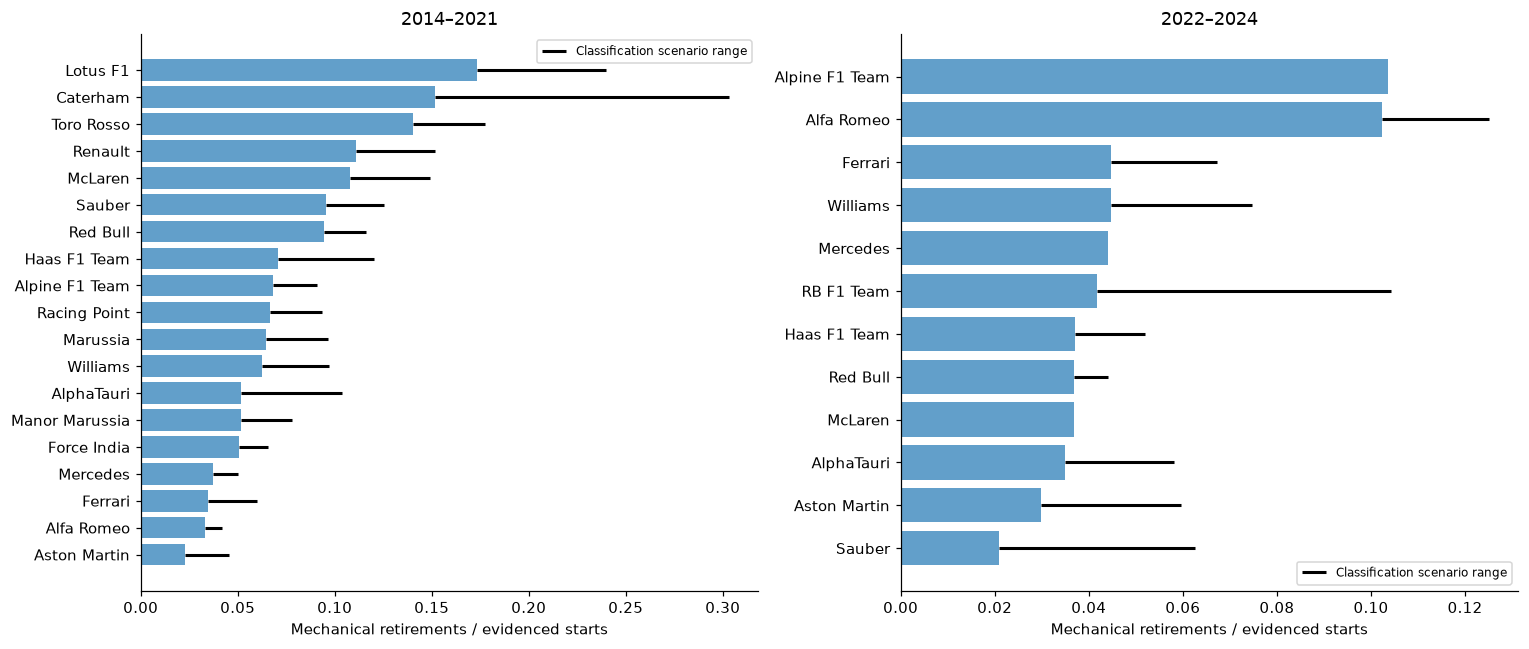

**Answer under the documented strict mapping:** 2014–2021: Lotus F1, 17.3% (13/75); classification range 17.3%–24.0%; robust top rank across these scenarios: False; 2022–2024: Alpine F1 Team, 10.4% (14/135); classification range 10.4%–10.4%; robust top rank across these scenarios: False. 0 entry start statuses remain unresolved. Treat overlapping rankings as provisional, not precise estimates of intrinsic constructor reliability. The status mapping is conservative and not an exhaustive external verification of every retirement.

In [14]:
MECHANICAL = {'Mechanical','Engine','Gearbox','Transmission','Clutch','Hydraulics','Electrical','Radiator','Brakes',
'Differential','Overheating','Driveshaft','Fuel pressure','Water pressure','Throttle','Steering','Electronics',
'Heat shield fire','Exhaust','Oil leak','Water leak','Fuel pump','Track rod','Oil pressure','Engine fire',
'Engine misfire','Wheel rim','Pneumatics','Wheel bearing','Fuel system','Oil line','Launch control',
'Drivetrain','Ignition','Halfshaft','Crankshaft','Battery','Alternator','Oil pump','Fuel leak','Injection',
'Distributor','Turbo','CV joint','Water pump','Spark plugs','Fuel pipe','Oil pipe','Axle','Water pipe',
'Magneto','Supercharger','Power Unit','ERS','Brake duct','Cooling system'}
NONMECHANICAL = {'Accident','Collision','Collision damage','Spun off','Disqualified','Excluded',
'Underweight','Physical','Injured','Injury','Driver unwell','Illness','Fatal accident','Eye injury',
'Did not qualify','Did not prequalify','107% Rule','Withdrew','Out of fuel','Refuelling','Fuel rig',
'Safety','Safety concerns','Not restarted'}
def status_category(s):
    if s=='Finished' or re.fullmatch(r'\+\d+ Laps?',s): return 'finished'
    if s in MECHANICAL: return 'mechanical'
    if s in NONMECHANICAL: return 'nonmechanical'
    return 'ambiguous'
status_map=clean['status'].copy();status_map['category']=status_map['status'].map(status_category)
status_map['reason']=status_map['category'].map({'finished':'Reached classification with finished/lapped status',
 'mechanical':'Named component/system failure; cause inferred from status unless contradicted by evidence',
 'nonmechanical':'Incident, regulation, health, explicit non-start or operational cause',
 'ambiguous':'Generic retirement or component damage without sufficiently clear cause'})
display(analysis_table(status_map,'q3_status_mapping'))
q3=analysis.loc[analysis['year'].between(2014,2024)].copy()
q3['era']=np.where(q3['year'].le(2021),'2014–2021','2022–2024')
q3['cause_category']=q3['status'].map(status_category)
event_evidence=pd.concat([clean['lap_times'][keys],clean['pit_stops'][keys]]).drop_duplicates()
evidence_index=pd.MultiIndex.from_frame(event_evidence)
has_record=pd.MultiIndex.from_frame(q3[keys]).isin(evidence_index)
incident=q3['status'].isin(['Accident','Collision','Collision damage','Spun off','Fatal accident'])
start_evidence=q3['laps'].gt(0)|has_record|incident
explicit_nonstart=q3['laps'].eq(0)&q3['status'].isin(['Withdrew','Did not qualify','Did not prequalify','107% Rule','Illness','Injured','Injury','Driver unwell'])
q3['start_state']=np.select([start_evidence.to_numpy(dtype=bool),explicit_nonstart.to_numpy(dtype=bool)],['evidenced start','non-start'],default='unresolved')
# Identify evidence-backed rows by race and driver surname; assert unique matches.
correction_specs=[
 (1002,'Hartley','nonmechanical','https://www.formula1.com/en/latest/article/hamilton-snatches-victory-from-raikkonen-in-dramatic-italian-grand-prix.3bTryOzt5SeoQskWeGqkQY','Collision at the start; raw Brakes is misleading.'),
 (1092,'Albon','nonmechanical','https://www.formula1.com/en/video/alex-albon-reveals-contact-on-race-start-forced-his-lap-1-dnf-in-japan.1746189374282722401','Contact at race start preceded retirement.'),
 (926,'Grosjean','mechanical','https://www.formula1.com/en/latest/article/winners-and-losers-the-australian-grand-prix.25r22GSjGljdejJl4AYL9U','Opening-lap retirement from power loss.')]
corrections=[]
for race,surname,category,url,note in correction_specs:
    mask=q3['raceId'].eq(race)&q3['surname'].eq(surname)
    assert mask.sum()==1
    row=q3.loc[mask].iloc[0]
    corrections.append({'raceId':race,'driverId':int(row.driverId),'surname':surname,
        'raw_status':row.status,'cause_category':category,'start_state':'evidenced start','source':url,'reason':note})
    q3.loc[mask,'cause_category']=category;q3.loc[mask,'start_state']='evidenced start'

# Resolve the zero-lap cases flagged by the initial audit using official F1 sources.
# These annotations are retrospective analysis evidence, NEVER modeling features.
DNS_SOURCES = [
 (913,'Kobayashi','https://www.formula1.com/en/latest/article/race-selected-team-and-driver-quotes.TcJiEt8tNocEWcLVHIiFO.TcJiEt8tNocEWcLVHIiFO'),
 (927,'Stevens','https://www.formula1.com/en/latest/article/fuel-system-issue-rules-stevens-out-of-malaysia.1kvtGOnc8Ar0qkMda2shpA'),
 (929,'Button','https://www.formula1.com/en/latest/article/button-a-non-starter-in-bahrain.1B9dPjmGnEDJaPKHVqpLi7'),
 (934,'Nasr','https://www.formula1.com/en/results/2015/races/925/great-britain/race-result'),
 (937,'Hülkenberg','https://www.formula1.com/en/results/2015/races/928/belgium/race-result'),
 (948,'Kvyat','https://www.formula1.com/en/latest/article/sunday-in-melbourne-team-by-team.3N3ZpWbGMRqSO8f9cI6K6i'),
 (949,'Vettel','https://www.formula1.com/en/latest/article/vettel-retires-on-bahrain-formation-lap.27juYcGClFJmBVSFyffNGK.27juYcGClFJmBVSFyffNGK'),
 (949,'Palmer','https://www.formula1.com/en/latest/article/vettel-retires-on-bahrain-formation-lap.27juYcGClFJmBVSFyffNGK.27juYcGClFJmBVSFyffNGK'),
 (971,'Vandoorne','https://www.formula1.com/en/latest/article/vandoorne-fails-to-start-in-bahrain.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k.5l5dlGw1kkG406QGcIMq0k'),
 (972,'Alonso','https://www.formula1.com/en/results/2017/drivers/FERALO01/fernando-alonso'),
 (978,'Palmer','https://www.formula1.com/en/results/2017/drivers/JOLPAL02/jolyon-palmer'),
 (983,'Räikkönen','https://www.formula1.com/en/latest/article/raikkonen-fails-to-take-the-start-in-malaysia.7AZSUN9JKgG4A8M0MWeawo'),
 (1034,'Hülkenberg','https://www.formula1.com/en/latest/article/hulkenberg-fails-to-make-british-gp-start-after-last-minute-technical-issue.3LeAfHcnAKt5KhqxFjDB82.3LeAfHcnAKt5KhqxFjDB82'),
 (1037,'Sainz','https://www.formula1.com/en/results/2020/races/1051/belgium/race-result'),
 (1056,'Leclerc','https://www.formula1.com/en/latest/article/ferrari-investigation-finds-that-leclerc-qualifying-crash-was-to-blame-for.1NNRCOZ5MBnYZVLGSg1HrC'),
 (1065,'Tsunoda','https://www.formula1.com/en/latest/article/tsunoda-laments-tough-run-of-luck-as-alphatauri-suffer-double-dnf-at-home.3pSVbpPAzh40rX98SI3SHn'),
 (1075,'Tsunoda','https://www.formula1.com/en/results/2022/drivers/YUKTSU01/yuki-tsunoda'),
 (1112,'Tsunoda','https://www.formula1.com/en/results/2023/drivers/YUKTSU01/yuki-tsunoda'),
 (1115,'Sainz','https://www.formula1.com/en/latest/article/breaking-sainz-ruled-out-of-qatar-grand-prix-due-to-pre-race-technical-issue.31LMb3qvRyvp5w6x5Orv0o'),
 (1118,'Leclerc','https://www.formula1.com/en/results/2023/races/1224/brazilian-grand-prix/race-result'),
 (1132,'Gasly','https://www.formula1.com/en/video/gasly-reveals-why-he-wasnt-able-to-start-the-race-at-silverstone.1803934435576335700')]
for race,surname,url in DNS_SOURCES:
    mask=q3['raceId'].eq(race)&q3['surname'].eq(surname)
    assert mask.sum()==1
    row=q3.loc[mask].iloc[0]
    corrections.append({'raceId':race,'driverId':int(row.driverId),'surname':surname,
      'raw_status':row.status,'cause_category':row.cause_category,'start_state':'non-start',
      'source':url,'reason':'Official F1 result/report identifies DNS, rather than an opening-lap race retirement.'})
    q3.loc[mask,'start_state']='non-start'
for race,surname,category,url,note in [
 (944,'Sainz','mechanical','https://www.formula1.com/en/latest/article/winners-and-losers-brazil.6JM8K5zPDcKeLYgQH2WDDA.6JM8K5zPDcKeLYgQH2WDDA','Started from pits; engine cut out on opening race lap.'),
 (1000,'Leclerc','nonmechanical','https://www.formula1.com/en/latest/article/leclerc-very-happy-with-sauber-progress-despite-hungary-disappointment.6gFtjPvj1eiKo46AQkesqw','Contact on opening race lap damaged the car.')]:
    mask=q3['raceId'].eq(race)&q3['surname'].eq(surname);assert mask.sum()==1
    row=q3.loc[mask].iloc[0]
    corrections.append({'raceId':race,'driverId':int(row.driverId),'surname':surname,
      'raw_status':row.status,'cause_category':category,'start_state':'evidenced start','source':url,'reason':note})
    q3.loc[mask,'start_state']='evidenced start';q3.loc[mask,'cause_category']=category

corrections_table=pd.DataFrame(corrections)
corrections_table['verified_on']='2026-10-10'
display(analysis_table(corrections_table,'q3_sourced_corrections'))
q3['is_start']=q3['start_state'].eq('evidenced start')
q3['strict_failure']=q3['is_start']&q3['cause_category'].eq('mechanical')
q3['ambiguous_started']=q3['is_start']&q3['cause_category'].eq('ambiguous')
q3['unresolved_start']=q3['start_state'].eq('unresolved')
q3['unresolved_possible_failure']=q3['unresolved_start']&q3['cause_category'].isin(['mechanical','ambiguous'])
q3_summary=q3.groupby(['constructorId','constructor_name','era']).agg(
    entries=('resultId','size'),starts=('is_start','sum'),mechanical=('strict_failure','sum'),
    ambiguous_started=('ambiguous_started','sum'),unresolved_starts=('unresolved_start','sum'),
    unresolved_possible_failure=('unresolved_possible_failure','sum')).reset_index()
q3_summary['rate']=q3_summary['mechanical']/q3_summary['starts']
q3_summary['lower95'],q3_summary['upper95']=wilson(q3_summary['mechanical'],q3_summary['starts'])
# Conservative scenario minimum: all unresolved entries started, none mechanically failed.
q3_summary['scenario_low']=q3_summary['mechanical']/(q3_summary['starts']+q3_summary['unresolved_starts'])
# Scenario maximum: ambiguous started causes and only mechanically plausible unresolved starts failed.
q3_summary['scenario_high']=(q3_summary['mechanical']+q3_summary['ambiguous_started']+q3_summary['unresolved_possible_failure'])/(q3_summary['starts']+q3_summary['unresolved_possible_failure'])
q3_summary['rank']=q3_summary.groupby('era')['rate'].rank(method='min',ascending=False)
display(analysis_table(q3_summary.sort_values(['era','rate'],ascending=[True,False]),'q3_constructor_rates'))
review_cols=['raceId','driverId','year','name','surname','constructor_name','grid','laps','status','cause_category','start_state']
analysis_table(q3.loc[q3['unresolved_start']|q3['cause_category'].eq('ambiguous'),review_cols],'q3_cases_for_review')
analysis_table(q3[review_cols+['strict_failure']],'q3_entry_classification')
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax,era in zip(axes,['2014–2021','2022–2024']):
    part=q3_summary.loc[q3_summary['era'].eq(era)].sort_values('rate')
    y=np.arange(len(part));ax.barh(part['constructor_name'],part['rate'],alpha=.7)
    ax.hlines(y,part['scenario_low'],part['scenario_high'],color='black',linewidth=2,label='Classification scenario range')
    ax.set_title(era);ax.set_xlabel('Mechanical retirements / evidenced starts');ax.legend(fontsize=8)
analysis_plot('q3_mechanical_retirement_rates')
q3_leaders=[]
for era,d in q3_summary.groupby('era'):
    leader=d.nlargest(1,'rate').iloc[0]
    others=d.loc[d['constructorId'].ne(leader.constructorId)]
    robust=bool(leader.scenario_low>others.scenario_high.max())
    q3_leaders.append(f'{era}: {leader.constructor_name}, {leader.rate:.1%} ({int(leader.mechanical)}/{int(leader.starts)}); '
                     f'classification range {leader.scenario_low:.1%}–{leader.scenario_high:.1%}; robust top rank across these scenarios: {robust}')
q3_answer='; '.join(q3_leaders)
display(Markdown('**Answer under the documented strict mapping:** '+q3_answer+'. '
    f'{int(q3.unresolved_start.sum())} entry start statuses remain unresolved. '
    'Treat overlapping rankings as provisional, not precise estimates of intrinsic constructor reliability. The status mapping is conservative and not an exhaustive external verification of every retirement.'))


**Answer.** Under the strict mechanical-cause definition, Lotus F1 has the highest 2014–2021 rate (13/75 starts, 17.3%); Alpine F1 Team has the highest 2022–2024 rate (14/135, 10.4%). Neither top rank is robust to all ambiguous-cause classification scenarios. These are constructor-ID rates, with separate identities across team renames and an operational actual-start denominator.

# 15. Pre-race feature construction
The candidate model table uses all 1950–2024 retained entries, including entries with missing qualifying data. No row is removed because of a future crash, retirement or disqualification. Race roster, constructor and grid in the retrospective results table are treated as pre-race entry information per the brief, although this dataset does not provide timestamped entry-list revisions.

**Identity disagreement policy:** use the constructor associated with the result entry as the canonical team; join qualifying by driver–race and retain its different constructor ID only in the audit. The ten 2015 disagreements concern Manor Marussia versus Marussia. Do not silently merge constructor identities across seasons. This is an explicit retrospective identity assumption.

**History:** last five driver appearances (podium fraction and mean finishing order); last five constructor race events (mean driver podium fraction). Historical form crosses season boundaries but includes only events within the preceding **365 days**; average only those available past events, with counts exposing cold starts. The exported gap audit motivates this rule: constructor IDs can reappear decades later (Aston Martin and Mercedes), and returning drivers can also have long absences. The long-gap audit supports limiting stale history. Five events and 365 days are practical freshness choices; alternative window lengths were not tuned, so these values are not claimed to be optimal. Aggregate both constructor cars in a race before rolling/lagging. Sorting is by actual race date and round, never by race ID.

**Standings:** join the snapshot after the immediately preceding completed race in the same season, including drivers absent from that race if the standings table contains them. First-race points and wins are zero; rank stays unknown. A missing snapshot later in the season remains missing. No current-race standing is used. Prior-race standings deliberately omit any current-weekend sprint points; this is stale but valid information before the main race.

**Qualifying:** position plus Q1 time relative to the fastest recorded Q1 in the same session. Relative pace removes much of circuit lap-length variation. Pre-2006 stored qualifying sessions are not identical to knockout Q1; formats, weather and missing sessions remain limitations. Q2/Q3 time features are deferred because their missingness is structural. Grid-minus-qualifying is named a position difference, not a penalty.

The exported feature list is an explicit allowlist. Current results/status/points/laps, future histories, source dates, join identifiers and the target never enter `X`. The model comparison and group ablations below assess these candidate features. The retained set is not claimed to be an optimal subset.


Historical qualifying absence is retained and imputed inside training-fitted pipelines. No historical rows are discarded for missing qualifying. Year remains a pre-race context variable; no new era-specific features are added in this range experiment, so the 24 original predictors stay fixed. Historical shared-drive labels follow the audited retention policy; raw multiple-car result rows are not duplicated back into the modeling table.

In [15]:
FEATURE_GROUPS = {
 'grid':['grid_position','grid_zero'],
 'qualifying':['qualifying_position','grid_qualifying_difference','q1_relative_pct','qualifying_missing','q1_missing'],
 'driver_form':['driver_podium_rate_5','driver_mean_finish_5','driver_history_count_5'],
 'constructor_form':['constructor_podium_rate_5','constructor_history_count_5'],
 'standings':['driver_points_before','driver_rank_before','driver_wins_before',
              'constructor_points_before','constructor_rank_before','constructor_wins_before'],
 'context':['circuit_category','constructor_category','driver_age','home_race','year','round']}
FEATURE_COLUMNS=[c for cols in FEATURE_GROUPS.values() for c in cols]
CATEGORICAL=['circuit_category','constructor_category']
NUMERIC=[c for c in FEATURE_COLUMNS if c not in CATEGORICAL]

def bounded_history(frame, entity, value_columns):
    """Last five strictly earlier appearances, no older than 365 days."""
    grouped=frame.groupby(entity,sort=False)
    lags={col:[] for col in value_columns}; valid_lags=[]
    for step in range(1,6):
        source_date=grouped['date'].shift(step)
        age=(frame['date']-source_date).dt.days
        valid=age.between(1,365).fillna(False)
        valid_lags.append(valid)
        for col in value_columns:
            lags[col].append(grouped[col].shift(step).where(valid))
    values={col:pd.concat(series,axis=1).mean(axis=1) for col,series in lags.items()}
    count=pd.concat(valid_lags,axis=1).sum(axis=1)
    last_date=grouped['date'].shift(1).where(valid_lags[0])
    return values,count,last_date

def build_prerace_features(entry_rows, races, drivers, circuits, qualifying, driver_standings, constructor_standings):
    # Keep only deliberate source columns; never carry the audit table into X.
    b=entry_rows[['raceId','driverId','constructorId','grid','positionOrder']].copy()
    b['podium']=b['positionOrder'].le(3).astype('int8')
    calendar=races[['raceId','year','round','date','circuitId']].sort_values(['date','round','raceId']).copy()
    calendar['previous_raceId']=calendar.groupby('year')['raceId'].shift(1).astype('Int64')
    calendar['previous_race_date']=calendar.groupby('year')['date'].shift(1)
    b=b.merge(calendar,on='raceId',validate='many_to_one').sort_values(['date','round','raceId','driverId']).reset_index(drop=True)
    # Lagged, time-bounded driver history preserves genuine cold starts.
    driver_values,driver_count,driver_source=bounded_history(b,'driverId',['podium','positionOrder'])
    b['driver_podium_rate_5']=driver_values['podium']
    b['driver_mean_finish_5']=driver_values['positionOrder']
    b['driver_history_count_5']=driver_count
    b['driver_form_source_date']=driver_source
    # One row per constructor/event BEFORE shifting: no teammate result leakage.
    cr=b.groupby(['constructorId','raceId','date','round'],as_index=False).agg(race_podium_fraction=('podium','mean'))
    cr=cr.sort_values(['date','round','raceId','constructorId'])
    constructor_values,constructor_count,constructor_source=bounded_history(cr,'constructorId',['race_podium_fraction'])
    cr['constructor_podium_rate_5']=constructor_values['race_podium_fraction']
    cr['constructor_history_count_5']=constructor_count
    cr['constructor_form_source_date']=constructor_source
    b=b.merge(cr[['constructorId','raceId','constructor_podium_rate_5','constructor_history_count_5','constructor_form_source_date']],
              on=['constructorId','raceId'],validate='many_to_one')
    # Snapshot joins use previous race explicitly, not a shift over current entrant rows.
    for source,entity,prefix in [(driver_standings,'driverId','driver'),(constructor_standings,'constructorId','constructor')]:
        snap=source[['raceId',entity,'points','position','wins']].rename(columns={'raceId':'previous_raceId',
             'points':prefix+'_points_before','position':prefix+'_rank_before','wins':prefix+'_wins_before'})
        b=b.merge(snap,on=['previous_raceId',entity],how='left',validate='many_to_one')
        opener=b['previous_raceId'].isna()
        b.loc[opener,[prefix+'_points_before',prefix+'_wins_before']]=0
    q=qualifying[['raceId','driverId','position','q1_seconds']].rename(columns={'position':'qualifying_position'}).copy()
    fastest=q.groupby('raceId')['q1_seconds'].transform('min')
    q['q1_relative_pct']=100*(q['q1_seconds']/fastest-1)
    b=b.merge(q[['raceId','driverId','qualifying_position','q1_relative_pct']],on=['raceId','driverId'],how='left',validate='one_to_one')
    b['grid_position']=b['grid'].where(b['grid'].gt(0))
    b['grid_zero']=b['grid'].eq(0).astype('int8')
    b['grid_qualifying_difference']=b['grid_position']-b['qualifying_position']
    b['qualifying_missing']=b['qualifying_position'].isna().astype('int8')
    b['q1_missing']=b['q1_relative_pct'].isna().astype('int8')
    b=b.merge(drivers[['driverId','dob','nationality']],on='driverId',validate='many_to_one')
    b=b.merge(circuits[['circuitId','country']],on='circuitId',validate='many_to_one')
    b['driver_age']=(b['date']-b['dob']).dt.days/365.2425
    b['home_race']=[int(country in NATIONALITY_COUNTRIES[nat.strip()])
                   for nat,country in zip(b['nationality'],b['country'].replace({'United States':'USA'}))]
    b['circuit_category']='circuit_'+b['circuitId'].astype(str)
    b['constructor_category']='constructor_'+b['constructorId'].astype(str)
    b=b.loc[b['year'].between(1950,2024)].sort_values(['date','raceId','driverId']).reset_index(drop=True)
    b['split']=np.select([b['year'].le(2019).to_numpy(dtype=bool),b['year'].le(2021).to_numpy(dtype=bool)],['train','validation'],default='test')
    return b

# Quantify gaps before choosing time-bounded history: no outcome values needed.
raw_event_history=entries.merge(clean['races'][['raceId','date','round','year']],on='raceId',validate='many_to_one')
gap_rows=[]
for entity in ['driverId','constructorId']:
    events=raw_event_history.drop_duplicates([entity,'raceId']).sort_values(['date','round','raceId'])
    events['prior_date']=events.groupby(entity)['date'].shift(1)
    events['gap_days']=(events['date']-events['prior_date']).dt.days
    events=events.loc[events['year'].ge(1950)]
    gap_rows.append({'entity':entity,'events_with_gap_over_365_days':int(events['gap_days'].gt(365).sum()),
                     'maximum_gap_days':float(events['gap_days'].max())})
gap_audit=pd.DataFrame(gap_rows);gap_audit.to_csv(FEATURES/'history_gap_audit.csv',index=False);display(gap_audit)

feature_args=(clean['races'],clean['drivers'],clean['circuits'],clean['qualifying'],clean['driver_standings'],clean['constructor_standings'])
feature_table=build_prerace_features(entries,*feature_args)
X=feature_table[FEATURE_COLUMNS].copy(); y=feature_table['podium'].copy()
assert not feature_table.duplicated(keys).any()
assert len(feature_table)==int(coverage['year'].between(1950,2024).sum())
assert feature_table.groupby('raceId')['split'].nunique().max()==1
assert np.isfinite(X[NUMERIC].to_numpy(dtype=float,na_value=np.nan)[~X[NUMERIC].isna().to_numpy()]).all()
feature_table[keys+['date','split','podium']+FEATURE_COLUMNS].to_csv(FEATURES/'modeling_table.csv',index=False)
X.to_csv(FEATURES/'X.csv',index=False);y.to_csv(FEATURES/'y.csv',index=False)
feature_table[keys+['date','previous_raceId','previous_race_date','driver_form_source_date','constructor_form_source_date']].to_csv(FEATURES/'feature_provenance.csv',index=False)
(FEATURES/'feature_groups.json').write_text(json.dumps(FEATURE_GROUPS,indent=2))
print(f'{len(feature_table):,} rows; {len(FEATURE_COLUMNS)} candidate features; no learned imputation or scaling fitted.')
display(feature_table.groupby('split').agg(rows=('driverId','size'),races=('raceId','nunique'),start=('date','min'),end=('date','max')))


,entity,events_with_gap_over_365_days,maximum_gap_days
0,driverId,416,3745.0
1,constructorId,99,22170.0


26,668 rows; 24 candidate features; no learned imputation or scaling fitted.


,rows,races,start,end
split,,,,
test,1359,68,2022-03-20,2024-12-08
train,24529,1018,1950-05-13,2019-12-01
validation,780,39,2020-07-05,2021-12-12


## 16. Feature evidence from training years only
The following numeric associations and binned plots are descriptive evidence for candidate groups, not model performance or causal explanations. Identity/context features describe known pre-race conditions; unseen categories must be handled by training-fitted encoding later. No test outcome is used to choose feature transformations or thresholds.

Missing-history values remain missing with explicit history counts; missing qualifying has indicators. Standings missingness includes season-opening unknown ranks and absent snapshots. Learn imputation/scaling/encoding on the training set only during modeling.


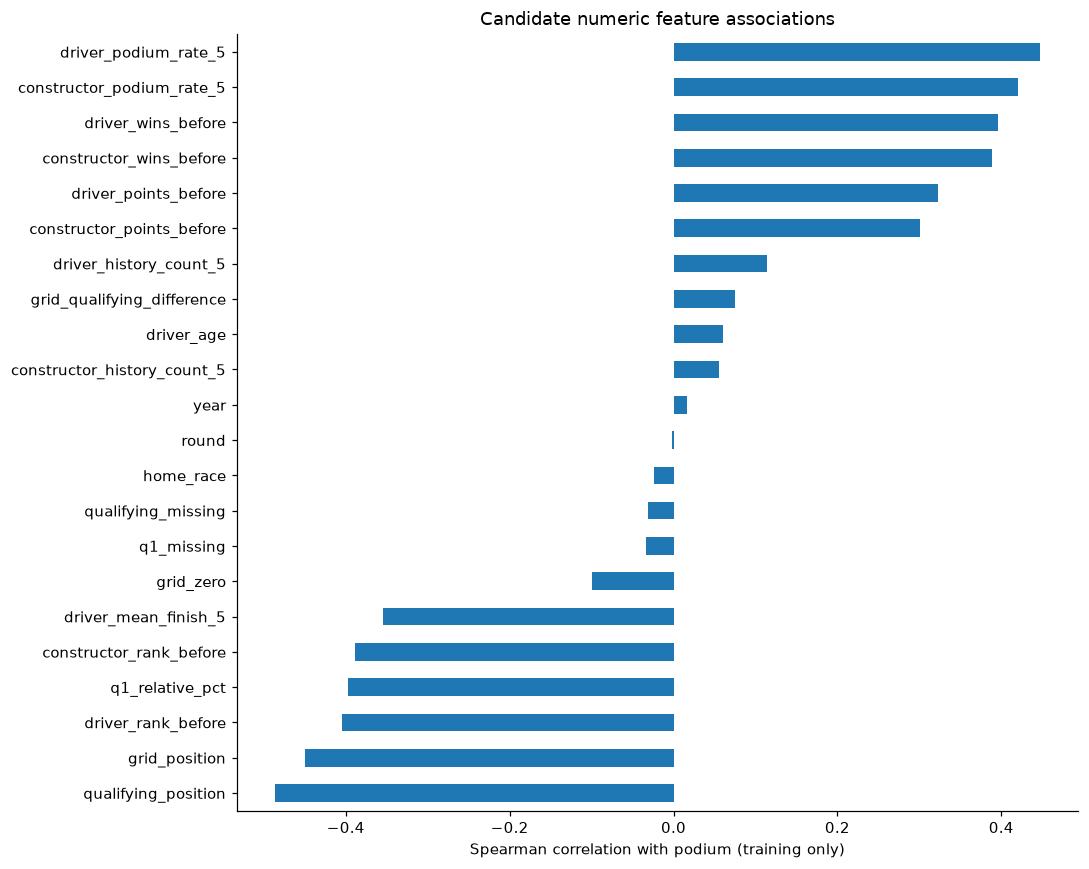

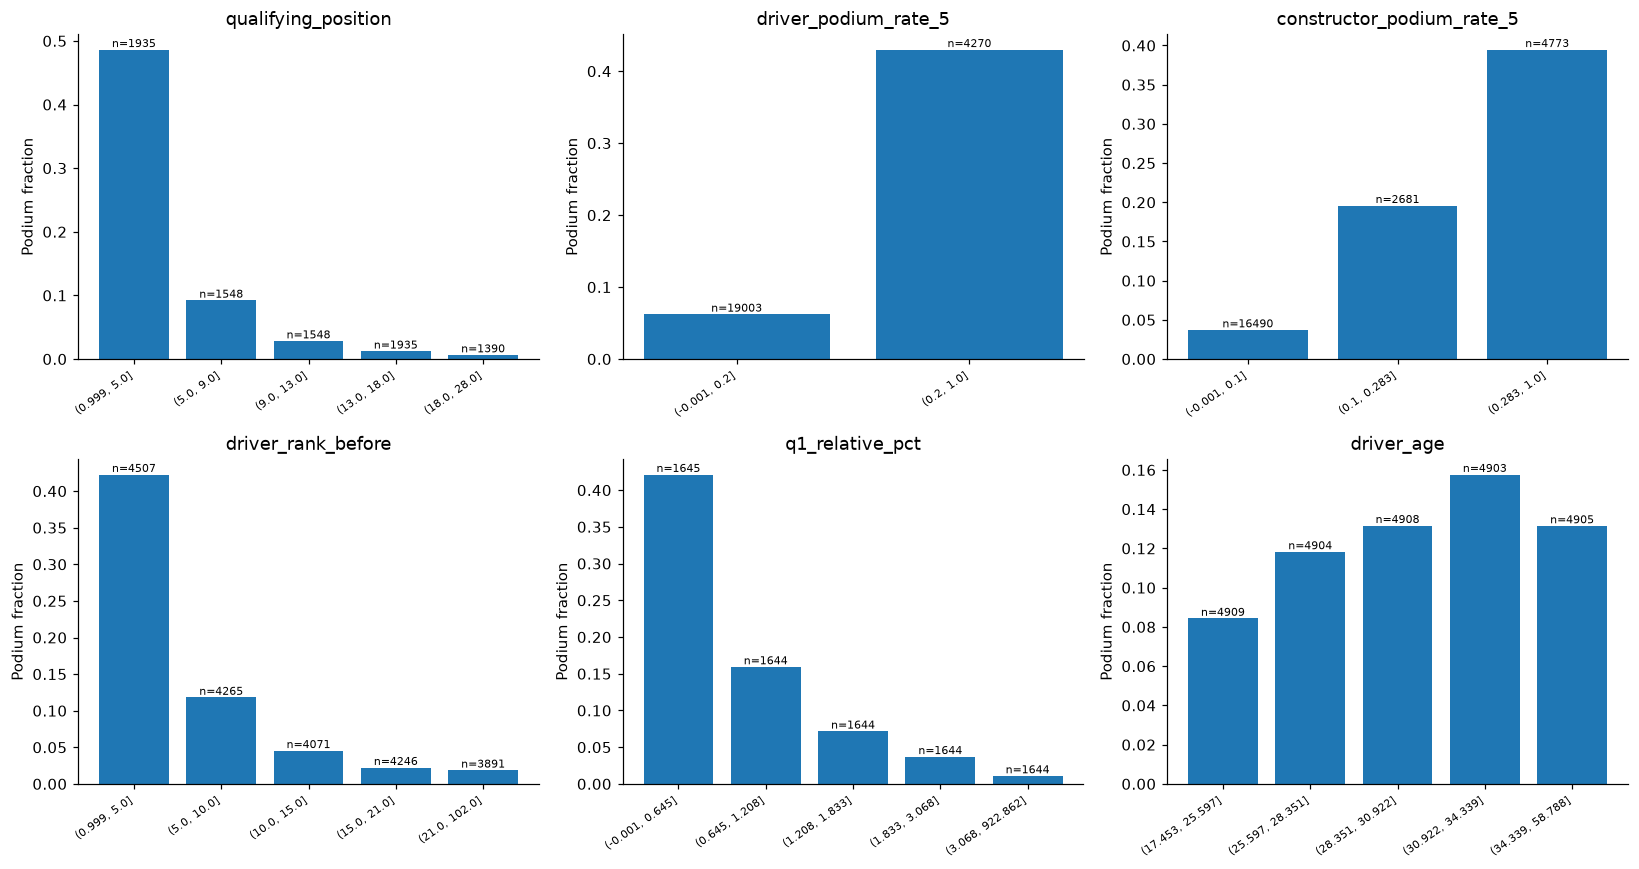

,feature,group,type,availability,justification,training_missing_fraction
0,grid_position,grid,numeric,Starting order is available at the specified c...,Audit training_grid_evidence.csv; starting pos...,0.064332
1,grid_zero,grid,numeric,Starting order is available at the specified c...,Audit training_grid_evidence.csv; starting pos...,0.000000
2,qualifying_position,qualifying,numeric,Recorded qualifying sessions precede the main ...,Training association/bin plots; missingness/fo...,0.659342
3,grid_qualifying_difference,qualifying,numeric,Recorded qualifying sessions precede the main ...,Training association/bin plots; missingness/fo...,0.660565
4,q1_relative_pct,qualifying,numeric,Recorded qualifying sessions precede the main ...,Training association/bin plots; missingness/fo...,0.664846
5,qualifying_missing,qualifying,numeric,Recorded qualifying sessions precede the main ...,Training association/bin plots; missingness/fo...,0.000000
6,q1_missing,qualifying,numeric,Recorded qualifying sessions precede the main ...,Training association/bin plots; missingness/fo...,0.000000
7,driver_podium_rate_5,driver_form,numeric,Rolling window excludes the current driver res...,Training form-bin plot; five-appearance / 365-...,0.051205
8,driver_mean_finish_5,driver_form,numeric,Rolling window excludes the current driver res...,Training form-bin plot; five-appearance / 365-...,0.051205
9,driver_history_count_5,driver_form,numeric,Rolling window excludes the current driver res...,Training form-bin plot; five-appearance / 365-...,0.000000


In [16]:
train_features=feature_table.loc[feature_table['split'].eq('train')]
feature_missing=X.isna().mean().rename('missing_fraction').rename_axis('feature').reset_index()
feature_missing.to_csv(FEATURES/'missingness.csv',index=False)
correlation_values={}
for col in NUMERIC:
    pair=train_features[[col,'podium']].dropna().astype(float)
    correlation_values[col]=pair.rank().corr().loc[col,'podium']
correlation=pd.Series(correlation_values).sort_values()
correlation.rename('training_spearman_with_podium').to_csv(FEATURES/'training_correlations.csv')
correlation.plot.barh(figsize=(10,8));plt.xlabel('Spearman correlation with podium (training only)')
plt.title('Candidate numeric feature associations');plt.tight_layout()
plt.savefig(FEATURES/'figures'/'training_correlations.png',bbox_inches='tight');plt.show();plt.close()
plot_features=['qualifying_position','driver_podium_rate_5','constructor_podium_rate_5','driver_rank_before','q1_relative_pct','driver_age']
fig,axes=plt.subplots(2,3,figsize=(15,8));binned_rows=[]
for ax,col in zip(axes.flat,plot_features):
    d=train_features[[col,'podium']].dropna().copy()
    d['bin']=pd.qcut(d[col].astype(float),q=5,duplicates='drop')
    s=d.groupby('bin',observed=True)['podium'].agg(['size','mean'])
    ax.bar(np.arange(len(s)),s['mean']);ax.set_xticks(np.arange(len(s)),[str(v) for v in s.index],rotation=35,ha='right',fontsize=7)
    ax.set_title(col);ax.set_ylabel('Podium fraction')
    for i,row in enumerate(s.itertuples()): ax.text(i,row.mean,f'n={row.size}',ha='center',va='bottom',fontsize=7)
    out=s.reset_index();out['feature']=col;binned_rows.append(out)
plt.tight_layout();plt.savefig(FEATURES/'figures'/'training_feature_bins.png',bbox_inches='tight');plt.show();plt.close()
pd.concat(binned_rows,ignore_index=True).to_csv(FEATURES/'training_feature_bins.csv',index=False)
reasons={
 'grid':('Starting order is available at the specified cutoff.','Audit training_grid_evidence.csv; starting positions reflect track position.'),
 'qualifying':('Recorded qualifying sessions precede the main race.','Training association/bin plots; missingness/format drift documented in audit.'),
 'driver_form':('Rolling window excludes the current driver result.','Training form-bin plot; five-appearance / 365-day window is a provisional design choice for later ablation.'),
 'constructor_form':('Constructor race aggregation is lagged before joining driver entries.','Training constructor-form plot; captures recent team strength without using a teammate current result.'),
 'standings':('Snapshot from previous race in the same season; opener points/wins zero.','Training rank association; cumulative points and wins are candidate alternatives, potentially redundant.'),
 'context':('Circuit/team identity, age, nationality, season/round are pre-race metadata.','Age plot and contextual hypothesis; categorical support counts exported; retain only if later ablation supports value.')}
registry=pd.DataFrame([{'feature':col,'group':group,'type':'categorical' if col in CATEGORICAL else 'numeric',
    'availability':reasons[group][0],'justification':reasons[group][1],
    'training_missing_fraction':float(train_features[col].isna().mean())}
    for group,cols in FEATURE_GROUPS.items() for col in cols])
registry.to_csv(FEATURES/'feature_registry.csv',index=False);display(registry)
for col in CATEGORICAL:
    train_features[col].value_counts().rename('training_entries').to_csv(FEATURES/f'{col}_training_support.csv')


## 17. Leakage and reproducibility checks
Assertions cover unique grain, whole-race splits, strictly earlier source dates, season-opening standings, matching prior snapshots, and shared team history within a race.

The behavioral test rebuilds features after corrupting **current and future** race outcomes and standings at two cutoffs (a season opener and a mid-season race). Features at or before each cutoff must be identical, while altered labels and later histories confirm that the test actually exercised the pipeline. This catches accidental unshifted form, same-race teammate leakage, and current-race standings use. It does not prove the source dataset's timestamps or retrospective identities are perfect.


In [17]:
checks=[]
def checked(name, condition):
    assert bool(condition), name
    checks.append({'check':name,'passed':True})
for source in ['driver_form_source_date','constructor_form_source_date','previous_race_date']:
    valid=feature_table[source].notna()
    checked(source+' strictly earlier',feature_table.loc[valid,source].lt(feature_table.loc[valid,'date']).all())
for source in ['driver_form_source_date','constructor_form_source_date']:
    valid=feature_table[source].notna()
    checked(source+' within one year',(feature_table.loc[valid,'date']-feature_table.loc[valid,source]).dt.days.le(365).all())
# Famous long-gap constructor returns must start with unknown recent form.
for race,constructor in [(1052,117),(337,131)]:
    returned=feature_table.loc[feature_table['raceId'].eq(race)&feature_table['constructorId'].eq(constructor)]
    checked(f'constructor cold start {race}/{constructor}',len(returned)>0 and returned['constructor_history_count_5'].eq(0).all() and returned['constructor_podium_rate_5'].isna().all())
openers=feature_table['previous_raceId'].isna()
checked('season-opening points and wins zero',feature_table.loc[openers,['driver_points_before','driver_wins_before','constructor_points_before','constructor_wins_before']].eq(0).all().all())
checked('season-opening ranks unknown',feature_table.loc[openers,['driver_rank_before','constructor_rank_before']].isna().all().all())
checked('constructor form shared across teammates',feature_table.groupby(['raceId','constructorId'])['constructor_podium_rate_5'].nunique(dropna=False).le(1).all())
checked('forbidden current outcomes absent from feature allowlist',not set(FEATURE_COLUMNS)&{'podium','positionOrder','points','statusId','status','laps','positionText','milliseconds','fastestLap','rank'})
# Independently compare selected driver form values with a direct prior-event filter.
history=entries.merge(clean['races'][['raceId','date','round']],on='raceId',validate='many_to_one')
for row in feature_table.iloc[[0,3000,-1]].itertuples():
    prior=history.loc[history['driverId'].eq(row.driverId)&history['date'].lt(row.date)&history['date'].ge(row.date-pd.Timedelta(days=365))].sort_values(['date','round','raceId']).tail(5)
    expected=float(prior['positionOrder'].le(3).mean()) if len(prior) else np.nan
    checked(f'direct driver-history check {row.raceId}/{row.driverId}',np.isclose(row.driver_podium_rate_5,expected,equal_nan=True))
for cutoff in [pd.Timestamp('2022-03-20'),pd.Timestamp('2015-07-26')]:
    future_ids=clean['races'].loc[clean['races']['date'].ge(cutoff),'raceId']
    mutated_entries=entries.copy()
    mask=mutated_entries['raceId'].isin(future_ids)
    mutated_entries.loc[mask,'positionOrder']=np.where(mutated_entries.loc[mask,'positionOrder'].le(3),20,1)
    mutated_driver=clean['driver_standings'].copy();mutated_constructor=clean['constructor_standings'].copy()
    for frame in [mutated_driver,mutated_constructor]:
        frame.loc[frame['raceId'].isin(future_ids),['points','position','wins']]=999
    changed=build_prerace_features(mutated_entries,clean['races'],clean['drivers'],clean['circuits'],clean['qualifying'],mutated_driver,mutated_constructor)
    before=feature_table['date'].le(cutoff)
    pd.testing.assert_frame_equal(feature_table.loc[before,FEATURE_COLUMNS],changed.loc[before,FEATURE_COLUMNS])
    checked(f'current/future mutation cannot change earlier features {cutoff.date()}',True)
    checked(f'mutation changed labels {cutoff.date()}',feature_table.loc[~before,'podium'].ne(changed.loc[~before,'podium']).any())
    checked(f'mutation affects later form {cutoff.date()}',not feature_table.loc[~before,'driver_podium_rate_5'].equals(changed.loc[~before,'driver_podium_rate_5']))
checked('raw files still unchanged',{t:sha256(DATA_DIR/f'{t}.csv') for t in TABLES}==hashes_before)
checked('feature row count matches eligible entries',len(feature_table)==len(coverage.loc[coverage['year'].between(1950,2024)]))
checked('training ends before validation',feature_table.loc[feature_table['split'].eq('train'),'date'].max()<feature_table.loc[feature_table['split'].eq('validation'),'date'].min())
checked('validation ends before test',feature_table.loc[feature_table['split'].eq('validation'),'date'].max()<feature_table.loc[feature_table['split'].eq('test'),'date'].min())
checked('all supplied entry years retained', set(feature_table['year']) == set(coverage['year']))
checked('full-history grain includes every retained entry', len(feature_table) == len(entries))
checks=pd.DataFrame(checks);checks.to_csv(FEATURES/'validation_checks.csv',index=False);display(checks)
summary2={'q1_answer':q1_answer,'q1_common_circuit_rank_changed':rank_changed,
    'q2_answer':q2_answer,'q2_adjusted_home_minus_away':gap,'q2_bootstrap_interval':ci.tolist(),
    'q3_answer':q3_answer,'q3_unresolved_start_entries':int(q3.unresolved_start.sum()),
    'feature_rows':len(feature_table),'feature_count':len(FEATURE_COLUMNS),'checks_passed':len(checks),
    'feature_groups':FEATURE_GROUPS,'stage':'analysis and candidate features complete; modeling sections follow'}
(ANALYSIS/'analysis_feature_summary.json').write_text(json.dumps(summary2,indent=2))
display(Markdown(f'**Analysis and candidate features complete:** {len(feature_table):,} rows, '
    f'{len(FEATURE_COLUMNS)} allowlisted features, {len(checks)} validation checks passed. '
    'Subsequent sections contain fitted models, ablations, explanations and inference; the PDF report is in reports/ms1_report.pdf (full-history revision). '
    'Retirement cause/start ambiguity is quantified and exported, not silently resolved.'))


,check,passed
0,driver_form_source_date strictly earlier,True
1,constructor_form_source_date strictly earlier,True
2,previous_race_date strictly earlier,True
3,driver_form_source_date within one year,True
4,constructor_form_source_date within one year,True
5,constructor cold start 1052/117,True
6,constructor cold start 337/131,True
7,season-opening points and wins zero,True
8,season-opening ranks unknown,True
9,constructor form shared across teammates,True


**Analysis and candidate features complete:** 26,668 rows, 24 allowlisted features, 26 validation checks passed. Subsequent sections contain fitted models, ablations, explanations and inference; the PDF report is in reports/ms1_report.pdf (full-history revision). Retirement cause/start ambiguity is quantified and exported, not silently resolved.

## 18. Validation-only model comparison
The same 24,529 training rows, 780 validation rows, and 24 pre-race features feed all three models. The 2022–2024 test rows are excluded before preprocessing or fitting. A logistic regression is the interpretable statistical baseline; a bounded random forest tests nonlinear interactions; a one-hidden-layer (32-unit) neural network tests whether a shallow learned representation helps. Median imputation, scaling, and one-hot encoding are fitted on training data only. The neural network's early-stopping subset is also drawn only from training.

Podiums are about 15% of validation entries, so average precision (PR-AUC) is our chosen primary ranking measure. We also report ROC-AUC, F1, precision, and recall. Each F1 threshold is chosen on validation predictions; validation F1 is therefore optimistic and must not be treated as independent test performance. A whole-race bootstrap shows whether a small AP difference is stable across race weekends.

**Protocol fixed before this revision's fits:** compare 1950–2019 and 2003–2019 training; validation is the identical 780 entries in 2020–2021, and test the identical 1,359 entries in 2022–2024. Use the same 24 raw features, median→standardize/one-hot pipeline, seed 903, three baselines and two extra variants per family. Fit every learned transform within its own training scope. First compare identical baseline configurations to isolate training scope; separately compare family-wise validation winners with equal tuning budgets. Fit no current/future outcomes into features. Thresholds maximize validation F1. Full-history is mandatory; scores determine model variants within that scope, not whether to ignore the requirement. Bootstrap intervals are descriptive paired race resamples, conditional on fitted models, without correction for multiple comparisons or tuning selection.


**Metric roles.** Average precision (AP, used here as the PR-AUC summary) is the primary metric for selecting variants: it focuses on retrieving podium finishers in a validation set where they represent 15% of entries. ROC-AUC is secondary because it summarizes positive-versus-negative ranking across thresholds. F1, precision and recall describe the binary decisions at the operating threshold. Each threshold maximizes validation F1 on the fixed grid; test scores select neither thresholds nor model settings.

**Baseline and capacity.** Logistic regression is the simple statistical baseline. Random forest and the shallow network test whether nonlinear structure improves validation performance enough to justify greater complexity. Every family receives the same raw predictors and external evaluation rows. Model settings, preprocessing and seeds are fixed within each controlled comparison.


In [18]:
"""Validation-only model comparison for the F1 milestone notebook."""
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score, precision_recall_curve
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, QuantileTransformer, StandardScaler
from sklearn.exceptions import ConvergenceWarning

try:
    ROOT
except NameError:
    ROOT = Path.cwd()
FEATURES = RUN_ROOT / 'features'
MODEL_OUT = RUN_ROOT / 'modeling'
MODEL_OUT.mkdir(parents=True, exist_ok=True)
feature_groups = json.loads((FEATURES / 'feature_groups.json').read_text())
feature_names = [name for group in feature_groups.values() for name in group]
assert len(feature_names) == len(set(feature_names)) == 24
full_table = pd.read_csv(FEATURES / 'modeling_table.csv')
assert set(feature_names).issubset(full_table.columns)
assert not full_table.duplicated(['raceId', 'driverId']).any()
# The test cohort is excluded before any target, preprocessing or model operation.
development = full_table.loc[full_table['split'].isin(['train', 'validation'])].copy()
training = development.loc[development['split'].eq('train')]
validation = development.loc[development['split'].eq('validation')]
assert training['date'].max() < validation['date'].min()
X_train = training[feature_names].copy()
X_valid = validation[feature_names].copy()
y_train = training['podium'].astype(int)
y_valid = validation['podium'].astype(int)
assert len(X_train) == 24529 and len(X_valid) == 780
categorical = ['circuit_category', 'constructor_category']
numeric = [name for name in feature_names if name not in categorical]
assert X_train[numeric].select_dtypes(exclude='number').empty


def train_pipeline(estimator, columns=feature_names, numeric_steps=None):
    numeric_subset = [c for c in columns if c not in categorical]
    categorical_subset = [c for c in columns if c in categorical]
    return Pipeline([
        ('prepare', ColumnTransformer([
            ('numeric', Pipeline(numeric_steps or [('impute', SimpleImputer(strategy='median')),
                                                    ('scale', StandardScaler())]), numeric_subset),
            ('category', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_subset),
        ], remainder='drop', sparse_threshold=0)),
        ('model', estimator),
    ])


def best_f1_threshold(y_true, probability):
    grid = np.linspace(0.05, 0.95, 181)
    scores = np.array([f1_score(y_true, probability >= t, zero_division=0) for t in grid])
    return float(grid[np.flatnonzero(scores == scores.max())[0]])


def score_row(name, split, y_true, probability, threshold):
    prediction = probability >= threshold
    return {'model': name, 'split': split,
            'roc_auc': roc_auc_score(y_true, probability),
            'pr_auc': average_precision_score(y_true, probability),
            'f1': f1_score(y_true, prediction, zero_division=0),
            'precision': precision_score(y_true, prediction, zero_division=0),
            'recall': recall_score(y_true, prediction, zero_division=0),
            'threshold': threshold, 'rows': len(y_true), 'podium_rate': float(np.mean(y_true))}


from sklearn.base import clone
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
COMPARISON_OUT = ROOT / 'artifacts' / 'history_comparison'
COMPARISON_OUT.mkdir(parents=True, exist_ok=True)
protocol = {'full_training_years':'1950-2019','modern_training_years':'2003-2019',
    'validation_years':'2020-2021','test_years':'2022-2024',
    'features':feature_names,'primary_metric':'average_precision',
    'same_baseline_settings':True,'variants_per_family_per_scope':3,'seed':903,
    'threshold_rule':'max validation F1; lowest tied threshold on 0.05..0.95 step 0.005',
    'required_submission_scope':'full_history','prior_test_exposure':True,
    'test_used_to_select_revision':False,'input_hashes_sha256':hashes_before}
(COMPARISON_OUT/'protocol.json').write_text(json.dumps(protocol,indent=2))
variant_models = {}
convergence_records = []
def fit_with_diagnostics(pipeline, x, y, scope, variant):
    import time
    started=time.monotonic()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        pipeline.fit(x,y)
    model=pipeline.named_steps['model']
    n_iter=getattr(model,'n_iter_',None)
    convergence_records.append({'scope':scope,'variant':variant,'seconds':time.monotonic()-started,
        'iterations':str(n_iter),'convergence_warnings':' | '.join(str(w.message) for w in caught if issubclass(w.category,ConvergenceWarning))})
    print('Fitted',scope,variant,flush=True)
    return pipeline


In [19]:
model_specs = {
    'logistic_regression': LogisticRegression(max_iter=1500, C=1.0, random_state=903),
    'random_forest': RandomForestClassifier(n_estimators=200, max_depth=8,
                                            min_samples_leaf=8, random_state=903, n_jobs=2),
    'shallow_nn': MLPClassifier(hidden_layer_sizes=(32,), activation='relu', alpha=0.01,
                                early_stopping=True, validation_fraction=0.15,
                                n_iter_no_change=15, max_iter=300, random_state=903),
}
fitted_models = {}
model_probabilities = {}
comparison_rows = []

def show_attempt_result(result, reference_ap, comparison):
    """Display the measured result beside its prespecified reference."""
    display(pd.DataFrame([result]).round(4))
    difference = float(result['pr_auc']) - float(reference_ap)
    direction = 'higher' if difference > 0 else 'lower' if difference < 0 else 'equal'
    display(Markdown(
        f"**Result.** Validation AP is **{result['pr_auc']:.4f}**, "
        f"compared with **{reference_ap:.4f}** for {comparison} "
        f"(difference **{difference:+.4f}**; {direction}). "
        "This is an observed difference on the same validation races, "
        "not a claim of statistically established superiority."
    ))


### 18.1 Logistic regression baseline

Logistic regression models podium log-odds as an additive function of the encoded inputs. It provides a simple, regularized reference for the nonlinear models. The baseline uses C=1 and a maximum of 1,500 optimization iterations. Its main limitation is that numeric effects are additive unless interactions are supplied explicitly.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [20]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    name = 'logistic_regression'
    estimator = model_specs[name]
    pipeline = train_pipeline(estimator)
    fit_with_diagnostics(pipeline, X_train, y_train, 'full_history', name + '_baseline')
    variant_models[name + '_baseline'] = pipeline
    train_p = pipeline.predict_proba(X_train)[:, 1]
    valid_p = pipeline.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, valid_p)
    comparison_rows += [score_row(name, 'train', y_train, train_p, threshold), score_row(name, 'validation', y_valid, valid_p, threshold)]
    fitted_models[name] = pipeline
    model_probabilities[name] = valid_p
show_attempt_result(comparison_rows[-1], comparison_rows[1]['pr_auc'], 'the full-history logistic baseline')

Fitted full_history logistic_regression_baseline


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,logistic_regression,validation,0.9283,0.73,0.7054,0.6454,0.7778,0.27,780,0.15


**Result.** Validation AP is **0.7300**, compared with **0.7300** for the full-history logistic baseline (difference **+0.0000**; equal). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 18.2 Random forest baseline

A forest can capture nonlinear thresholds and interactions between starting position, recent form and standings. The baseline averages 200 trees, with depth limited to 8 and at least 8 entries per leaf. These restrictions limit detailed fitting to individual historical entries. The number of trees is a fixed computational choice, not the result of a tree-count search.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [21]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    name = 'random_forest'
    estimator = model_specs[name]
    pipeline = train_pipeline(estimator)
    fit_with_diagnostics(pipeline, X_train, y_train, 'full_history', name + '_baseline')
    variant_models[name + '_baseline'] = pipeline
    train_p = pipeline.predict_proba(X_train)[:, 1]
    valid_p = pipeline.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, valid_p)
    comparison_rows += [score_row(name, 'train', y_train, train_p, threshold), score_row(name, 'validation', y_valid, valid_p, threshold)]
    fitted_models[name] = pipeline
    model_probabilities[name] = valid_p
show_attempt_result(comparison_rows[-1], comparison_rows[1]['pr_auc'], 'the full-history logistic baseline')

Fitted full_history random_forest_baseline


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,random_forest,validation,0.9234,0.7126,0.7004,0.6917,0.7094,0.395,780,0.15


**Result.** Validation AP is **0.7126**, compared with **0.7300** for the full-history logistic baseline (difference **-0.0174**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 18.3 Shallow neural-network baseline

The network uses one hidden layer of 32 ReLU units and L2 regularization alpha=0.01. It tests whether learned nonlinear combinations improve on the statistical baseline. Early stopping uses a random 15% subset of the outer training set and monitors accuracy. This is separate from the external chronological validation set; it is not a race-grouped, AP-based stopping procedure.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [22]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    name = 'shallow_nn'
    estimator = model_specs[name]
    pipeline = train_pipeline(estimator)
    fit_with_diagnostics(pipeline, X_train, y_train, 'full_history', name + '_baseline')
    variant_models[name + '_baseline'] = pipeline
    train_p = pipeline.predict_proba(X_train)[:, 1]
    valid_p = pipeline.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, valid_p)
    comparison_rows += [score_row(name, 'train', y_train, train_p, threshold), score_row(name, 'validation', y_valid, valid_p, threshold)]
    fitted_models[name] = pipeline
    model_probabilities[name] = valid_p
show_attempt_result(comparison_rows[-1], comparison_rows[1]['pr_auc'], 'the full-history logistic baseline')

Fitted full_history shallow_nn_baseline


,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,shallow_nn,validation,0.9281,0.7149,0.6984,0.6519,0.7521,0.34,780,0.15


**Result.** Validation AP is **0.7149**, compared with **0.7300** for the full-history logistic baseline (difference **-0.0151**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 18. Comparison across attempts

The table and plot collect the attempts above, including settings that did not improve the reference.

              model      split  roc_auc  pr_auc     f1  precision  recall  threshold  rows  podium_rate
logistic_regression      train   0.9110  0.5744 0.5895     0.4969  0.7247      0.270 24529       0.1247
logistic_regression validation   0.9283  0.7300 0.7054     0.6454  0.7778      0.270   780       0.1500
      random_forest      train   0.9053  0.5858 0.5182     0.6259  0.4421      0.395 24529       0.1247
      random_forest validation   0.9234  0.7126 0.7004     0.6917  0.7094      0.395   780       0.1500
         shallow_nn      train   0.9215  0.6186 0.5984     0.5458  0.6622      0.340 24529       0.1247
         shallow_nn validation   0.9281  0.7149 0.6984     0.6519  0.7521      0.340   780       0.1500


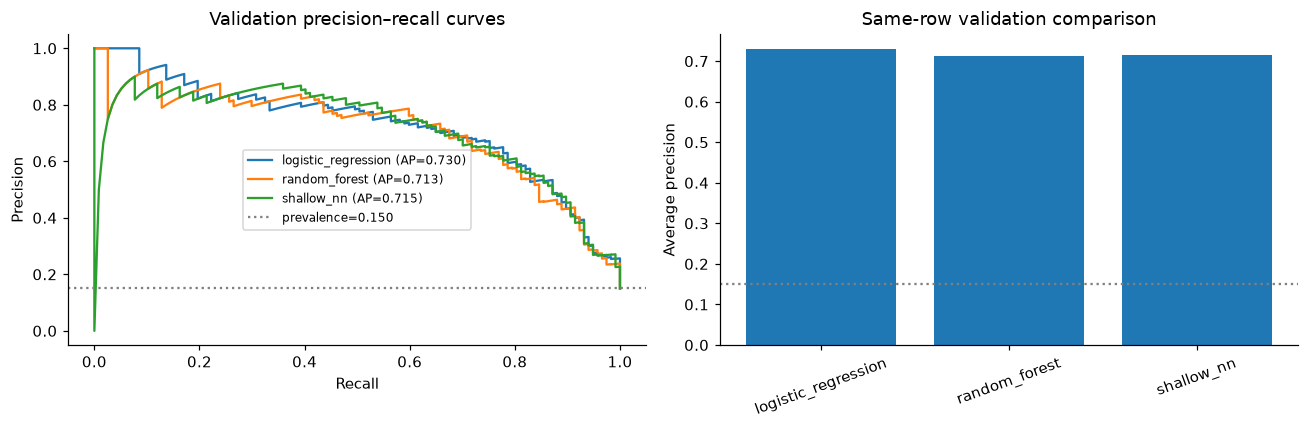

Forest minus logistic validation AP: -0.0174 race-bootstrap 95% interval: [-0.0483  0.0161]


In [23]:
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(MODEL_OUT / 'validation_model_comparison.csv', index=False)
print(comparison.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, probability in model_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_valid, probability)
    axes[0].plot(recall, precision, label=f'{name} (AP={average_precision_score(y_valid, probability):.3f})')
axes[0].axhline(y_valid.mean(), color='gray', linestyle=':', label=f'prevalence={y_valid.mean():.3f}')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Validation precision–recall curves')
axes[0].legend(fontsize=8)
validation_scores = comparison.loc[comparison['split'].eq('validation')]
axes[1].bar(validation_scores['model'], validation_scores['pr_auc'])
axes[1].axhline(y_valid.mean(), color='gray', linestyle=':')
axes[1].set(ylabel='Average precision', title='Same-row validation comparison')
axes[1].tick_params(axis='x', labelrotation=20)
fig.tight_layout()
fig.savefig(MODEL_OUT / 'validation_model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

# Resample whole races: drivers in the same event do not form independent units.
race_ids = validation['raceId'].to_numpy()
unique_races = np.unique(race_ids)
race_positions = {race: np.flatnonzero(race_ids == race) for race in unique_races}
rng = np.random.default_rng(903)
bootstrap_differences = []
for _ in range(1000):
    sampled = rng.choice(unique_races, size=len(unique_races), replace=True)
    positions = np.concatenate([race_positions[race] for race in sampled])
    label = y_valid.to_numpy()[positions]
    forest_ap = average_precision_score(label, model_probabilities['random_forest'][positions])
    logistic_ap = average_precision_score(label, model_probabilities['logistic_regression'][positions])
    bootstrap_differences.append(forest_ap - logistic_ap)
ap_difference_interval = np.quantile(bootstrap_differences, [0.025, 0.975])
print('Forest minus logistic validation AP:',
      round(float(np.mean(bootstrap_differences)), 4),
      'race-bootstrap 95% interval:', np.round(ap_difference_interval, 4))


## 19. Preprocessing-order experiments
These four controlled logistic-regression runs keep rows, features, estimator, and validation rule fixed. Pair one swaps median imputation and standardization. Pair two swaps median imputation and quantile normalization. All statistics are learned from training rows only; the validation period is transformed using those fitted parameters. The standardization pair can differ because filling missing values changes the variance used by the scaler. The quantile pair also changes the empirical distribution used to learn a nonlinear mapping. Scores, rather than intuition alone, determine whether the extra transform helps.

In [24]:
# Each pair keeps estimator, rows, features and threshold rule fixed.
quantiles = lambda: QuantileTransformer(n_quantiles=500, output_distribution='normal', random_state=903)
order_variants = {
    'scale: impute -> standardize': [('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())],
    'scale: standardize -> impute': [('scale', StandardScaler()), ('impute', SimpleImputer(strategy='median'))],
    'quantile: impute -> quantile': [('impute', SimpleImputer(strategy='median')), ('quantile', quantiles())],
    'quantile: quantile -> impute': [('quantile', quantiles()), ('impute', SimpleImputer(strategy='median'))],
}
order_rows = []

### 19.1 Median imputation followed by standardization

This is the reference numeric pipeline. Medians fill missing training values; the scaler then estimates its mean and standard deviation from the completed training columns.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [25]:
label = 'scale: impute -> standardize'
steps = order_variants[label]
pipeline = train_pipeline(LogisticRegression(max_iter=1500, random_state=903), numeric_steps=steps)
pipeline.fit(X_train, y_train)
probability = pipeline.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
row = score_row(label, 'validation', y_valid, probability, threshold)
row['experiment'] = label.split(':')[0]
order_rows.append(row)
show_attempt_result(order_rows[-1], float(validation_scores.set_index('model').loc['logistic_regression', 'pr_auc']), 'median imputation followed by standardization')

,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate,experiment
0,scale: impute -> standardize,validation,0.9283,0.73,0.7054,0.6454,0.7778,0.27,780,0.15,scale


**Result.** Validation AP is **0.7300**, compared with **0.7300** for median imputation followed by standardization (difference **+0.0000**; equal). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 19.2 Standardization followed by median imputation

The scaler estimates moments from observed values before missing values are filled. The order can change the fitted variance and effective regularization, even when median filling commutes with a fixed linear transformation.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [26]:
label = 'scale: standardize -> impute'
steps = order_variants[label]
pipeline = train_pipeline(LogisticRegression(max_iter=1500, random_state=903), numeric_steps=steps)
pipeline.fit(X_train, y_train)
probability = pipeline.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
row = score_row(label, 'validation', y_valid, probability, threshold)
row['experiment'] = label.split(':')[0]
order_rows.append(row)
show_attempt_result(order_rows[-1], float(validation_scores.set_index('model').loc['logistic_regression', 'pr_auc']), 'median imputation followed by standardization')

,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate,experiment
0,scale: standardize -> impute,validation,0.9282,0.729,0.7054,0.6454,0.7778,0.27,780,0.15,scale


**Result.** Validation AP is **0.7290**, compared with **0.7300** for median imputation followed by standardization (difference **-0.0010**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 19.3 Median imputation followed by quantile transformation

The quantile mapping is fitted after missing values are filled. Repeated median replacements therefore form part of the empirical distribution. The mapping targets a normal distribution and can change the relationships seen by a linear model.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [27]:
label = 'quantile: impute -> quantile'
steps = order_variants[label]
pipeline = train_pipeline(LogisticRegression(max_iter=1500, random_state=903), numeric_steps=steps)
pipeline.fit(X_train, y_train)
probability = pipeline.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
row = score_row(label, 'validation', y_valid, probability, threshold)
row['experiment'] = label.split(':')[0]
order_rows.append(row)
show_attempt_result(order_rows[-1], float(validation_scores.set_index('model').loc['logistic_regression', 'pr_auc']), 'median imputation followed by standardization')

,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate,experiment
0,quantile: impute -> quantile,validation,0.9086,0.6756,0.7,0.6829,0.7179,0.225,780,0.15,quantile


**Result.** Validation AP is **0.6756**, compared with **0.7300** for median imputation followed by standardization (difference **-0.0544**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 19.4 Quantile transformation followed by median imputation

The quantile mapping is fitted on observed values first; missing transformed values are then filled. Comparing this with the preceding attempt measures the effect of the order under the same estimator and rows.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [28]:
label = 'quantile: quantile -> impute'
steps = order_variants[label]
pipeline = train_pipeline(LogisticRegression(max_iter=1500, random_state=903), numeric_steps=steps)
pipeline.fit(X_train, y_train)
probability = pipeline.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
row = score_row(label, 'validation', y_valid, probability, threshold)
row['experiment'] = label.split(':')[0]
order_rows.append(row)
show_attempt_result(order_rows[-1], float(validation_scores.set_index('model').loc['logistic_regression', 'pr_auc']), 'median imputation followed by standardization')

,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate,experiment
0,quantile: quantile -> impute,validation,0.9042,0.6725,0.7,0.6829,0.7179,0.215,780,0.15,quantile


**Result.** Validation AP is **0.6725**, compared with **0.7300** for median imputation followed by standardization (difference **-0.0576**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 19. Comparison across attempts

The table and plot collect the attempts above, including settings that did not improve the reference.

                       model  pr_auc  roc_auc     f1  threshold
scale: impute -> standardize  0.7300   0.9283 0.7054      0.270
scale: standardize -> impute  0.7290   0.9282 0.7054      0.270
quantile: impute -> quantile  0.6756   0.9086 0.7000      0.225
quantile: quantile -> impute  0.6725   0.9042 0.7000      0.215


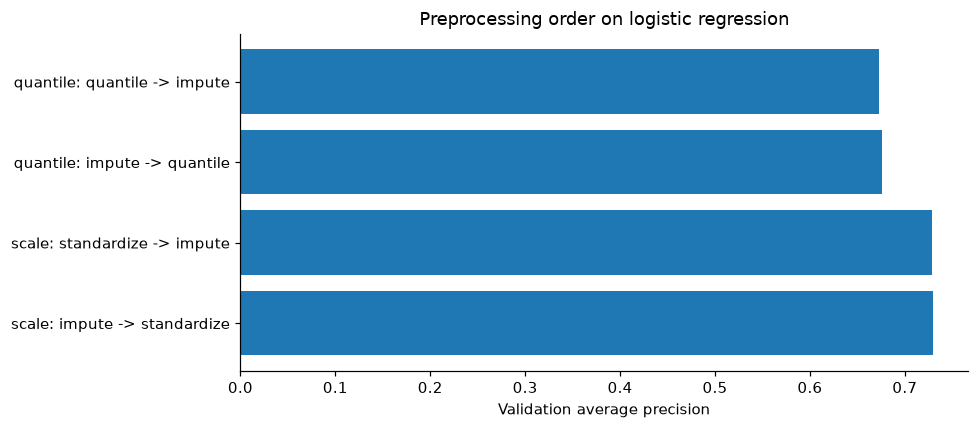

In [29]:
order_results = pd.DataFrame(order_rows)
order_results.to_csv(MODEL_OUT / 'preprocessing_order_experiments.csv', index=False)
print(order_results[['model', 'pr_auc', 'roc_auc', 'f1', 'threshold']].round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(order_results['model'], order_results['pr_auc'])
ax.set(xlabel='Validation average precision', title='Preprocessing order on logistic regression')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'preprocessing_order_experiments.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)


### Preprocessing effect on feature values
The score comparison above is complemented by a training-only distribution check for Q1 pace relative to the session best. It displays observed raw values, median-imputed and standardized values, and median-imputed quantile-normalized values. This shows the actual change of scale and shape; validation/test rows do not fit any transform.

                  stage  rows  missing  median    mean     std     p05    p95
           observed raw  8221    16308  1.5029  2.1408 10.3508  0.0214 5.6733
impute then standardize 24529        0 -0.0356 -0.0000  1.0000 -0.2062 0.3217
   impute then quantile 24529        0 -0.0000 -0.0430  1.0633 -1.6380 1.6436


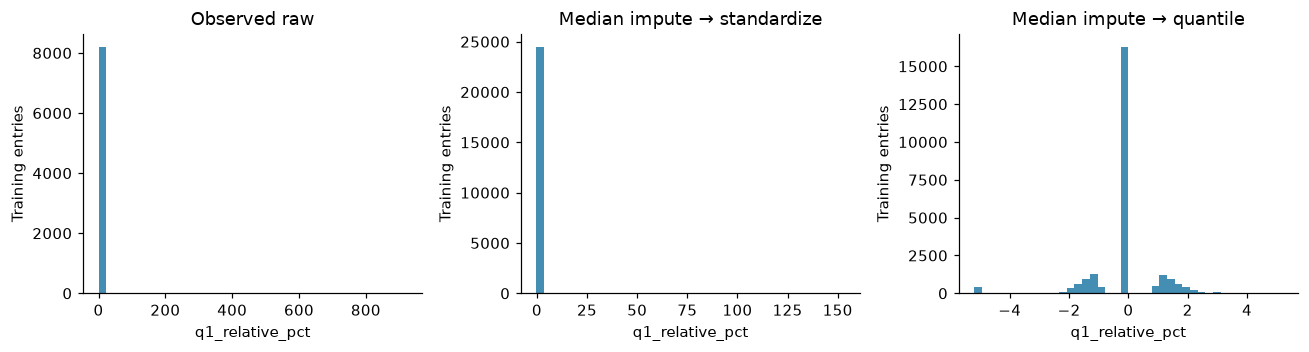

In [30]:
# Fit illustrative transforms on training rows only; do not use validation/test distributions.
example_feature = 'q1_relative_pct'
raw_example = X_train[example_feature].dropna().to_numpy()
standard_example = Pipeline([('impute', SimpleImputer(strategy='median')),
                             ('scale', StandardScaler())]).fit_transform(X_train[[example_feature]]).ravel()
quantile_example = Pipeline([('impute', SimpleImputer(strategy='median')),
                             ('quantile', QuantileTransformer(n_quantiles=500,
                                 output_distribution='normal', random_state=903))]).fit_transform(
                                     X_train[[example_feature]]).ravel()
preprocessing_distribution = pd.DataFrame([
    {'stage': label, 'rows': len(values), 'missing': missing, 'median': np.median(values),
     'mean': np.mean(values), 'std': np.std(values), 'p05': np.quantile(values, 0.05),
     'p95': np.quantile(values, 0.95)}
    for label, values, missing in [
        ('observed raw', raw_example, int(X_train[example_feature].isna().sum())),
        ('impute then standardize', standard_example, 0),
        ('impute then quantile', quantile_example, 0),
    ]
])
preprocessing_distribution.to_csv(MODEL_OUT / 'preprocessing_distribution.csv', index=False)
print(preprocessing_distribution.round(4).to_string(index=False))
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, (label, values) in zip(axes, [
    ('Observed raw', raw_example),
    ('Median impute → standardize', standard_example),
    ('Median impute → quantile', quantile_example),
]):
    ax.hist(values, bins=40, color='#2379a6', alpha=0.85)
    ax.set(title=label, xlabel=example_feature, ylabel='Training entries')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'preprocessing_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

## 20. Hyperparameter sensitivity
A small grid tests two additional settings per model family against each baseline. This is a bounded validation-only comparison, with the same rows, features, preprocessing, and random seed. We record PR-AUC, ROC-AUC and F1 for every attempt, and keep the trial results visible even when a more complex setting fails to help. The previously exposed test period is excluded from these revised selection experiments.

In [31]:
# These are sensitivity checks, not an unrestricted search over the validation years.
tuning_specs = {
    'logistic_C_0.1': ('logistic_regression', LogisticRegression(C=0.1, max_iter=1500, random_state=903)),
    'logistic_C_3': ('logistic_regression', LogisticRegression(C=3.0, max_iter=1500, random_state=903)),
    'forest_depth_5_leaf_12': ('random_forest', RandomForestClassifier(
        n_estimators=200, max_depth=5, min_samples_leaf=12, random_state=903, n_jobs=2)),
    'forest_depth_12_leaf_5': ('random_forest', RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=5, random_state=903, n_jobs=2)),
    'nn_16_alpha_0.01': ('shallow_nn', MLPClassifier(
        hidden_layer_sizes=(16,), activation='relu', alpha=0.01, early_stopping=True,
        validation_fraction=0.15, n_iter_no_change=15, max_iter=300, random_state=903)),
    'nn_64_alpha_0.1': ('shallow_nn', MLPClassifier(
        hidden_layer_sizes=(64,), activation='relu', alpha=0.1, early_stopping=True,
        validation_fraction=0.15, n_iter_no_change=15, max_iter=300, random_state=903)),
}
tuning_rows = []
for name, row in validation_scores.set_index('model').iterrows():
    tuning_rows.append({'variant': f'{name}_baseline', 'family': name,
                        'pr_auc': row['pr_auc'], 'roc_auc': row['roc_auc'],
                        'f1': row['f1'], 'threshold': row['threshold']})

### 20.1 Logistic regression: stronger regularization

C changes from 1 to 0.1. A smaller C penalizes large coefficients more strongly and may reduce unstable reliance on correlated features. All other settings remain fixed.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [32]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    variant = 'logistic_C_0.1'
    family, estimator = tuning_specs[variant]
    candidate = train_pipeline(estimator)
    fit_with_diagnostics(candidate, X_train, y_train, 'full_history', variant)
    variant_models[variant] = candidate
    probability = candidate.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, probability)
    tuning_rows.append({'variant': variant, 'family': family, 'pr_auc': average_precision_score(y_valid, probability), 'roc_auc': roc_auc_score(y_valid, probability), 'f1': f1_score(y_valid, probability >= threshold), 'threshold': threshold})
show_attempt_result(tuning_rows[-1], float(validation_scores.set_index('model').loc[family, 'pr_auc']), family + ' at its baseline settings')

Fitted full_history logistic_C_0.1


,variant,family,pr_auc,roc_auc,f1,threshold
0,logistic_C_0.1,logistic_regression,0.7279,0.9279,0.7049,0.305


**Result.** Validation AP is **0.7279**, compared with **0.7300** for logistic_regression at its baseline settings (difference **-0.0021**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 20.2 Logistic regression: weaker regularization

C changes from 1 to 3. A larger C allows the coefficients to follow the training data more closely. This tests whether the baseline penalty is too restrictive.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [33]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    variant = 'logistic_C_3'
    family, estimator = tuning_specs[variant]
    candidate = train_pipeline(estimator)
    fit_with_diagnostics(candidate, X_train, y_train, 'full_history', variant)
    variant_models[variant] = candidate
    probability = candidate.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, probability)
    tuning_rows.append({'variant': variant, 'family': family, 'pr_auc': average_precision_score(y_valid, probability), 'roc_auc': roc_auc_score(y_valid, probability), 'f1': f1_score(y_valid, probability >= threshold), 'threshold': threshold})
show_attempt_result(tuning_rows[-1], float(validation_scores.set_index('model').loc[family, 'pr_auc']), family + ' at its baseline settings')

Fitted full_history logistic_C_3


,variant,family,pr_auc,roc_auc,f1,threshold
0,logistic_C_3,logistic_regression,0.7277,0.9278,0.7097,0.3


**Result.** Validation AP is **0.7277**, compared with **0.7300** for logistic_regression at its baseline settings (difference **-0.0024**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 20.3 Random forest: shallower trees and larger leaves

Maximum depth changes from 8 to 5 and minimum leaf size from 8 to 12. This is a combined lower-capacity alternative. Any score change belongs to that combination; the experiment does not isolate the effect of either setting alone.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [34]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    variant = 'forest_depth_5_leaf_12'
    family, estimator = tuning_specs[variant]
    candidate = train_pipeline(estimator)
    fit_with_diagnostics(candidate, X_train, y_train, 'full_history', variant)
    variant_models[variant] = candidate
    probability = candidate.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, probability)
    tuning_rows.append({'variant': variant, 'family': family, 'pr_auc': average_precision_score(y_valid, probability), 'roc_auc': roc_auc_score(y_valid, probability), 'f1': f1_score(y_valid, probability >= threshold), 'threshold': threshold})
show_attempt_result(tuning_rows[-1], float(validation_scores.set_index('model').loc[family, 'pr_auc']), family + ' at its baseline settings')

Fitted full_history forest_depth_5_leaf_12


,variant,family,pr_auc,roc_auc,f1,threshold
0,forest_depth_5_leaf_12,random_forest,0.7084,0.9202,0.6917,0.355


**Result.** Validation AP is **0.7084**, compared with **0.7126** for random_forest at its baseline settings (difference **-0.0042**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 20.4 Random forest: deeper trees and smaller leaves

Maximum depth changes from 8 to 12 and minimum leaf size from 8 to 5. The higher-capacity forest can represent more detailed interactions, with a greater risk of overfitting. Both settings change together.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [35]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    variant = 'forest_depth_12_leaf_5'
    family, estimator = tuning_specs[variant]
    candidate = train_pipeline(estimator)
    fit_with_diagnostics(candidate, X_train, y_train, 'full_history', variant)
    variant_models[variant] = candidate
    probability = candidate.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, probability)
    tuning_rows.append({'variant': variant, 'family': family, 'pr_auc': average_precision_score(y_valid, probability), 'roc_auc': roc_auc_score(y_valid, probability), 'f1': f1_score(y_valid, probability >= threshold), 'threshold': threshold})
show_attempt_result(tuning_rows[-1], float(validation_scores.set_index('model').loc[family, 'pr_auc']), family + ' at its baseline settings')

Fitted full_history forest_depth_12_leaf_5


,variant,family,pr_auc,roc_auc,f1,threshold
0,forest_depth_12_leaf_5,random_forest,0.7253,0.926,0.7022,0.445


**Result.** Validation AP is **0.7253**, compared with **0.7126** for random_forest at its baseline settings (difference **+0.0127**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 20.5 Shallow network: 16 hidden units

The hidden layer shrinks from 32 to 16 units while alpha remains 0.01. This tests whether a smaller representation is sufficient for the available predictors.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [36]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    variant = 'nn_16_alpha_0.01'
    family, estimator = tuning_specs[variant]
    candidate = train_pipeline(estimator)
    fit_with_diagnostics(candidate, X_train, y_train, 'full_history', variant)
    variant_models[variant] = candidate
    probability = candidate.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, probability)
    tuning_rows.append({'variant': variant, 'family': family, 'pr_auc': average_precision_score(y_valid, probability), 'roc_auc': roc_auc_score(y_valid, probability), 'f1': f1_score(y_valid, probability >= threshold), 'threshold': threshold})
show_attempt_result(tuning_rows[-1], float(validation_scores.set_index('model').loc[family, 'pr_auc']), family + ' at its baseline settings')

Fitted full_history nn_16_alpha_0.01


,variant,family,pr_auc,roc_auc,f1,threshold
0,nn_16_alpha_0.01,shallow_nn,0.7273,0.924,0.7083,0.365


**Result.** Validation AP is **0.7273**, compared with **0.7149** for shallow_nn at its baseline settings (difference **+0.0124**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 20.6 Shallow network: 64 units with stronger regularization

The hidden layer grows from 32 to 64 units and alpha increases from 0.01 to 0.1. This tests a wider, more strongly penalized network. Width and regularization change together, so their effects cannot be separated from this result.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [37]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    variant = 'nn_64_alpha_0.1'
    family, estimator = tuning_specs[variant]
    candidate = train_pipeline(estimator)
    fit_with_diagnostics(candidate, X_train, y_train, 'full_history', variant)
    variant_models[variant] = candidate
    probability = candidate.predict_proba(X_valid)[:, 1]
    threshold = best_f1_threshold(y_valid, probability)
    tuning_rows.append({'variant': variant, 'family': family, 'pr_auc': average_precision_score(y_valid, probability), 'roc_auc': roc_auc_score(y_valid, probability), 'f1': f1_score(y_valid, probability >= threshold), 'threshold': threshold})
show_attempt_result(tuning_rows[-1], float(validation_scores.set_index('model').loc[family, 'pr_auc']), family + ' at its baseline settings')

Fitted full_history nn_64_alpha_0.1


,variant,family,pr_auc,roc_auc,f1,threshold
0,nn_64_alpha_0.1,shallow_nn,0.709,0.9285,0.7045,0.275


**Result.** Validation AP is **0.7090**, compared with **0.7149** for shallow_nn at its baseline settings (difference **-0.0058**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 20. Comparison across attempts

The table and plot collect the attempts above, including settings that did not improve the reference.

                     variant              family  pr_auc  roc_auc     f1  threshold
logistic_regression_baseline logistic_regression  0.7300   0.9283 0.7054      0.270
              logistic_C_0.1 logistic_regression  0.7279   0.9279 0.7049      0.305
                logistic_C_3 logistic_regression  0.7277   0.9278 0.7097      0.300
      forest_depth_12_leaf_5       random_forest  0.7253   0.9260 0.7022      0.445
      random_forest_baseline       random_forest  0.7126   0.9234 0.7004      0.395
      forest_depth_5_leaf_12       random_forest  0.7084   0.9202 0.6917      0.355
            nn_16_alpha_0.01          shallow_nn  0.7273   0.9240 0.7083      0.365
         shallow_nn_baseline          shallow_nn  0.7149   0.9281 0.6984      0.340
             nn_64_alpha_0.1          shallow_nn  0.7090   0.9285 0.7045      0.275


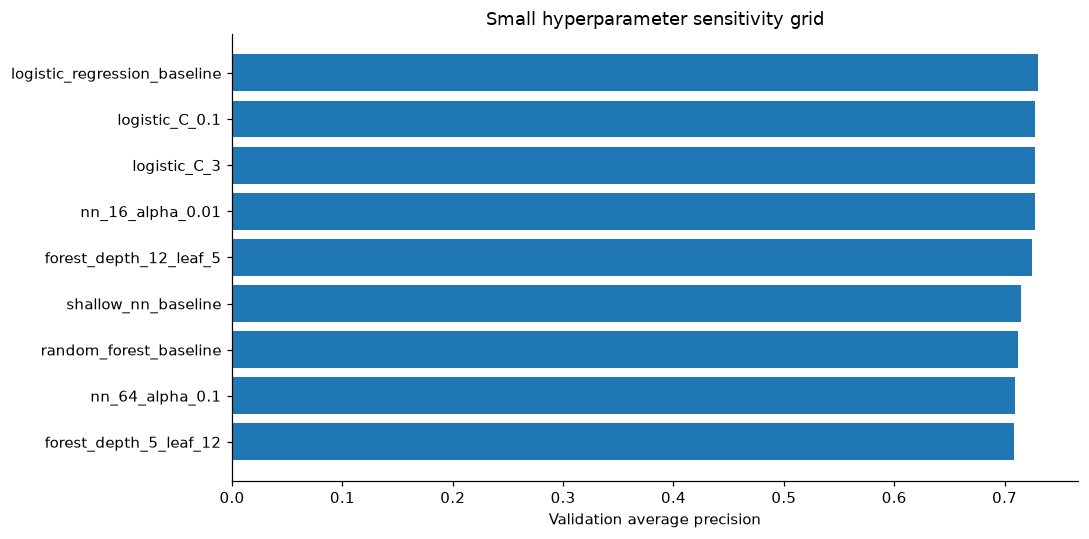

In [38]:
tuning_results = pd.DataFrame(tuning_rows).sort_values(['family', 'pr_auc'], ascending=[True, False])
tuning_results.to_csv(MODEL_OUT / 'validation_tuning_sensitivity.csv', index=False)
print(tuning_results.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 5))
view = tuning_results.sort_values('pr_auc')
ax.barh(view['variant'], view['pr_auc'])
ax.set(xlabel='Validation average precision', title='Small hyperparameter sensitivity grid')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'validation_tuning_sensitivity.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)


## 21. Feature-group ablation
Each ablation starts from the baseline validation AP leader, removes one prespecified group and refits from scratch. The change in validation average precision estimates each group's contribution to this pipeline on this period. Small positive or negative changes are not causal effects and may be sampling noise; they are evidence for a later model-selection decision, not an instruction to discard a group automatically.

The ablation reference is the highest-AP model among the three **baseline configurations**, not the later tuned winner. Small positive removal deltas are reported honestly; the same original 24-feature candidate set is retained for the controlled scope comparison.

**Interpretation.** Each ablation removes one named group and refits the full pipeline. Grid-group removal leaves qualifying rank and grid-minus-qualifying in the qualifying group; together they can reconstruct an observed grid position. The result therefore measures the contribution of the named columns, not the elimination of all starting-grid information. Correlated predictors can substitute for removed columns, and group results do not establish that every member is individually necessary.


In [39]:
leader = validation_scores.sort_values(['pr_auc', 'roc_auc'], ascending=False).iloc[0]['model']
leader_spec = model_specs[leader]
leader_ap = float(validation_scores.set_index('model').loc[leader, 'pr_auc'])
ablation_rows = [{'removed_group': 'none', 'model': leader, 'features': len(feature_names),
                  'pr_auc': leader_ap, 'delta_pr_auc': 0.0}]

### 21.1 Without grid

The removed columns are grid_position and grid_zero. The qualifying group still contains qualifying position and grid-minus-qualifying, so this does not remove every source of starting-grid information.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [40]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    group = 'grid'
    removed = feature_groups[group]
    retained = [name for name in feature_names if name not in removed]
    from sklearn.base import clone
    candidate = train_pipeline(clone(leader_spec), columns=retained)
    candidate.fit(X_train[retained], y_train)
    probability = candidate.predict_proba(X_valid[retained])[:, 1]
    ap = average_precision_score(y_valid, probability)
    ablation_rows.append({'removed_group': group, 'model': leader, 'features': len(retained), 'pr_auc': ap, 'delta_pr_auc': ap - leader_ap})
show_attempt_result(ablation_rows[-1], leader_ap, 'the same baseline model with all 24 predictors')

,removed_group,model,features,pr_auc,delta_pr_auc
0,grid,logistic_regression,22,0.7229,-0.0072


**Result.** Validation AP is **0.7229**, compared with **0.7300** for the same baseline model with all 24 predictors (difference **-0.0072**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21.2 Without qualifying

The removed columns contain qualifying rank, relative Q1 pace, the grid/qualifying difference and the two qualifying-missingness indicators. Grid itself remains available.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [41]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    group = 'qualifying'
    removed = feature_groups[group]
    retained = [name for name in feature_names if name not in removed]
    from sklearn.base import clone
    candidate = train_pipeline(clone(leader_spec), columns=retained)
    candidate.fit(X_train[retained], y_train)
    probability = candidate.predict_proba(X_valid[retained])[:, 1]
    ap = average_precision_score(y_valid, probability)
    ablation_rows.append({'removed_group': group, 'model': leader, 'features': len(retained), 'pr_auc': ap, 'delta_pr_auc': ap - leader_ap})
show_attempt_result(ablation_rows[-1], leader_ap, 'the same baseline model with all 24 predictors')

,removed_group,model,features,pr_auc,delta_pr_auc
0,qualifying,logistic_regression,19,0.7157,-0.0144


**Result.** Validation AP is **0.7157**, compared with **0.7300** for the same baseline model with all 24 predictors (difference **-0.0144**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21.3 Without driver form

The removed columns summarize the driver’s recent podium rate, mean finishing order and history count. Prior standings and team context remain available as possible substitutes.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [42]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    group = 'driver_form'
    removed = feature_groups[group]
    retained = [name for name in feature_names if name not in removed]
    from sklearn.base import clone
    candidate = train_pipeline(clone(leader_spec), columns=retained)
    candidate.fit(X_train[retained], y_train)
    probability = candidate.predict_proba(X_valid[retained])[:, 1]
    ap = average_precision_score(y_valid, probability)
    ablation_rows.append({'removed_group': group, 'model': leader, 'features': len(retained), 'pr_auc': ap, 'delta_pr_auc': ap - leader_ap})
show_attempt_result(ablation_rows[-1], leader_ap, 'the same baseline model with all 24 predictors')

,removed_group,model,features,pr_auc,delta_pr_auc
0,driver_form,logistic_regression,21,0.7284,-0.0016


**Result.** Validation AP is **0.7284**, compared with **0.7300** for the same baseline model with all 24 predictors (difference **-0.0016**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21.4 Without constructor form

The removed columns summarize recent team podium fractions and the number of prior events. Constructor identity and prior team standings remain available.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [43]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    group = 'constructor_form'
    removed = feature_groups[group]
    retained = [name for name in feature_names if name not in removed]
    from sklearn.base import clone
    candidate = train_pipeline(clone(leader_spec), columns=retained)
    candidate.fit(X_train[retained], y_train)
    probability = candidate.predict_proba(X_valid[retained])[:, 1]
    ap = average_precision_score(y_valid, probability)
    ablation_rows.append({'removed_group': group, 'model': leader, 'features': len(retained), 'pr_auc': ap, 'delta_pr_auc': ap - leader_ap})
show_attempt_result(ablation_rows[-1], leader_ap, 'the same baseline model with all 24 predictors')

,removed_group,model,features,pr_auc,delta_pr_auc
0,constructor_form,logistic_regression,22,0.7271,-0.003


**Result.** Validation AP is **0.7271**, compared with **0.7300** for the same baseline model with all 24 predictors (difference **-0.0030**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21.5 Without standings

The six prior driver/team points, ranks and win counts are removed together. Recent form remains available, so this estimates the additional contribution of standings within the existing pipeline.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [44]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    group = 'standings'
    removed = feature_groups[group]
    retained = [name for name in feature_names if name not in removed]
    from sklearn.base import clone
    candidate = train_pipeline(clone(leader_spec), columns=retained)
    candidate.fit(X_train[retained], y_train)
    probability = candidate.predict_proba(X_valid[retained])[:, 1]
    ap = average_precision_score(y_valid, probability)
    ablation_rows.append({'removed_group': group, 'model': leader, 'features': len(retained), 'pr_auc': ap, 'delta_pr_auc': ap - leader_ap})
show_attempt_result(ablation_rows[-1], leader_ap, 'the same baseline model with all 24 predictors')

,removed_group,model,features,pr_auc,delta_pr_auc
0,standings,logistic_regression,18,0.7218,-0.0082


**Result.** Validation AP is **0.7218**, compared with **0.7300** for the same baseline model with all 24 predictors (difference **-0.0082**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21.6 Without context

Circuit/team categories, age, home-race indicator, year and round are removed together. A group result does not establish that each of these six individual columns is necessary.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [45]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    group = 'context'
    removed = feature_groups[group]
    retained = [name for name in feature_names if name not in removed]
    from sklearn.base import clone
    candidate = train_pipeline(clone(leader_spec), columns=retained)
    candidate.fit(X_train[retained], y_train)
    probability = candidate.predict_proba(X_valid[retained])[:, 1]
    ap = average_precision_score(y_valid, probability)
    ablation_rows.append({'removed_group': group, 'model': leader, 'features': len(retained), 'pr_auc': ap, 'delta_pr_auc': ap - leader_ap})
show_attempt_result(ablation_rows[-1], leader_ap, 'the same baseline model with all 24 predictors')

,removed_group,model,features,pr_auc,delta_pr_auc
0,context,logistic_regression,18,0.7286,-0.0014


**Result.** Validation AP is **0.7286**, compared with **0.7300** for the same baseline model with all 24 predictors (difference **-0.0014**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21. Comparison across attempts

The table and plot collect the attempts above, including settings that did not improve the reference.

Validation leader: logistic_regression
   removed_group               model  features  pr_auc  delta_pr_auc
            none logistic_regression        24  0.7300        0.0000
            grid logistic_regression        22  0.7229       -0.0072
      qualifying logistic_regression        19  0.7157       -0.0144
     driver_form logistic_regression        21  0.7284       -0.0016
constructor_form logistic_regression        22  0.7271       -0.0030
       standings logistic_regression        18  0.7218       -0.0082
         context logistic_regression        18  0.7286       -0.0014


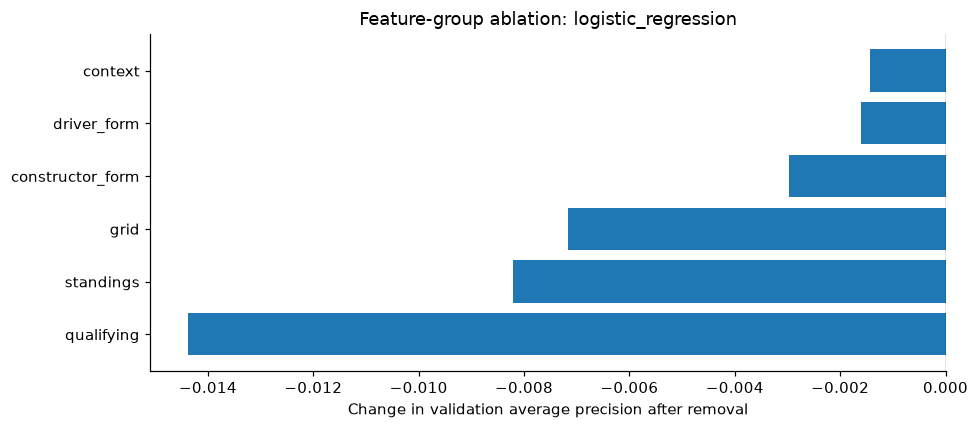

468

In [46]:
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(MODEL_OUT / 'feature_group_ablation.csv', index=False)
print('Validation leader:', leader)
print(ablation.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 4))
view = ablation.loc[ablation['removed_group'].ne('none')].sort_values('delta_pr_auc')
ax.barh(view['removed_group'], view['delta_pr_auc'])
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Change in validation average precision after removal',
       title=f'Feature-group ablation: {leader}')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'feature_group_ablation.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

summary = {'train_rows': len(X_train), 'validation_rows': len(X_valid),
           'test_rows_reserved': int(full_table['split'].eq('test').sum()),
           'feature_count': len(feature_names), 'validation_leader': leader,
           'validation_pr_auc': leader_ap,
           'forest_minus_logistic_ap_interval': ap_difference_interval.tolist(),
           'best_tuned_variant': tuning_results.sort_values('pr_auc', ascending=False).iloc[0]['variant'],
           'selection_policy': 'PR-AUC primary; full-history required; per-family variant selected before repeated test assessment'}
(MODEL_OUT / 'validation_summary.json').write_text(json.dumps(summary, indent=2))

## 21A. Training-range experiment — modern-only baselines
The full-history attempt above uses 24,529 training entries. This separate attempt removes only 1950–2002 training entries, leaving 6,831. Validation and test are shared and never filtered by scope. Historical form is still computed from information available before each event, so this is specifically a training-row scope experiment, matching the original benchmark. Raw feature names stay identical; fitted imputation statistics and learned category vocabulary may legitimately differ because they are learned separately from each training population.

In [47]:

# Attempt B: identical baseline estimators, with only the training-year range changed.
modern_training=training.loc[training['year'].ge(2003)].copy()
X_modern=modern_training[feature_names].copy(); y_modern=modern_training['podium'].astype(int)
assert len(modern_training)==6831 and len(training)==24529
assert len(training)-len(modern_training)==17698
assert not set(training.raceId)&set(validation.raceId)
assert not set(modern_training.raceId)&set(validation.raceId)
assert full_table.groupby('raceId')['split'].nunique().max()==1
modern_variant_models={}; modern_rows=[]

### 21A.1 Modern-only logistic regression baseline

Logistic regression models podium log-odds as an additive function of the encoded inputs. It provides a simple, regularized reference for the nonlinear models. The baseline uses C=1 and a maximum of 1,500 optimization iterations. Its main limitation is that numeric effects are additive unless interactions are supplied explicitly. The training period is 2003–2019; the full-history baseline uses identical model settings.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [48]:
name = 'logistic_regression'
estimator = model_specs[name]
variant = name + '_baseline'
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': name, **score_row(name, 'validation', y_valid, probability, threshold)})
show_attempt_result(modern_rows[-1], float(validation_scores.set_index('model').loc[name, 'pr_auc']), 'the full-history baseline of the same family')

Fitted modern_only logistic_regression_baseline


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,logistic_regression_baseline,logistic_regression,logistic_regression,validation,0.9299,0.7223,0.7041,0.6267,0.8034,0.23,780,0.15


**Result.** Validation AP is **0.7223**, compared with **0.7300** for the full-history baseline of the same family (difference **-0.0077**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21A.2 Modern-only random forest baseline

A forest can capture nonlinear thresholds and interactions between starting position, recent form and standings. The baseline averages 200 trees, with depth limited to 8 and at least 8 entries per leaf. These restrictions limit detailed fitting to individual historical entries. The number of trees is a fixed computational choice, not the result of a tree-count search. The training period is 2003–2019; the full-history baseline uses identical model settings.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [49]:
name = 'random_forest'
estimator = model_specs[name]
variant = name + '_baseline'
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': name, **score_row(name, 'validation', y_valid, probability, threshold)})
show_attempt_result(modern_rows[-1], float(validation_scores.set_index('model').loc[name, 'pr_auc']), 'the full-history baseline of the same family')

Fitted modern_only random_forest_baseline


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,random_forest_baseline,random_forest,random_forest,validation,0.9292,0.73,0.7027,0.7429,0.6667,0.48,780,0.15


**Result.** Validation AP is **0.7300**, compared with **0.7126** for the full-history baseline of the same family (difference **+0.0174**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21A.3 Modern-only shallow neural-network baseline

The network uses one hidden layer of 32 ReLU units and L2 regularization alpha=0.01. It tests whether learned nonlinear combinations improve on the statistical baseline. Early stopping uses a random 15% subset of the outer training set and monitors accuracy. This is separate from the external chronological validation set; it is not a race-grouped, AP-based stopping procedure. The training period is 2003–2019; the full-history baseline uses identical model settings.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [50]:
name = 'shallow_nn'
estimator = model_specs[name]
variant = name + '_baseline'
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': name, **score_row(name, 'validation', y_valid, probability, threshold)})
show_attempt_result(modern_rows[-1], float(validation_scores.set_index('model').loc[name, 'pr_auc']), 'the full-history baseline of the same family')

Fitted modern_only shallow_nn_baseline


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,shallow_nn_baseline,shallow_nn,shallow_nn,validation,0.9207,0.7113,0.7059,0.6942,0.7179,0.295,780,0.15


**Result.** Validation AP is **0.7113**, compared with **0.7149** for the full-history baseline of the same family (difference **-0.0036**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21A. Comparison across attempts

The table and plot collect the attempts above, including settings that did not improve the reference.

,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,logistic_regression_baseline,logistic_regression,logistic_regression,validation,0.929948,0.722293,0.704120,0.626667,0.803419,0.230,780,0.15
1,random_forest_baseline,random_forest,random_forest,validation,0.929175,0.729951,0.702703,0.742857,0.666667,0.480,780,0.15
2,shallow_nn_baseline,shallow_nn,shallow_nn,validation,0.920666,0.711334,0.705882,0.694215,0.717949,0.295,780,0.15


,scope,rows,races,first_year,last_year,podium_rate,qualifying_missing_fraction,q1_missing_fraction
0,full_history,24529,1018,1950,2019,0.124669,0.659342,0.664846
1,modern_only,6831,321,2003,2019,0.140975,0.003367,0.018445


,entries,podium_rate,qualifying_missing,q1_missing
era,,,,
1950–1979,7836,0.126085,1.000000,1.000000
1980–2002,9862,0.112249,0.843034,0.846279
2003–2019,6831,0.140975,0.003367,0.018445
2020–2021,780,0.150000,0.001282,0.011538
2022–2024,1359,0.150110,0.000000,0.009566


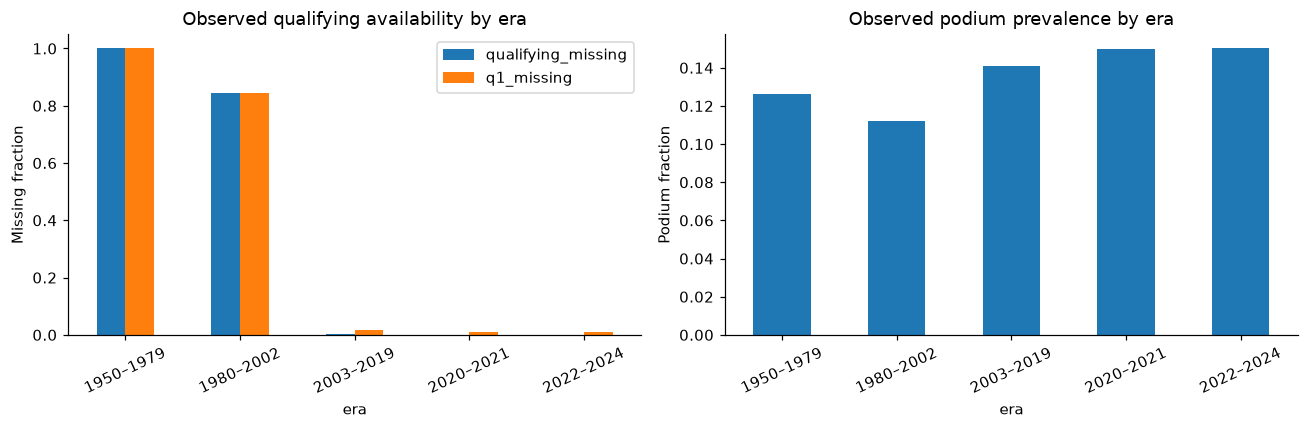

In [51]:
display(pd.DataFrame(modern_rows))
population_rows=[]
for scope,frame in [('full_history',training),('modern_only',modern_training)]:
    population_rows.append({'scope':scope,'rows':len(frame),'races':frame.raceId.nunique(),
        'first_year':frame.year.min(),'last_year':frame.year.max(),'podium_rate':frame.podium.mean(),
        'qualifying_missing_fraction':frame.qualifying_missing.mean(),'q1_missing_fraction':frame.q1_missing.mean()})
population=pd.DataFrame(population_rows)
population.to_csv(COMPARISON_OUT/'training_populations.csv',index=False); display(population)
coverage_era=full_table.assign(era=pd.cut(full_table.year,[1949,1979,2002,2019,2021,2024],
    labels=['1950–1979','1980–2002','2003–2019','2020–2021','2022–2024'])).groupby('era',observed=True).agg(
    entries=('podium','size'),podium_rate=('podium','mean'),qualifying_missing=('qualifying_missing','mean'),q1_missing=('q1_missing','mean'))
coverage_era.to_csv(COMPARISON_OUT/'era_coverage.csv'); display(coverage_era)
fig,axes=plt.subplots(1,2,figsize=(12,4))
coverage_era[['qualifying_missing','q1_missing']].plot.bar(ax=axes[0],rot=25)
axes[0].set(title='Observed qualifying availability by era',ylabel='Missing fraction')
coverage_era['podium_rate'].plot.bar(ax=axes[1],rot=25)
axes[1].set(title='Observed podium prevalence by era',ylabel='Podium fraction')
fig.tight_layout();fig.savefig(COMPARISON_OUT/'era_coverage.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)

## 21B. Same tuning budget for the modern-only attempt
The modern-only comparison uses the same two additional settings per family as the full-history experiment. Every attempt remains visible. The highest validation AP determines the selected variant within each scope and family; the variant name breaks exact ties. Since selected settings can differ, this comparison evaluates the complete selection procedure rather than isolating the training range alone.

In [52]:

# Equal tuning budget: the same two additional settings per family as full history.

### 21B.1 Modern-only logistic regression: stronger regularization

C changes from 1 to 0.1. A smaller C penalizes large coefficients more strongly and may reduce unstable reliance on correlated features. All other settings remain fixed.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [53]:
variant = 'logistic_C_0.1'
family, estimator = tuning_specs[variant]
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': family, **score_row(family, 'validation', y_valid, probability, threshold)})
reference = next(r['pr_auc'] for r in modern_rows if r['variant'] == family + '_baseline')
show_attempt_result(modern_rows[-1], reference, family + ' at its modern-only baseline settings')

Fitted modern_only logistic_C_0.1


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,logistic_C_0.1,logistic_regression,logistic_regression,validation,0.9297,0.7182,0.7063,0.6593,0.7607,0.25,780,0.15


**Result.** Validation AP is **0.7182**, compared with **0.7223** for logistic_regression at its modern-only baseline settings (difference **-0.0041**; lower). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21B.2 Modern-only logistic regression: weaker regularization

C changes from 1 to 3. A larger C allows the coefficients to follow the training data more closely. This tests whether the baseline penalty is too restrictive.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [54]:
variant = 'logistic_C_3'
family, estimator = tuning_specs[variant]
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': family, **score_row(family, 'validation', y_valid, probability, threshold)})
reference = next(r['pr_auc'] for r in modern_rows if r['variant'] == family + '_baseline')
show_attempt_result(modern_rows[-1], reference, family + ' at its modern-only baseline settings')

Fitted modern_only logistic_C_3


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,logistic_C_3,logistic_regression,logistic_regression,validation,0.9291,0.7226,0.7048,0.7273,0.6838,0.39,780,0.15


**Result.** Validation AP is **0.7226**, compared with **0.7223** for logistic_regression at its modern-only baseline settings (difference **+0.0003**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21B.3 Modern-only random forest: shallower trees and larger leaves

Maximum depth changes from 8 to 5 and minimum leaf size from 8 to 12. This is a combined lower-capacity alternative. Any score change belongs to that combination; the experiment does not isolate the effect of either setting alone.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [55]:
variant = 'forest_depth_5_leaf_12'
family, estimator = tuning_specs[variant]
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': family, **score_row(family, 'validation', y_valid, probability, threshold)})
reference = next(r['pr_auc'] for r in modern_rows if r['variant'] == family + '_baseline')
show_attempt_result(modern_rows[-1], reference, family + ' at its modern-only baseline settings')

Fitted modern_only forest_depth_5_leaf_12


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,forest_depth_5_leaf_12,random_forest,random_forest,validation,0.9285,0.7326,0.7068,0.6309,0.8034,0.25,780,0.15


**Result.** Validation AP is **0.7326**, compared with **0.7300** for random_forest at its modern-only baseline settings (difference **+0.0026**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21B.4 Modern-only random forest: deeper trees and smaller leaves

Maximum depth changes from 8 to 12 and minimum leaf size from 8 to 5. The higher-capacity forest can represent more detailed interactions, with a greater risk of overfitting. Both settings change together.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [56]:
variant = 'forest_depth_12_leaf_5'
family, estimator = tuning_specs[variant]
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': family, **score_row(family, 'validation', y_valid, probability, threshold)})
reference = next(r['pr_auc'] for r in modern_rows if r['variant'] == family + '_baseline')
show_attempt_result(modern_rows[-1], reference, family + ' at its modern-only baseline settings')

Fitted modern_only forest_depth_12_leaf_5


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,forest_depth_12_leaf_5,random_forest,random_forest,validation,0.9288,0.7371,0.7018,0.5952,0.8547,0.21,780,0.15


**Result.** Validation AP is **0.7371**, compared with **0.7300** for random_forest at its modern-only baseline settings (difference **+0.0072**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21B.5 Modern-only shallow network: 16 hidden units

The hidden layer shrinks from 32 to 16 units while alpha remains 0.01. This tests whether a smaller representation is sufficient for the available predictors.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [57]:
variant = 'nn_16_alpha_0.01'
family, estimator = tuning_specs[variant]
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': family, **score_row(family, 'validation', y_valid, probability, threshold)})
reference = next(r['pr_auc'] for r in modern_rows if r['variant'] == family + '_baseline')
show_attempt_result(modern_rows[-1], reference, family + ' at its modern-only baseline settings')

Fitted modern_only nn_16_alpha_0.01


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,nn_16_alpha_0.01,shallow_nn,shallow_nn,validation,0.9194,0.7252,0.7089,0.7,0.7179,0.34,780,0.15


**Result.** Validation AP is **0.7252**, compared with **0.7113** for shallow_nn at its modern-only baseline settings (difference **+0.0138**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21B.6 Modern-only shallow network: 64 units with stronger regularization

The hidden layer grows from 32 to 64 units and alpha increases from 0.01 to 0.1. This tests a wider, more strongly penalized network. Width and regularization change together, so their effects cannot be separated from this result.

The fitted pipeline uses training rows only. The result below is evaluated on the same 2020–2021 validation races as its reference.

In [58]:
variant = 'nn_64_alpha_0.1'
family, estimator = tuning_specs[variant]
fitted = fit_with_diagnostics(train_pipeline(clone(estimator)), X_modern, y_modern, 'modern_only', variant)
modern_variant_models[variant] = fitted
probability = fitted.predict_proba(X_valid)[:, 1]
threshold = best_f1_threshold(y_valid, probability)
modern_rows.append({'variant': variant, 'family': family, **score_row(family, 'validation', y_valid, probability, threshold)})
reference = next(r['pr_auc'] for r in modern_rows if r['variant'] == family + '_baseline')
show_attempt_result(modern_rows[-1], reference, family + ' at its modern-only baseline settings')

Fitted modern_only nn_64_alpha_0.1


,variant,family,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,nn_64_alpha_0.1,shallow_nn,shallow_nn,validation,0.9263,0.7196,0.7107,0.688,0.735,0.365,780,0.15


**Result.** Validation AP is **0.7196**, compared with **0.7113** for shallow_nn at its modern-only baseline settings (difference **+0.0083**; higher). This is an observed difference on the same validation races, not a claim of statistically established superiority.

### 21B. Comparison across attempts

The table and plot collect the attempts above, including settings that did not improve the reference.

In [59]:
modern_tuning_results=pd.DataFrame(modern_rows)
modern_tuning_results.to_csv(COMPARISON_OUT/'modern_validation_variants.csv',index=False)
all_variants=pd.concat([tuning_results.assign(scope='full_history'),
    modern_tuning_results.assign(scope='modern_only')],ignore_index=True)
all_variants.to_csv(COMPARISON_OUT/'all_validation_variants.csv',index=False)
display(all_variants[['scope','family','variant','pr_auc','roc_auc','f1','threshold']].sort_values(['family','scope','pr_auc'],ascending=[True,True,False]))
scope_models={'full_history':variant_models,'modern_only':modern_variant_models}
selection_rows=[]
for (scope,family),part in all_variants.groupby(['scope','family']):
    # AP is primary; deterministic variant-name tie-break, no test data used.
    chosen=part.sort_values(['pr_auc','variant'],ascending=[False,True]).iloc[0]
    selection_rows.append({'scope':scope,'family':family,'variant':chosen.variant,
        'validation_ap':float(chosen.pr_auc),'threshold':float(chosen.threshold)})
selections=pd.DataFrame(selection_rows)
selections.to_csv(COMPARISON_OUT/'validation_selected_variants.csv',index=False)
display(selections)

,scope,family,variant,pr_auc,roc_auc,f1,threshold
0,full_history,logistic_regression,logistic_regression_baseline,0.730029,0.928324,0.705426,0.270
1,full_history,logistic_regression,logistic_C_0.1,0.727909,0.927924,0.704918,0.305
2,full_history,logistic_regression,logistic_C_3,0.727654,0.927769,0.709677,0.300
13,modern_only,logistic_regression,logistic_C_3,0.722598,0.929110,0.704846,0.390
9,modern_only,logistic_regression,logistic_regression_baseline,0.722293,0.929948,0.704120,0.230
12,modern_only,logistic_regression,logistic_C_0.1,0.718210,0.929716,0.706349,0.250
3,full_history,random_forest,forest_depth_12_leaf_5,0.725262,0.926042,0.702222,0.445
4,full_history,random_forest,random_forest_baseline,0.712593,0.923425,0.700422,0.395
5,full_history,random_forest,forest_depth_5_leaf_12,0.708411,0.920215,0.691667,0.355
15,modern_only,random_forest,forest_depth_12_leaf_5,0.737130,0.928788,0.701754,0.210


,scope,family,variant,validation_ap,threshold
0,full_history,logistic_regression,logistic_regression_baseline,0.730029,0.270
1,full_history,random_forest,forest_depth_12_leaf_5,0.725262,0.445
2,full_history,shallow_nn,nn_16_alpha_0.01,0.727297,0.365
3,modern_only,logistic_regression,logistic_C_3,0.722598,0.390
4,modern_only,random_forest,forest_depth_12_leaf_5,0.737130,0.210
5,modern_only,shallow_nn,nn_16_alpha_0.01,0.725153,0.340


## 21C. Paired validation comparison and decision before test
The comparison estimates full-history minus modern-only AP with 1,000 paired whole-race bootstrap resamples. The same sampled race positions are used for both predictions. Positive means full history scores higher; an interval spanning zero does not establish equivalence. Intervals are conditional on these fits and do not adjust for hyperparameter selection or the six displayed comparisons. The interpretation uses the observed differences and these uncertainty limits.

,scope,phase,variant,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
0,full_history,fixed_baseline,logistic_regression_baseline,logistic_regression,validation,0.928324,0.730029,0.705426,0.645390,0.777778,0.270,780,0.15
1,modern_only,fixed_baseline,logistic_regression_baseline,logistic_regression,validation,0.929948,0.722293,0.704120,0.626667,0.803419,0.230,780,0.15
2,full_history,fixed_baseline,random_forest_baseline,random_forest,validation,0.923425,0.712593,0.700422,0.691667,0.709402,0.395,780,0.15
3,modern_only,fixed_baseline,random_forest_baseline,random_forest,validation,0.929175,0.729951,0.702703,0.742857,0.666667,0.480,780,0.15
4,full_history,fixed_baseline,shallow_nn_baseline,shallow_nn,validation,0.928117,0.714884,0.698413,0.651852,0.752137,0.340,780,0.15
5,modern_only,fixed_baseline,shallow_nn_baseline,shallow_nn,validation,0.920666,0.711334,0.705882,0.694215,0.717949,0.295,780,0.15
6,full_history,validation_selected,logistic_regression_baseline,logistic_regression,validation,0.928324,0.730029,0.705426,0.645390,0.777778,0.270,780,0.15
7,modern_only,validation_selected,logistic_C_3,logistic_regression,validation,0.929110,0.722598,0.704846,0.727273,0.683761,0.390,780,0.15
8,full_history,validation_selected,forest_depth_12_leaf_5,random_forest,validation,0.926042,0.725262,0.702222,0.731481,0.675214,0.445,780,0.15
9,modern_only,validation_selected,forest_depth_12_leaf_5,random_forest,validation,0.928788,0.737130,0.701754,0.595238,0.854701,0.210,780,0.15


,phase,model,full_minus_modern_validation_ap,lower95,upper95,replicates,interval_excludes_zero
0,fixed_baseline,logistic_regression,0.007736,-0.007013,0.024359,1000,False
1,fixed_baseline,random_forest,-0.017358,-0.037706,0.006788,1000,False
2,fixed_baseline,shallow_nn,0.003551,-0.019846,0.030874,1000,False
3,validation_selected,logistic_regression,0.007431,-0.006323,0.023406,1000,False
4,validation_selected,random_forest,-0.011868,-0.029849,0.007517,1000,False
5,validation_selected,shallow_nn,0.002144,-0.016262,0.020139,1000,False


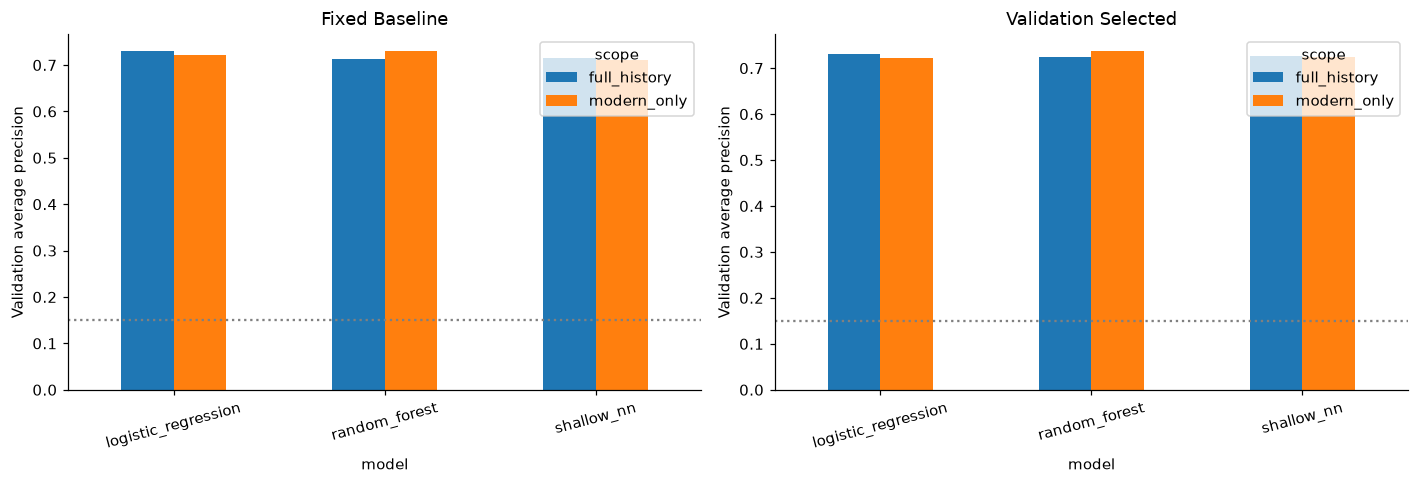

**fixed_baseline / logistic_regression:** full history has higher observed validation AP; full minus modern = +0.0077, approximate paired race-bootstrap 95% interval [-0.0070, +0.0244] (interval includes zero).

**fixed_baseline / random_forest:** modern-only has higher observed validation AP; full minus modern = -0.0174, approximate paired race-bootstrap 95% interval [-0.0377, +0.0068] (interval includes zero).

**fixed_baseline / shallow_nn:** full history has higher observed validation AP; full minus modern = +0.0036, approximate paired race-bootstrap 95% interval [-0.0198, +0.0309] (interval includes zero).

**validation_selected / logistic_regression:** full history has higher observed validation AP; full minus modern = +0.0074, approximate paired race-bootstrap 95% interval [-0.0063, +0.0234] (interval includes zero).

**validation_selected / random_forest:** modern-only has higher observed validation AP; full minus modern = -0.0119, approximate paired race-bootstrap 95% interval [-0.0298, +0.0075] (interval includes zero).

**validation_selected / shallow_nn:** full history has higher observed validation AP; full minus modern = +0.0021, approximate paired race-bootstrap 95% interval [-0.0163, +0.0201] (interval includes zero).

**Decision before repeated test assessment:** full-history logistic_regression_baseline is the performance leader on validation (AP 0.7300). The best modern-only variant is forest_depth_12_leaf_5 (AP 0.7371). All three full-history families are retained; logistic regression supplies the explanatory baseline. The scope is chosen for compliance, not by test scores.

In [60]:

scope_comparison_rows=[]; scope_validation_probabilities={}; paired_rows=[]
for phase in ['fixed_baseline','validation_selected']:
    for family in model_specs:
        for scope in ['full_history','modern_only']:
            if phase=='fixed_baseline':
                variant=family+'_baseline'
                cfg=all_variants.loc[all_variants.scope.eq(scope)&all_variants.variant.eq(variant)].iloc[0]
                threshold=float(cfg.threshold)
            else:
                cfg=selections.loc[selections.scope.eq(scope)&selections.family.eq(family)].iloc[0]
                variant=cfg.variant;threshold=float(cfg.threshold)
            probability=scope_models[scope][variant].predict_proba(X_valid)[:,1]
            scope_validation_probabilities[(phase,family,scope)]=probability
            scope_comparison_rows.append({'scope':scope,'phase':phase,'variant':variant,
                **score_row(family,'validation',y_valid,probability,threshold)})
        modern_p=scope_validation_probabilities[(phase,family,'modern_only')]
        full_p=scope_validation_probabilities[(phase,family,'full_history')]
        delta=average_precision_score(y_valid,full_p)-average_precision_score(y_valid,modern_p)
        rng=np.random.default_rng(903);differences=[]
        for _ in range(1000):
            sampled=rng.choice(unique_races,size=len(unique_races),replace=True)
            positions=np.concatenate([race_positions[race] for race in sampled])
            labels=y_valid.to_numpy()[positions]
            differences.append(average_precision_score(labels,full_p[positions])-average_precision_score(labels,modern_p[positions]))
        lo,hi=np.quantile(differences,[.025,.975])
        paired_rows.append({'phase':phase,'model':family,'full_minus_modern_validation_ap':delta,
            'lower95':lo,'upper95':hi,'replicates':1000,'interval_excludes_zero':bool(lo>0 or hi<0)})
scope_validation=pd.DataFrame(scope_comparison_rows)
scope_validation.to_csv(COMPARISON_OUT/'validation_scope_comparison.csv',index=False)
paired=pd.DataFrame(paired_rows); paired.to_csv(COMPARISON_OUT/'paired_race_bootstrap.csv',index=False)
pd.DataFrame(convergence_records).to_csv(COMPARISON_OUT/'fit_diagnostics.csv',index=False)
display(scope_validation);display(paired)
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,phase in zip(axes,['fixed_baseline','validation_selected']):
    view=scope_validation.loc[scope_validation.phase.eq(phase)].pivot(index='model',columns='scope',values='pr_auc')
    view.plot.bar(ax=ax,rot=15)
    ax.set(title=phase.replace('_',' ').title(),ylabel='Validation average precision')
    ax.axhline(y_valid.mean(),color='gray',linestyle=':')
fig.tight_layout();fig.savefig(COMPARISON_OUT/'validation_scope_comparison.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
for row in paired.itertuples():
    scope='full history' if row.full_minus_modern_validation_ap>0 else 'modern-only'
    caveat='interval excludes zero' if row.interval_excludes_zero else 'interval includes zero'
    display(Markdown(f'**{row.phase} / {row.model}:** {scope} has higher observed validation AP; '
        f'full minus modern = {row.full_minus_modern_validation_ap:+.4f}, approximate paired race-bootstrap '
        f'95% interval [{row.lower95:+.4f}, {row.upper95:+.4f}] ({caveat}).'))
full_winner=selections.loc[selections.scope.eq('full_history')].sort_values(['validation_ap','family'],ascending=[False,True]).iloc[0]
modern_winner=selections.loc[selections.scope.eq('modern_only')].sort_values(['validation_ap','family'],ascending=[False,True]).iloc[0]
decision={'required_scope':'full_history','primary_metric':'average_precision',
    'performance_leader':full_winner.family,'selected_full_variant':full_winner.variant,
    'full_validation_ap':float(full_winner.validation_ap),
    'modern_comparator_variant':modern_winner.variant,'modern_validation_ap':float(modern_winner.validation_ap),
    'explanatory_model':'logistic_regression','prior_test_exposure':True,
    'reason':'Use all history to satisfy instructor scope; choose the highest validation-AP variant within each family. Report modern-only as a controlled sensitivity experiment, not a scope waiver.'}
(COMPARISON_OUT/'decision_before_test.json').write_text(json.dumps(decision,indent=2))
display(Markdown(f'**Decision before repeated test assessment:** full-history {full_winner.variant} is the '
    f'performance leader on validation (AP {full_winner.validation_ap:.4f}). The best modern-only variant is '
    f'{modern_winner.variant} (AP {modern_winner.validation_ap:.4f}). All three full-history families are retained; '
    'logistic regression supplies the explanatory baseline. The scope is chosen for compliance, not by test scores.'))



## 22. Validation-frozen full-history configurations
The six scope/family selections above are frozen before this revision's test scoring. Each family uses its highest validation-AP variant; thresholds maximize validation F1. The main submission uses full history regardless of which scope wins empirically. The highest validation-AP full-history family is the performance leader; logistic regression remains the explicitly labeled explanatory baseline for linear SHAP and inference. These are different roles, not a claim that logistic always ranks best.

The baseline forest/logistic interval earlier applies only to those baseline models. The scope experiment computes its own paired intervals for the actual compared predictions. No claim of tuned-model equivalence is inferred from a baseline interval. Test scores were previously exposed under the narrower version and are reported transparently as repeated assessment.


## 23. Repeated later-period assessment of frozen configurations
The previously exposed 2022–2024 period is scored after settings are selected using validation. The full-history pipeline retains all training rows and is not refitted on validation. Both scopes use the same ordered test entries, with paired predictions exported for audit. Test performance does not select the preferred scope. The main full-history comparison includes all five required metrics on training, validation and test.

/home/soryal/Youssif/College/Sem 9/ACL/ACL Project/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


              model      split  roc_auc  pr_auc     f1  precision  recall  threshold  rows  podium_rate
logistic_regression      train   0.9110  0.5744 0.5895     0.4969  0.7247      0.270 24529       0.1247
logistic_regression validation   0.9283  0.7300 0.7054     0.6454  0.7778      0.270   780       0.1500
logistic_regression       test   0.9349  0.6989 0.6762     0.5784  0.8137      0.270  1359       0.1501
      random_forest      train   0.9203  0.6352 0.5174     0.6871  0.4150      0.445 24529       0.1247
      random_forest validation   0.9260  0.7253 0.7022     0.7315  0.6752      0.445   780       0.1500
      random_forest       test   0.9354  0.7028 0.6565     0.6825  0.6324      0.445  1359       0.1501
         shallow_nn      train   0.9137  0.5941 0.5880     0.5326  0.6563      0.365 24529       0.1247
         shallow_nn validation   0.9240  0.7273 0.7083     0.6911  0.7265      0.365   780       0.1500
         shallow_nn       test   0.9331  0.6955 0.6529     0.614

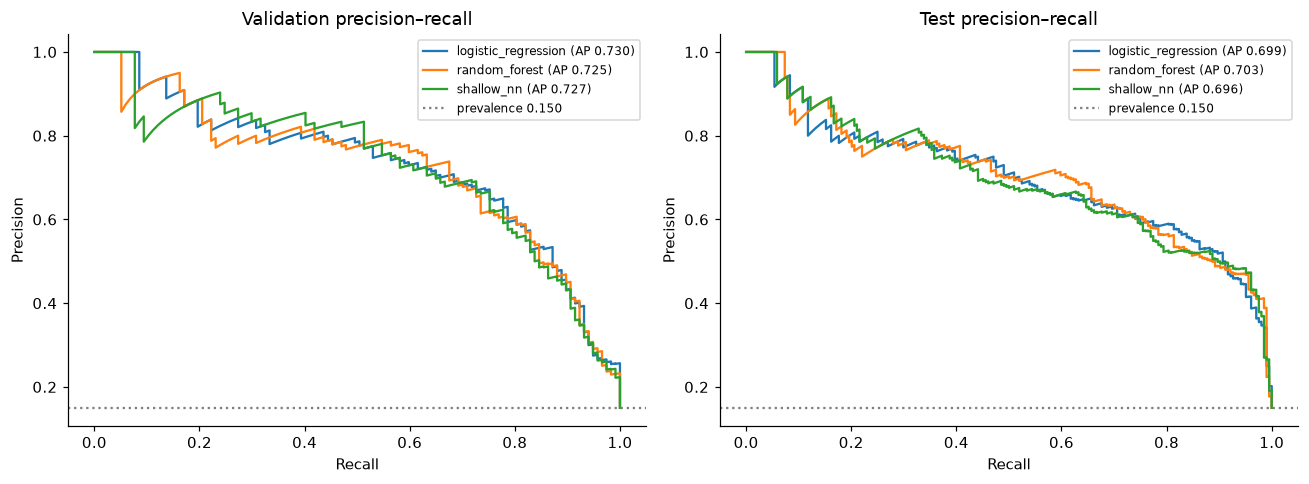

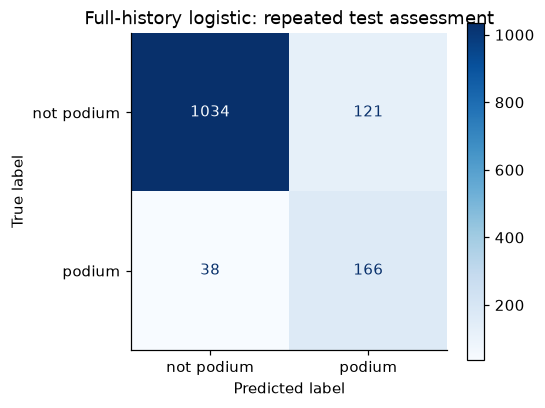

,scope,phase,variant,model,split,roc_auc,pr_auc,f1,precision,recall,threshold,rows,podium_rate
2,full_history,fixed_baseline,logistic_regression_baseline,logistic_regression,test,0.934887,0.698874,0.676171,0.578397,0.813725,0.270,1359,0.15011
5,modern_only,fixed_baseline,logistic_regression_baseline,logistic_regression,test,0.933584,0.701305,0.663918,0.572954,0.789216,0.230,1359,0.15011
8,full_history,fixed_baseline,random_forest_baseline,random_forest,test,0.933439,0.696045,0.657143,0.638889,0.676471,0.395,1359,0.15011
11,modern_only,fixed_baseline,random_forest_baseline,random_forest,test,0.938592,0.710662,0.640420,0.689266,0.598039,0.480,1359,0.15011
14,full_history,fixed_baseline,shallow_nn_baseline,shallow_nn,test,0.933091,0.686131,0.675214,0.598485,0.774510,0.340,1359,0.15011
17,modern_only,fixed_baseline,shallow_nn_baseline,shallow_nn,test,0.925847,0.679767,0.605128,0.634409,0.578431,0.295,1359,0.15011
20,full_history,validation_selected,logistic_regression_baseline,logistic_regression,test,0.934887,0.698874,0.676171,0.578397,0.813725,0.270,1359,0.15011
23,modern_only,validation_selected,logistic_C_3,logistic_regression,test,0.933724,0.699910,0.645995,0.683060,0.612745,0.390,1359,0.15011
26,full_history,validation_selected,forest_depth_12_leaf_5,random_forest,test,0.935409,0.702846,0.656489,0.682540,0.632353,0.445,1359,0.15011
29,modern_only,validation_selected,forest_depth_12_leaf_5,random_forest,test,0.938787,0.714141,0.638796,0.484772,0.936275,0.210,1359,0.15011


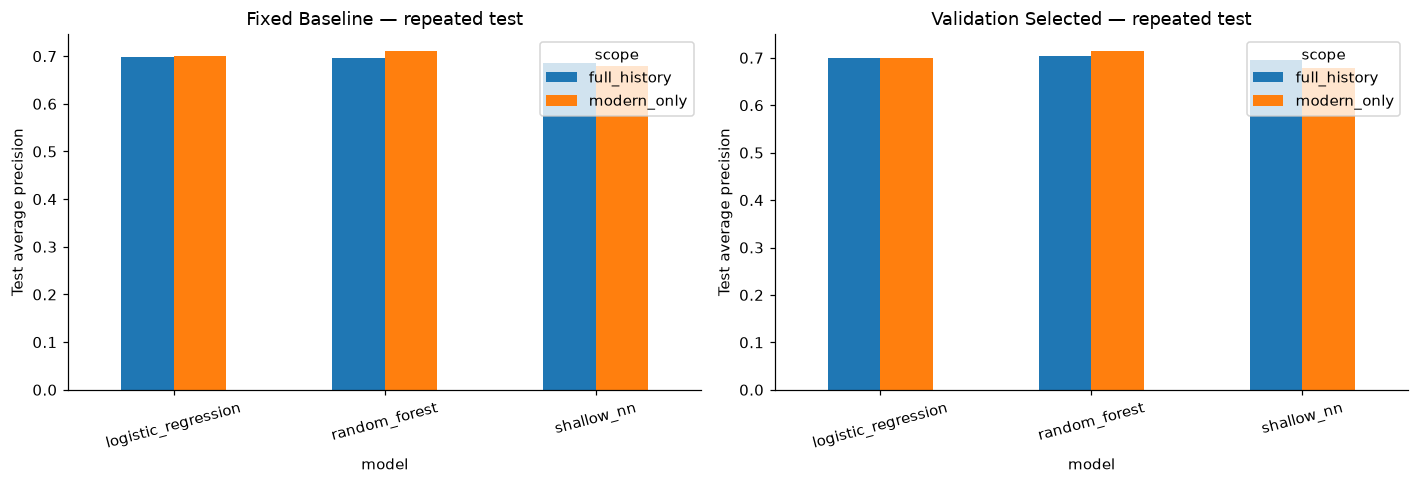

**Scope justification:** the full-history version meets the required historical coverage. The controlled modern-only experiment measures the effect of restricting training years. Its observed advantage or disadvantage must be quoted from the tables, not assumed. Model variants are justified by validation AP; test results only describe the fixed decisions.

In [61]:
from sklearn.base import clone
from sklearn.metrics import ConfusionMatrixDisplay
import shap
from lime.lime_tabular import LimeTabularExplainer

FROZEN={}
for row in selections.loc[selections.scope.eq('full_history')].itertuples():
    FROZEN[row.family]={'variant':row.variant,'estimator':variant_models[row.variant].named_steps['model'],
        'threshold':row.threshold,'reason':'Highest validation AP within the same prespecified family grid.'}
assert set(FROZEN) == set(model_specs)
assert set(feature_names) == set(X_train.columns) == set(X_valid.columns)
test_cohort = full_table.loc[full_table['split'].eq('test')].copy()
assert validation['date'].max() < test_cohort['date'].min()
assert len(test_cohort) == 1359 and not test_cohort.duplicated(['raceId','driverId']).any()
X_test = test_cohort[feature_names].copy()
y_test = test_cohort['podium'].astype(int)
final_models, final_probabilities, final_rows = {}, {}, []
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for name, config in FROZEN.items():
        fitted = variant_models[config['variant']]  # already fitted on training only
        threshold = config['threshold']
        for split_name, x, y in [('train', X_train, y_train),
                                 ('validation', X_valid, y_valid),
                                 ('test', X_test, y_test)]:
            probability = fitted.predict_proba(x)[:, 1]
            final_rows.append(score_row(name, split_name, y, probability, threshold))
            final_probabilities[(name, split_name)] = probability
        final_models[name] = fitted
final_comparison = pd.DataFrame(final_rows)
final_comparison.to_csv(MODEL_OUT / 'frozen_model_comparison.csv', index=False)
print(final_comparison.round(4).to_string(index=False))
(MODEL_OUT / 'frozen_selection.json').write_text(json.dumps({
    'primary_metric': 'PR-AUC (average precision)',
    'lead_model': full_winner.family, 'explanatory_model':'logistic_regression',
    'prior_test_exposure':True,
    'features': feature_names,
    'train_years': '1950-2019', 'validation_years': '2020-2021', 'test_years': '2022-2024',
    'models': {name: {'variant':cfg['variant'],'threshold': cfg['threshold'], 'reason': cfg['reason'],
                           'parameters':cfg['estimator'].get_params()}
               for name, cfg in FROZEN.items()},
    'test_used_for_selection': False,
}, indent=2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, split_name, y in [(axes[0], 'validation', y_valid), (axes[1], 'test', y_test)]:
    for name in FROZEN:
        probability = final_probabilities[(name, split_name)]
        precision, recall, _ = precision_recall_curve(y, probability)
        ax.plot(recall, precision, label=f'{name} (AP {average_precision_score(y, probability):.3f})')
    ax.axhline(y.mean(), color='gray', linestyle=':', label=f'prevalence {y.mean():.3f}')
    ax.set(xlabel='Recall', ylabel='Precision', title=f'{split_name.title()} precision–recall')
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(MODEL_OUT / 'frozen_precision_recall.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
lead_threshold = FROZEN['logistic_regression']['threshold']
lead_test_prediction = final_probabilities[('logistic_regression','test')] >= lead_threshold
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, lead_test_prediction,
    display_labels=['not podium','podium'], cmap='Blues', values_format='d', ax=ax)
ax.set_title('Full-history logistic: repeated test assessment')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'lead_test_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
# Same-row external assessment of both training scopes; settings remain frozen.
assessment_rows=[]; prediction_rows=[]
for row in scope_validation.itertuples():
    fitted=scope_models[row.scope][row.variant]
    scope_x,scope_y=(X_train,y_train) if row.scope=='full_history' else (X_modern,y_modern)
    for split_name,x,y,meta in [('train',scope_x,scope_y,training if row.scope=='full_history' else modern_training),
                               ('validation',X_valid,y_valid,validation),('test',X_test,y_test,test_cohort)]:
        probability=fitted.predict_proba(x)[:,1]
        assessment_rows.append({'scope':row.scope,'phase':row.phase,'variant':row.variant,
            **score_row(row.model,split_name,y,probability,row.threshold)})
        if split_name!='train':
            frame=meta[['raceId','driverId','date','podium']].copy()
            frame['scope']=row.scope;frame['phase']=row.phase;frame['model']=row.model
            frame['variant']=row.variant;frame['split']=split_name;frame['probability']=probability
            frame['threshold']=row.threshold;prediction_rows.append(frame)
assessment=pd.DataFrame(assessment_rows)
assessment.to_csv(COMPARISON_OUT/'all_scope_scores.csv',index=False)
pd.concat(prediction_rows,ignore_index=True).to_csv(COMPARISON_OUT/'paired_predictions.csv',index=False)
assert not pd.concat(prediction_rows).duplicated(['scope','phase','model','split','raceId','driverId']).any()
display(assessment.loc[assessment.split.eq('test')])
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,phase in zip(axes,['fixed_baseline','validation_selected']):
    assessment.loc[assessment.split.eq('test')&assessment.phase.eq(phase)].pivot(index='model',columns='scope',values='pr_auc').plot.bar(ax=ax,rot=15)
    ax.set(title=phase.replace('_',' ').title()+' — repeated test',ylabel='Test average precision')
fig.tight_layout();fig.savefig(COMPARISON_OUT/'test_scope_comparison.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
display(Markdown('**Scope justification:** the full-history version meets the required historical coverage. '
    'The controlled modern-only experiment measures the effect of restricting training years. '
    'Its observed advantage or disadvantage must be quoted from the tables, not assumed. '
    'Model variants are justified by validation AP; test results only describe the fixed decisions.'))


## 24. Global explanations

Permutation importance measures the loss in validation PR-AUC when one raw feature is shuffled. Linear SHAP attributes the logistic model’s log-odds on 200 validation entries relative to a training background. Both are model explanations; correlated predictors can split or obscure importance, and neither method establishes a causal effect.

Permutation importance (validation PR-AUC):
                   feature  mean_ap_drop  repeat_std
             grid_position        0.2192      0.0386
      driver_points_before        0.1139      0.0205
 constructor_points_before        0.0370      0.0112
       qualifying_position        0.0301      0.0216
      constructor_category        0.0295      0.0120
   constructor_wins_before        0.0162      0.0193
                     round        0.0133      0.0082
                 grid_zero        0.0124      0.0113
                q1_missing        0.0124      0.0143
      driver_podium_rate_5        0.0078      0.0059
grid_qualifying_difference        0.0062      0.0056
   constructor_rank_before        0.0046      0.0062


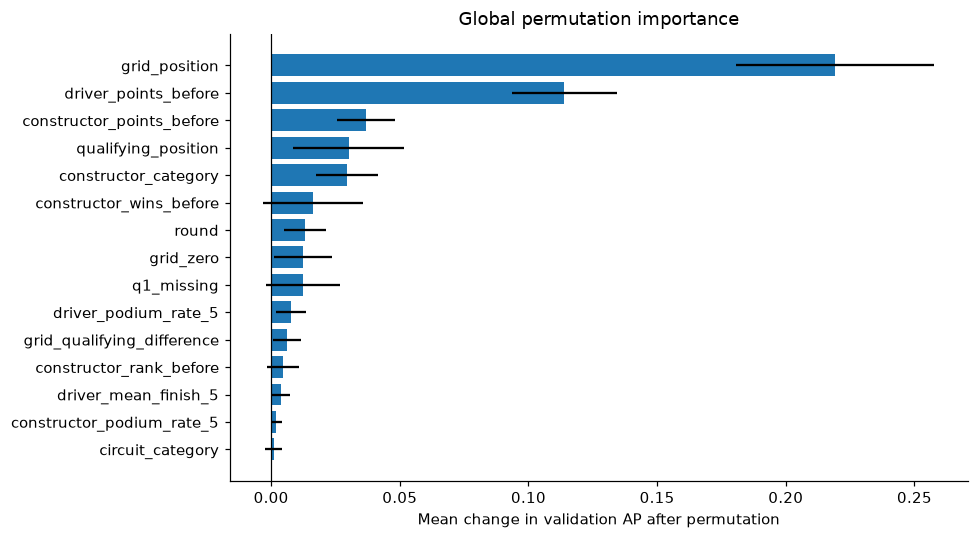

SHAP global importance (validation; log-odds units):
                                       feature  mean_absolute_log_odds_shap
                           numeric__q1_missing                       1.2380
                        numeric__grid_position                       1.0593
                   numeric__qualifying_missing                       0.9734
                  numeric__qualifying_position                       0.3663
                            numeric__grid_zero                       0.3532
                                 numeric__year                       0.3504
                 numeric__driver_points_before                       0.1912
  category__constructor_category_constructor_6                       0.1482
            numeric__constructor_points_before                       0.1364
category__constructor_category_constructor_210                       0.1241
              numeric__constructor_rank_before                       0.1229
  category__constructor_category_co

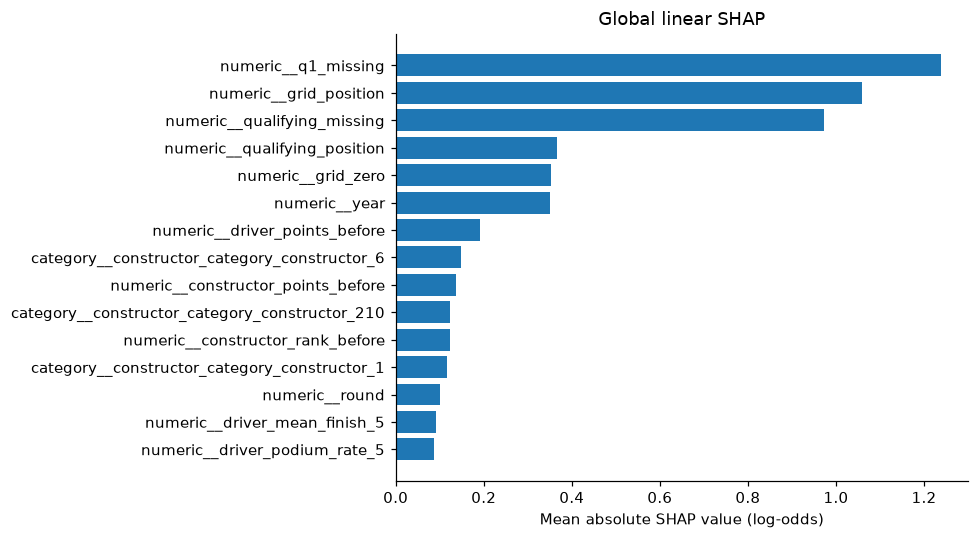

**Computed interpretation:** largest validation permutation AP drops: grid_position: 0.2192; driver_points_before: 0.1139; constructor_points_before: 0.0370. Largest mean absolute Linear SHAP terms: numeric__q1_missing: 1.2380; numeric__grid_position: 1.0593; numeric__qualifying_missing: 0.9734. SHAP units are log-odds; neither method establishes causation.

**Reading the two explanations.** Permutation measures the change in validation AP after an input is shuffled in a fixed fitted model. SHAP measures contributions relative to a historical training background. Qualifying absence is much more common in that background than in modern validation races, so missingness indicators can have large SHAP magnitudes without the largest permutation drops. The two plots answer different questions; neither establishes causation.

In [62]:
lead = final_models['logistic_regression']
from sklearn.inspection import permutation_importance
permuted = permutation_importance(lead, X_valid, y_valid,
    scoring='average_precision', n_repeats=12, random_state=903, n_jobs=2)
permutation_table = pd.DataFrame({
    'feature': feature_names, 'mean_ap_drop': permuted.importances_mean,
    'repeat_std': permuted.importances_std,
}).sort_values('mean_ap_drop', ascending=False)
permutation_table.to_csv(MODEL_OUT / 'permutation_importance.csv', index=False)
print('Permutation importance (validation PR-AUC):')
print(permutation_table.head(12).round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 5))
view = permutation_table.head(15).sort_values('mean_ap_drop')
ax.barh(view['feature'], view['mean_ap_drop'], xerr=view['repeat_std'])
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Mean change in validation AP after permutation',
       title='Global permutation importance')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'permutation_importance.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

encoder = lead.named_steps['prepare']
encoded_names = encoder.get_feature_names_out()
encoded_train = np.asarray(encoder.transform(X_train), dtype=float)
encoded_valid = np.asarray(encoder.transform(X_valid), dtype=float)
background = shap.maskers.Independent(encoded_train[np.linspace(0,len(encoded_train)-1,min(250,len(encoded_train)),dtype=int)], max_samples=250)
shap_explainer = shap.LinearExplainer(lead.named_steps['model'], background,
                                     feature_names=encoded_names)
shap_values = shap_explainer(encoded_valid[:200])
assert shap_values.values.shape == (200, len(encoded_names))
shap_global = pd.DataFrame({'feature': encoded_names,
    'mean_absolute_log_odds_shap': np.abs(shap_values.values).mean(axis=0)}).sort_values(
    'mean_absolute_log_odds_shap', ascending=False)
shap_global.to_csv(MODEL_OUT / 'shap_global.csv', index=False)
print('SHAP global importance (validation; log-odds units):')
print(shap_global.head(12).round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 5))
view = shap_global.head(15).sort_values('mean_absolute_log_odds_shap')
ax.barh(view['feature'], view['mean_absolute_log_odds_shap'])
ax.set(xlabel='Mean absolute SHAP value (log-odds)', title='Global linear SHAP')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'shap_global.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
display(Markdown('**Computed interpretation:** largest validation permutation AP drops: '+
    '; '.join(f'{r.feature}: {r.mean_ap_drop:.4f}' for r in permutation_table.head(3).itertuples())+
    '. Largest mean absolute Linear SHAP terms: '+
    '; '.join(f'{r.feature}: {r.mean_absolute_log_odds_shap:.4f}' for r in shap_global.head(3).itertuples())+
    '. SHAP units are log-odds; neither method establishes causation.'))

# Explain why reference-relative SHAP and permutation can rank missingness differently.
display(Markdown(
    '**Reading the two explanations.** Permutation measures the change in validation AP '
    'after an input is shuffled in a fixed fitted model. SHAP measures contributions '
    'relative to a historical training background. Qualifying absence is much more '
    'common in that background than in modern validation races, so missingness '
    'indicators can have large SHAP magnitudes without the largest permutation drops. '
    'The two plots answer different questions; neither establishes causation.'
))


**Interpretation scope.** The computed paragraph above reflects this full-history fit. Qualifying/grid may share correlated information. SHAP summarizes the first 200 chronological validation entries against 250 evenly spaced training reference rows; its population and units differ from permutation AP drops. The values reported here come from the full-history fit.

## 25. One local explanation

For a reproducible validation entry with probability closest to 0.5, SHAP explains the model’s log-odds and LIME fits a local surrogate. LIME perturbs encoded inputs independently, so some synthetic one-hot combinations need not correspond to a real race entry. Compare direction and magnitude cautiously.

Local validation case: {'raceId': 1053, 'driverId': 830, 'date': '2021-04-18', 'podium': 1, 'predicted_probability': 0.5014643161584743, 'threshold': 0.26999999999999996}


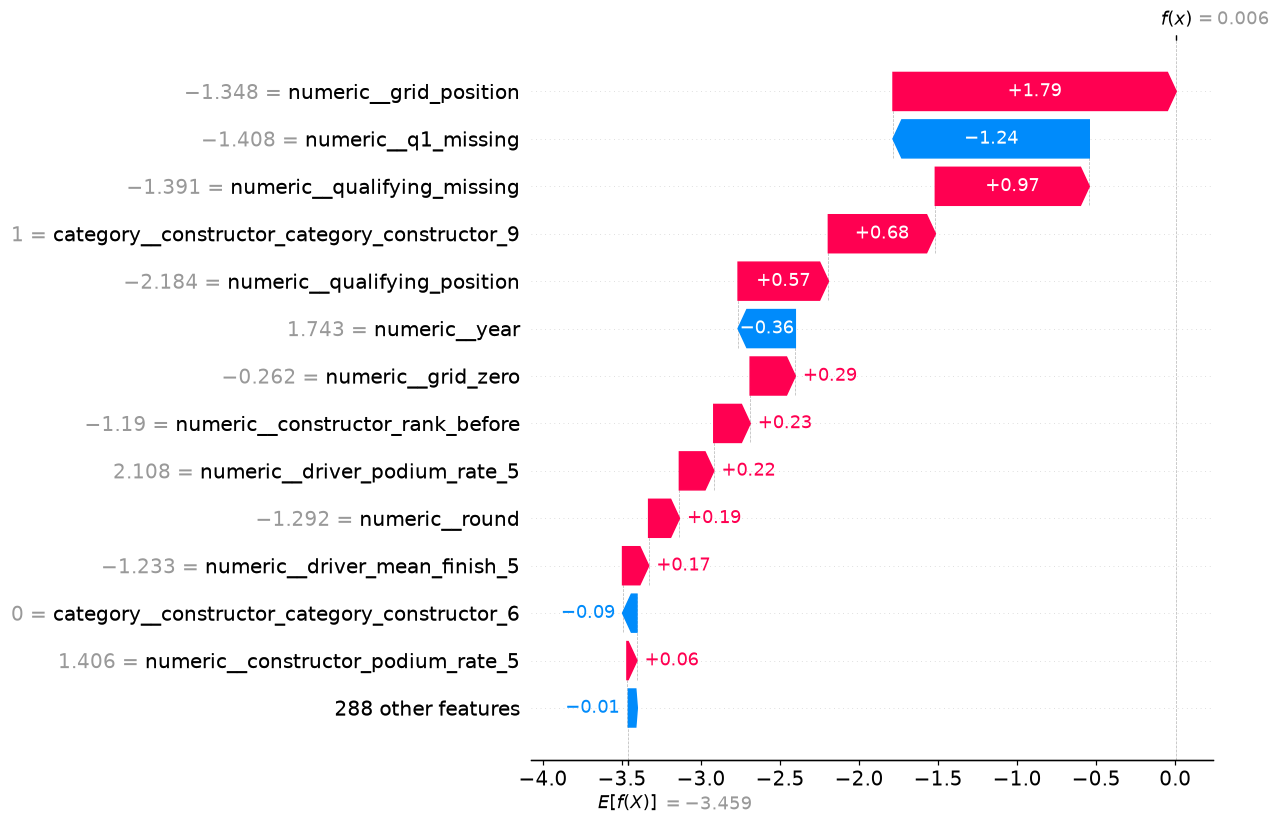

LIME local conditions:
                                       condition  local_weight
category__constructor_category_constructor_107=0       -0.1591
                 numeric__grid_position <= -0.75        0.1284
category__constructor_category_constructor_125=0       -0.0866
category__constructor_category_constructor_168=0       -0.0789
                     numeric__grid_zero <= -0.26        0.0698
 category__constructor_category_constructor_52=0        0.0482
 category__constructor_category_constructor_59=0       -0.0465
         category__circuit_category_circuit_59=0        0.0373
category__constructor_category_constructor_162=0       -0.0177
category__constructor_category_constructor_140=0       -0.0170
         category__circuit_category_circuit_73=0       -0.0113
 category__constructor_category_constructor_75=0        0.0068


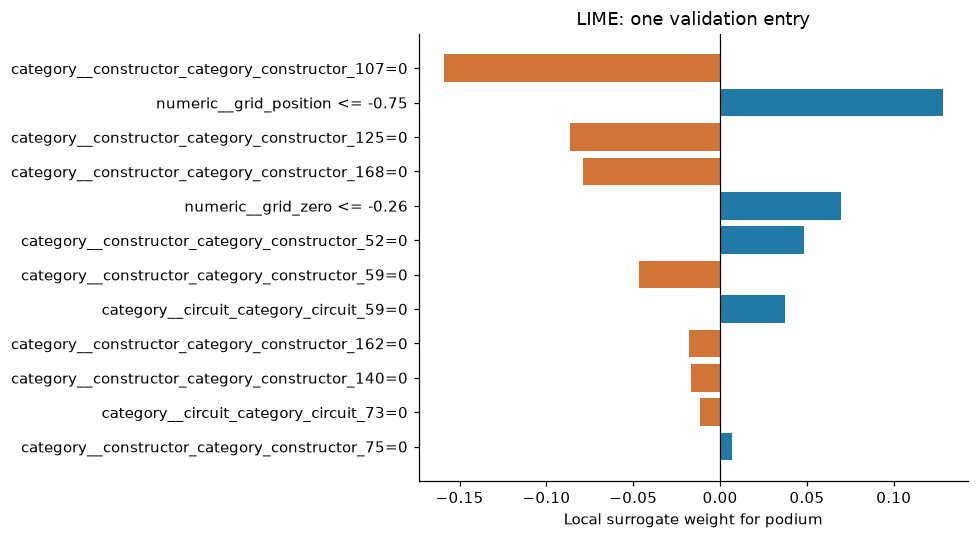

**Computed local interpretation:** race 1053, driver 830; probability 0.5015, threshold 0.270; predicted podium: True. The SHAP additivity assertion passed. Strongest absolute LIME condition: category__constructor_category_constructor_107=0.

**Local SHAP.** The largest upward contributions are numeric__grid_position (+1.791); numeric__qualifying_missing (+0.973); category__constructor_category_constructor_9 (+0.677); the largest downward contributions are numeric__q1_missing (-1.241); numeric__year (-0.362); category__constructor_category_constructor_6 (-0.091). These contributions are in log-odds relative to the training reference, not probability points.

**Local LIME.** Positive surrogate terms: numeric__grid_position <= -0.75 (+0.128); numeric__grid_zero <= -0.26 (+0.070). Negative surrogate terms: category__constructor_category_constructor_107=0 (-0.159); category__constructor_category_constructor_125=0 (-0.087). Numeric cutoffs are in standardized units. A negative standardized grid value does not mean a negative physical starting position. Conditions on absent historical team indicators reflect the synthetic neighborhood and are not sporting causal claims.

In [63]:
validation_lead_probability = final_probabilities[('logistic_regression','validation')]
local_position = int(np.argmin(np.abs(validation_lead_probability - 0.5)))
local_shap = shap_explainer(encoded_valid[[local_position]])[0]
local_log_odds = float(lead.named_steps['model'].decision_function(encoded_valid[[local_position]])[0])
assert np.isclose(float(local_shap.base_values + local_shap.values.sum()), local_log_odds, atol=1e-6)
local_meta = validation.iloc[local_position][['raceId','driverId','date','podium']].to_dict()
local_meta.update({'predicted_probability': float(validation_lead_probability[local_position]),
                   'threshold': lead_threshold})
(MODEL_OUT / 'local_explanation_case.json').write_text(json.dumps(local_meta, indent=2, default=str))
print('Local validation case:', local_meta)
plt.figure(figsize=(9, 6))
shap.plots.waterfall(local_shap, max_display=14, show=False)
plt.gcf().savefig(MODEL_OUT / 'shap_local_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close('all')

# LIME operates on encoded inputs; its independently perturbed one-hot columns
# may not represent a legal constructor/circuit combination, so interpret cautiously.
lime_explainer = LimeTabularExplainer(encoded_train[::7], mode='classification',
    feature_names=list(encoded_names), class_names=['not podium','podium'],
    categorical_features=list(range(len(numeric), len(encoded_names))),
    random_state=903)
lime_case = lime_explainer.explain_instance(encoded_valid[local_position],
    lead.named_steps['model'].predict_proba, labels=(1,),
    num_features=12, num_samples=2500)
lime_rows = pd.DataFrame(lime_case.as_list(label=1), columns=['condition','local_weight'])
lime_rows.to_csv(MODEL_OUT / 'lime_local.csv', index=False)
print('LIME local conditions:')
print(lime_rows.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 5))
view = lime_rows.iloc[::-1]
ax.barh(view['condition'], view['local_weight'],
        color=['#2379a6' if value >= 0 else '#d17438' for value in view['local_weight']])
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Local surrogate weight for podium', title='LIME: one validation entry')
fig.tight_layout()
fig.savefig(MODEL_OUT / 'lime_local.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)
display(Markdown(f'**Computed local interpretation:** race {local_meta["raceId"]}, driver {local_meta["driverId"]}; '
    f'probability {local_meta["predicted_probability"]:.4f}, threshold {lead_threshold:.3f}; '
    f'predicted podium: {local_meta["predicted_probability"]>=lead_threshold}. '
    'The SHAP additivity assertion passed. Strongest absolute LIME condition: '+
    lime_rows.iloc[np.argmax(np.abs(lime_rows.local_weight))]['condition']+'.'))

positive_shap = np.argsort(local_shap.values)[-3:][::-1]
negative_shap = np.argsort(local_shap.values)[:3]
positive_terms = '; '.join(f'{encoded_names[i]} ({local_shap.values[i]:+.3f})' for i in positive_shap if local_shap.values[i] > 0)
negative_terms = '; '.join(f'{encoded_names[i]} ({local_shap.values[i]:+.3f})' for i in negative_shap if local_shap.values[i] < 0)
lime_positive = lime_rows.loc[lime_rows.local_weight.gt(0)].nlargest(2, 'local_weight')
lime_negative = lime_rows.loc[lime_rows.local_weight.lt(0)].nsmallest(2, 'local_weight')
display(Markdown(
    f'**Local SHAP.** The largest upward contributions are {positive_terms or "none"}; '
    f'the largest downward contributions are {negative_terms or "none"}. '
    'These contributions are in log-odds relative to the training reference, not probability points.'
))
display(Markdown(
    '**Local LIME.** Positive surrogate terms: '+
    '; '.join(f'{r.condition} ({r.local_weight:+.3f})' for r in lime_positive.itertuples())+
    '. Negative surrogate terms: '+
    '; '.join(f'{r.condition} ({r.local_weight:+.3f})' for r in lime_negative.itertuples())+
    '. Numeric cutoffs are in standardized units. A negative standardized grid value '
    'does not mean a negative physical starting position. Conditions on absent historical '
    'team indicators reflect the synthetic neighborhood and are not sporting causal claims.'
))


The case was selected by proximity to probability 0.5, not proximity to the validation-fixed threshold. LIME independently perturbs encoded inputs and may create impossible one-hot or grid/qualifying combinations. Local weights describe a surrogate, not a causal explanation or a guaranteed probability decomposition.

## 26. Inference with complete and partial inputs

The inference helper accepts a record using the 24 documented pre-race feature names. The trained pipeline imputes missing numeric values and handles unknown categories. The partial example removes three fields and updates the matching missingness flag. The helper expects already assembled feature values; it does not fetch or derive race history from raw identifiers.

The caller supplies a consistent engineered record, including missingness flags. The function does not rebuild history from raw IDs or establish probability calibration. A higher score after deleting inputs reflects imputation and model sensitivity, not an improved real-world chance of finishing on the podium.

In [64]:
def predict_podium(record):
    """Predict from one after-qualifying feature record; unknown features are rejected."""
    unknown = set(record) - set(feature_names)
    if unknown:
        raise ValueError(f'Unexpected feature names: {sorted(unknown)}')
    row = pd.DataFrame([{name: record.get(name, np.nan) for name in feature_names}])
    for name in numeric:
        row[name] = pd.to_numeric(row[name], errors='coerce')
    for name in categorical:
        row[name] = row[name].where(row[name].notna(), '__missing__')
    probability = float(lead.predict_proba(row)[0, 1])
    return {'podium_probability': probability,
            'predicted_podium': bool(probability >= lead_threshold),
            'threshold': lead_threshold,
            'missing_feature_count': int(row.isna().sum(axis=1).iloc[0])}

complete_rows = X_valid.dropna()
assert len(complete_rows) > 0
complete_record = complete_rows.iloc[0].to_dict()
partial_record = complete_record.copy()
for name in ['driver_podium_rate_5','driver_mean_finish_5','q1_relative_pct']:
    partial_record.pop(name)
partial_record['q1_missing'] = 1
inference_examples = pd.DataFrame([
    {'example':'complete', **predict_podium(complete_record)},
    {'example':'partially_missing', **predict_podium(partial_record)},
])
assert inference_examples.loc[1,'missing_feature_count'] == 3
inference_examples.to_csv(MODEL_OUT / 'inference_examples.csv', index=False)
print(inference_examples.round(4).to_string(index=False))
display(Markdown(f'**Computed inference check:** complete probability {inference_examples.iloc[0].podium_probability:.4f}; '
    f'partial probability {inference_examples.iloc[1].podium_probability:.4f}. '
    'Three numeric fields were removed and the Q1-missing flag updated. This demonstrates model sensitivity, not improved real-world chances from missing information.'))


          example  podium_probability  predicted_podium  threshold  missing_feature_count
         complete              0.6659              True       0.27                      0
partially_missing              0.8845              True       0.27                      3


**Computed inference check:** complete probability 0.6659; partial probability 0.8845. Three numeric fields were removed and the Q1-missing flag updated. This demonstrates model sensitivity, not improved real-world chances from missing information.

**Two versions, one defensible comparison.** The main notebook uses all historical entries and contains separate attempts for both training scopes. The preserved modern-only notebook documents the original completed run. The comparison protocol, every variant, convergence diagnostics, selected thresholds, paired predictions and bootstrap intervals are exported under `artifacts/history_comparison`. Full-history outputs are isolated under `artifacts/full_history`. The original modern-only artifacts are preserved under `artifacts/audit`, `analysis`, `features`, and `modeling`.